## Evaluating the Impact of Image Augmentation on CNN-Based Fashion-MNIST Classification


## 0.Set Up

In [ ]:
import os, random, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Reproducibility
SEEDS = [42, 43, 44]
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

print("TF:", tf.__version__)
device_name = tf.test.gpu_device_name()
print("GPU:", device_name if device_name else "CPU only")

OUTDIR = "outputs"
os.makedirs(OUTDIR, exist_ok=True)


TF: 2.19.0
GPU: /device:GPU:0


## 1.Data: load, split, preview

Train: (55000, 28, 28, 1) (55000,)
Val  : (5000, 28, 28, 1) (5000,)
Test : (10000, 28, 28, 1) (10000,)


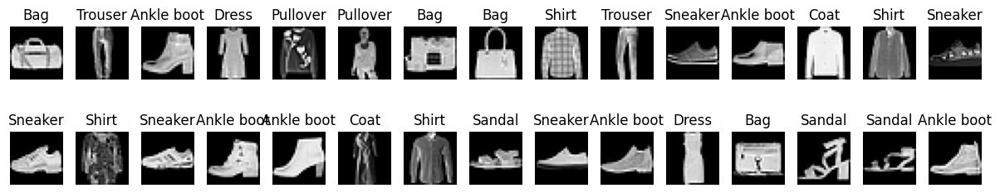

In [ ]:
# 1.1 Load Fashion-MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# 1.2 Preprocess
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32")  / 255.0
x_train = np.expand_dims(x_train, -1)
x_test  = np.expand_dims(x_test, -1)

num_classes = 10
class_names = ["T-shirt/top","Trouser","Pullover","Dress","Coat",
               "Sandal","Shirt","Sneaker","Bag","Ankle boot"]

# 1.3 Validation split
val_size = 5000
x_val, y_val = x_train[-val_size:], y_train[-val_size:]
x_train, y_train = x_train[:-val_size], y_train[:-val_size]

print("Train:", x_train.shape, y_train.shape)
print("Val  :", x_val.shape,   y_val.shape)
print("Test :", x_test.shape,  y_test.shape)


# sample show samples (Fig 1)
def fig1_samples(images, labels, n=10):
    plt.figure(figsize=(12, 3))
    idx = np.random.choice(len(images), n, replace=False)
    for i, j in enumerate(idx):
        plt.subplot(2, math.ceil(n/2), i+1)
        plt.imshow(images[j].squeeze(), cmap="gray")
        plt.title(class_names[labels[j]])
        plt.axis("off")
    plt.tight_layout(); plt.show()

fig1_samples(x_train, y_train, n=30)

##  2.Augmentation Models(A1-A4)

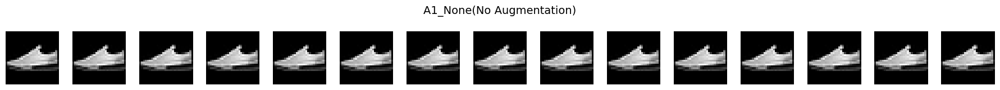

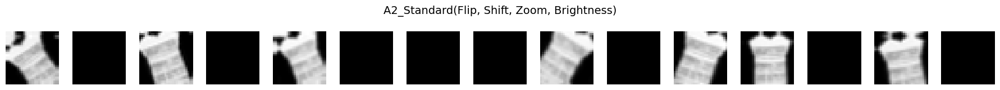

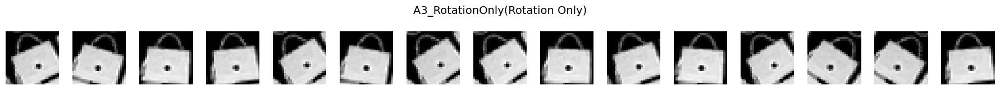

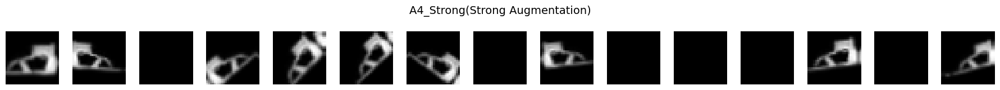

In [ ]:
# ----------  Augmentation pipelines (A1–A4) ----------
def aug_none():
    return keras.Sequential(name="aug_none", layers=[])

def aug_standard():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.10),
        layers.RandomTranslation(0.10, 0.10),
        layers.RandomZoom(0.10),
        layers.RandomBrightness(factor=0.10),
    ], name="aug_standard")

def aug_rotation_only():
    return keras.Sequential([layers.RandomRotation(0.10)], name="aug_rotation")

def aug_strong():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.15),
        layers.RandomTranslation(0.10, 0.10),
        layers.RandomZoom(0.15),
        layers.RandomBrightness(factor=0.15),
    ], name="aug_strong")

AUGS = {
    "A1_NoAugmentation":          None,
    "A2_Standard(Flip, Shift, Zoom, Brightness)":      aug_standard(),
    "A3_RotationOnly": aug_rotation_only(),
    "A4_StrongAugmentation":        aug_strong(),
}

# ---------- Augmentation previews for A1–A4 (Fig. 2a–2d) ----------
def fig2_aug_examples(aug, title="Augmentation Preview", n=10):
    img = x_train[np.random.randint(len(x_train))][None, ...]
    batch = np.repeat(img, n, axis=0)

    if aug is not None:
        out = aug(batch, training=True).numpy()
    else:
        out = batch  # No augmentation applied

    plt.figure(figsize=(n*1.2, 1.6))
    for i in range(n):
        plt.subplot(1, n, i+1)
        plt.imshow(out[i].squeeze(), cmap="gray")
        plt.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


# ---------- Generate Fig. 2a–2d ----------
fig2_aug_examples(AUGS["A1_NoAugmentation"],      title="A1_None(No Augmentation)", n=15)
fig2_aug_examples(AUGS["A2_Standard(Flip, Shift, Zoom, Brightness)"],  title="A2_Standard(Flip, Shift, Zoom, Brightness)", n=15)
fig2_aug_examples(AUGS["A3_RotationOnly"], title="A3_RotationOnly(Rotation Only)", n=15)
fig2_aug_examples(AUGS["A4_StrongAugmentation"],    title="A4_Strong(Strong Augmentation)", n=15)





## 3.Model Definitions (M1–M3)

In [ ]:

# ---------- 3.1 Baseline CNN (M1_cnn) ----------
def build_cnn(aug, lr):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    x = aug(x, training=True)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="Baseline CNN")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# ---------- 3.2 Deeper CNN (M2_deep) ----------
def build_deep_cnn(aug, lr):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    x = aug(x, training=True)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="Deeper CNN")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# ---------- 3.3 CNN with BatchNorm (M3_bn) ----------
def build_bn_cnn(aug, lr):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    x = aug(x, training=True)
    x = layers.Conv2D(32, 3)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(64, 3)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="CNN with BatchNorm")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model
    print("models defined")

## 4.Training Models

### 4.1 Training : LeNet-style CNN


Training Baseline CNN with aug=A1_NoAugmentation, batch=16, epochs=10, lr=0.0005, seed=42
Epoch 1/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.5466 - loss: 1.2350 - val_accuracy: 0.7494 - val_loss: 0.6522
Epoch 2/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.7487 - loss: 0.6634 - val_accuracy: 0.7836 - val_loss: 0.5783
Epoch 3/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.7808 - loss: 0.5901 - val_accuracy: 0.8006 - val_loss: 0.5272
Epoch 4/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8006 - loss: 0.5400 - val_accuracy: 0.8140 - val_loss: 0.4942
Epoch 5/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8152 - loss: 0.5036 - val_accuracy: 0.8262 - val_loss: 0.4706
Epoch 6/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8257 - loss: 0.4751 - val_accuracy: 0.8318 - val_loss: 0.4511
Epoch 7/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8340 - loss: 0.4519 - val_accuracy: 0.8332 - val_loss: 0.437

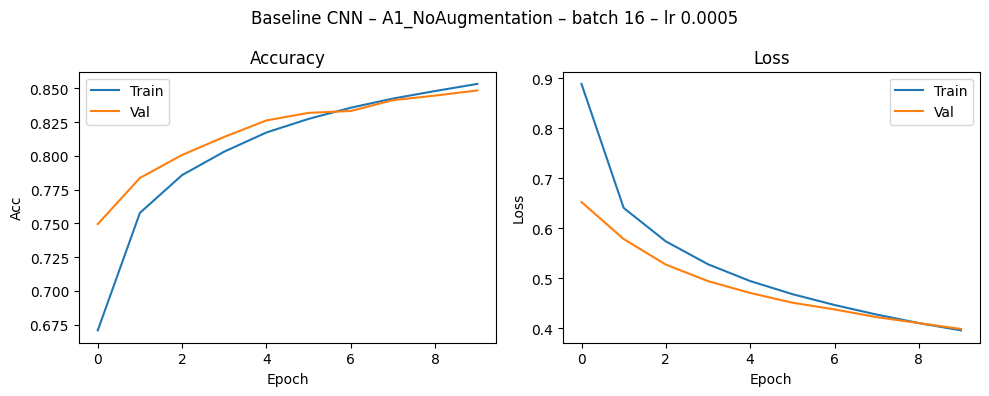

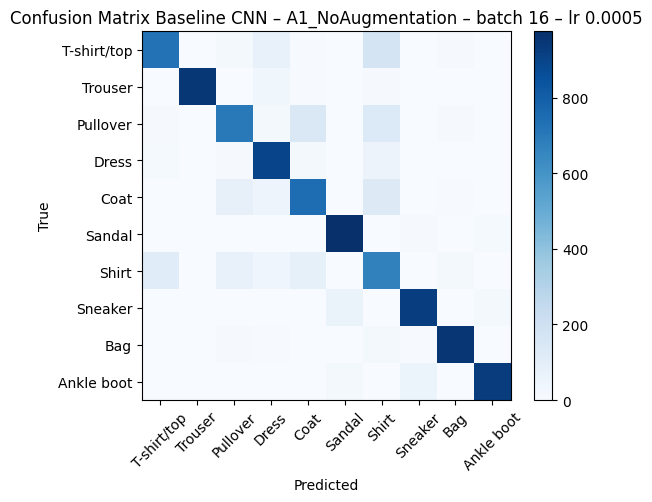


Training Baseline CNN with aug=A1_NoAugmentation, batch=32, epochs=10, lr=0.001, seed=42
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.5286 - loss: 1.2817 - val_accuracy: 0.7486 - val_loss: 0.6647
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7562 - loss: 0.6460 - val_accuracy: 0.7854 - val_loss: 0.5659
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7934 - loss: 0.5539 - val_accuracy: 0.8074 - val_loss: 0.5066
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8150 - loss: 0.5009 - val_accuracy: 0.8274 - val_loss: 0.4717
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8282 - loss: 0.4662 - val_accuracy: 0.8344 - val_loss: 0.4473
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8385 - loss: 0.4392 - val_accuracy: 0.8430 - val_loss: 0.4258
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8485 - loss: 0.4165 - val_accuracy: 0.8460 - val_loss: 0.4093


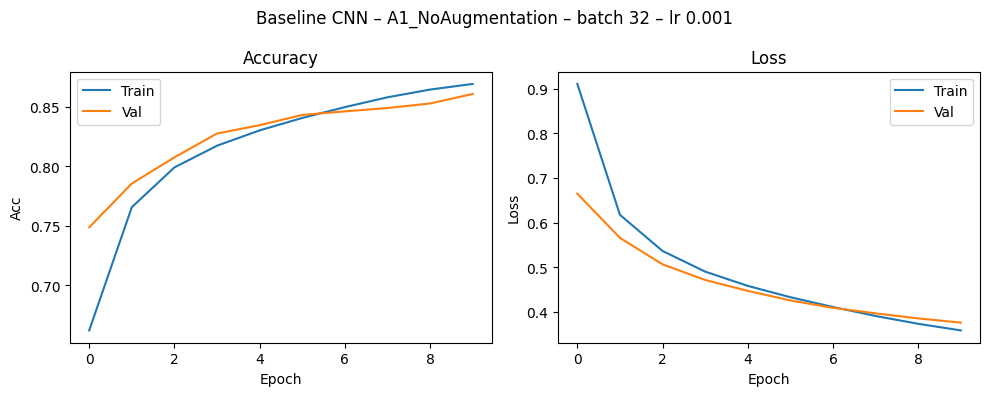

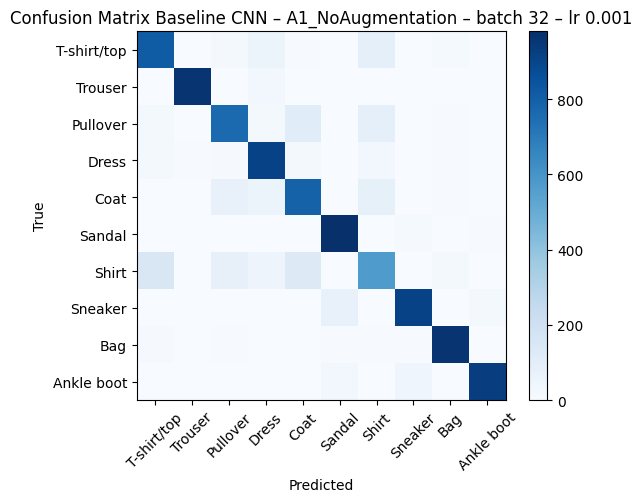


Training Baseline CNN with aug=A1_NoAugmentation, batch=64, epochs=10, lr=0.002, seed=42
Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.4991 - loss: 1.3566 - val_accuracy: 0.7068 - val_loss: 0.7406
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7325 - loss: 0.7076 - val_accuracy: 0.7428 - val_loss: 0.6778
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7559 - loss: 0.6405 - val_accuracy: 0.7596 - val_loss: 0.6052
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7802 - loss: 0.5821 - val_accuracy: 0.7818 - val_loss: 0.5503
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7981 - loss: 0.5359 - val_accuracy: 0.7964 - val_loss: 0.5091
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8135 - loss: 0.5007 - val_accuracy: 0.8138 - val_loss: 0.4767
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8241 - loss: 0.4743 - val_accuracy: 0.8282 - val_loss: 0.4524
Epoch 8/10
860

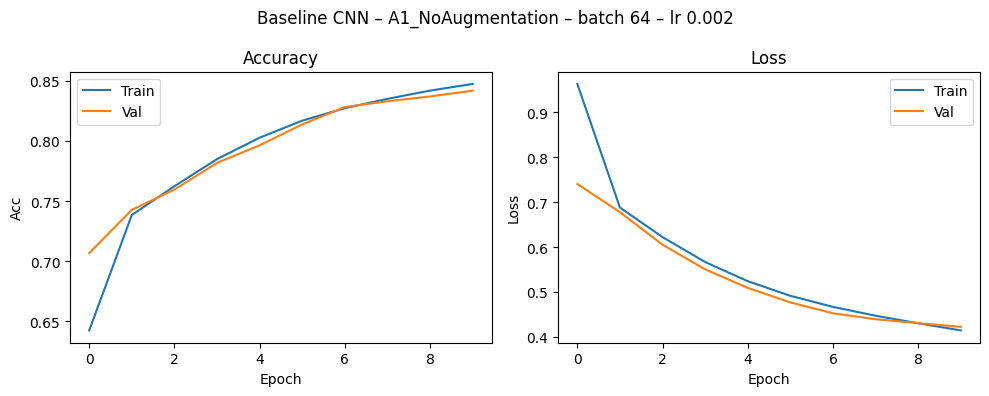

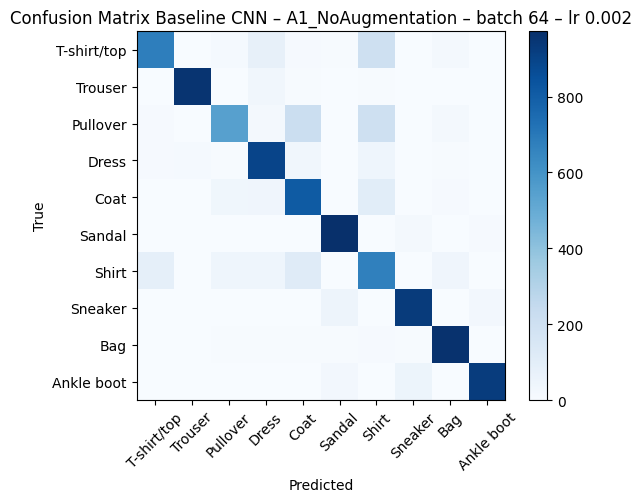


Training Baseline CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=16, epochs=10, lr=0.0005, seed=42
Epoch 1/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 5ms/step - accuracy: 0.4403 - loss: 1.5355 - val_accuracy: 0.7050 - val_loss: 0.7949
Epoch 2/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.6833 - loss: 0.8599 - val_accuracy: 0.7310 - val_loss: 0.7149
Epoch 3/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7088 - loss: 0.7794 - val_accuracy: 0.7340 - val_loss: 0.6922
Epoch 4/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7270 - loss: 0.7284 - val_accuracy: 0.7470 - val_loss: 0.6578
Epoch 5/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7361 - loss: 0.6996 - val_accuracy: 0.7524 - val_loss: 0.6362
Epoch 6/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7483 - loss: 0.6675 - val_accuracy: 0.7680 - val_loss: 0.6124
Epoch 7/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7550 - loss: 0.6470 - val_acc

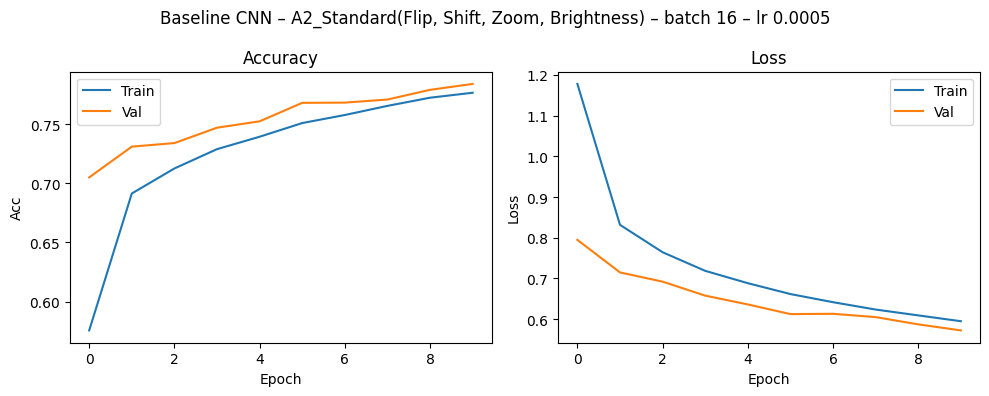

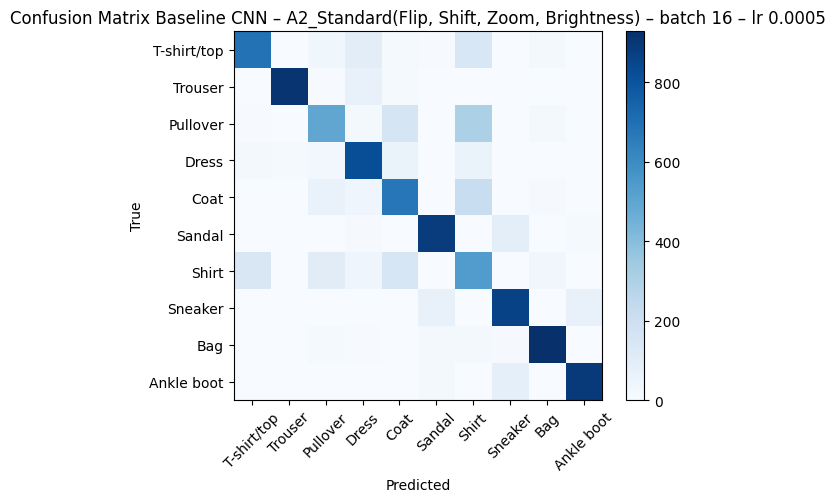


Training Baseline CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=32, epochs=10, lr=0.001, seed=42
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.3901 - loss: 1.6522 - val_accuracy: 0.6864 - val_loss: 0.8648
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6670 - loss: 0.9235 - val_accuracy: 0.7182 - val_loss: 0.7445
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7001 - loss: 0.8127 - val_accuracy: 0.7364 - val_loss: 0.6927
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7190 - loss: 0.7498 - val_accuracy: 0.7438 - val_loss: 0.6655
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7284 - loss: 0.7122 - val_accuracy: 0.7470 - val_loss: 0.6502
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7436 - loss: 0.6778 - val_accuracy: 0.7600 - val_loss: 0.6297
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7520 - loss: 0.6575 - val_accuracy: 

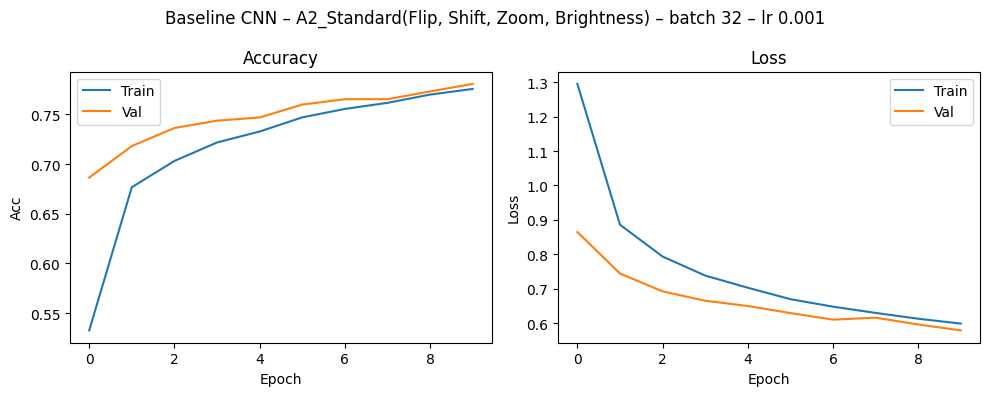

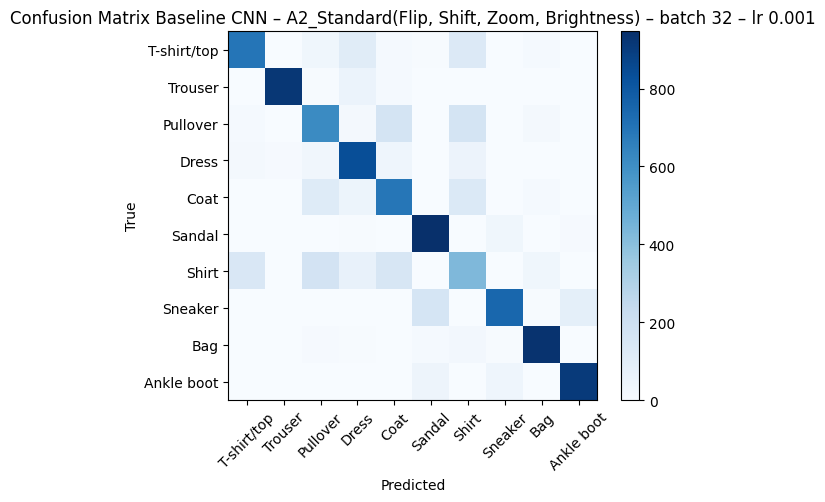


Training Baseline CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=64, epochs=10, lr=0.002, seed=42
Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.0971 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0962 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_lo

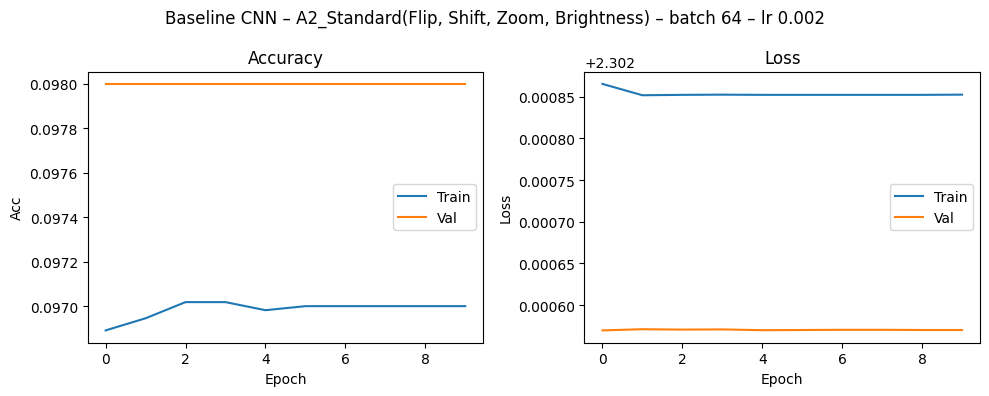

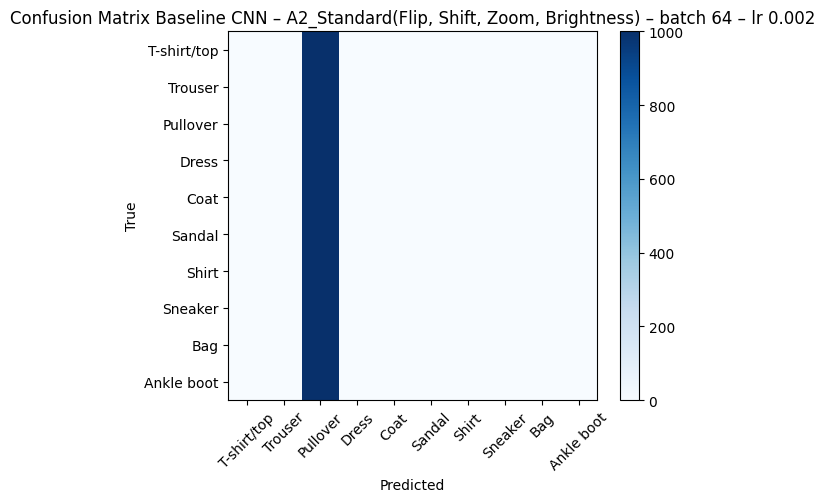


Training Baseline CNN with aug=A3_RotationOnly, batch=16, epochs=10, lr=0.0005, seed=42
Epoch 1/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.3740 - loss: 1.7087 - val_accuracy: 0.6068 - val_loss: 1.0706
Epoch 2/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.6235 - loss: 1.0446 - val_accuracy: 0.6528 - val_loss: 0.9523
Epoch 3/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.6617 - loss: 0.9324 - val_accuracy: 0.7032 - val_loss: 0.8549
Epoch 4/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.6841 - loss: 0.8683 - val_accuracy: 0.7272 - val_loss: 0.7944
Epoch 5/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7009 - loss: 0.8225 - val_accuracy: 0.7342 - val_loss: 0.7600
Epoch 6/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.7083 - loss: 0.7867 - val_accuracy: 0.7412 - val_loss: 0.7300
Epoch 7/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7194 - loss: 0.7642 - val_accuracy: 0.7366 - val_loss: 0

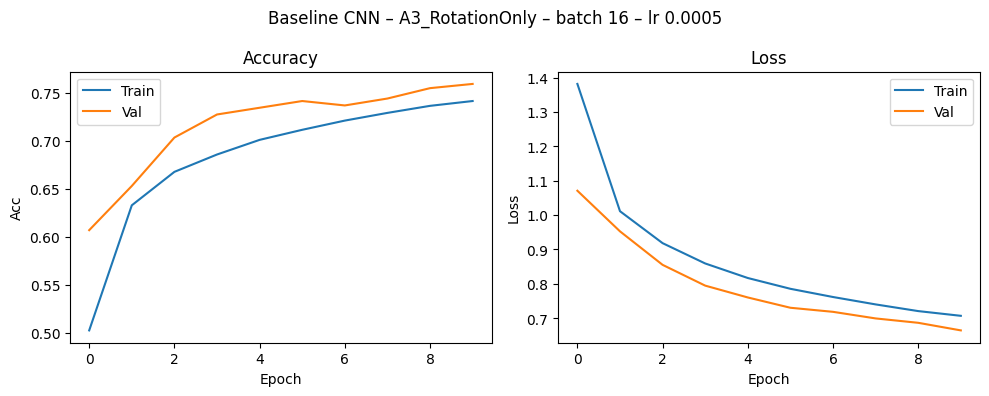

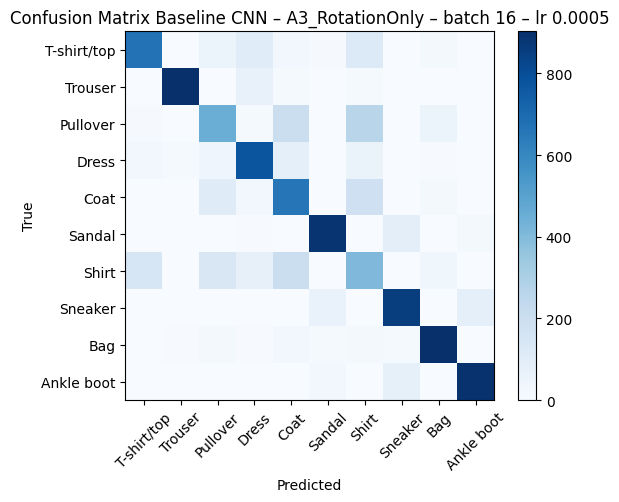


Training Baseline CNN with aug=A3_RotationOnly, batch=32, epochs=10, lr=0.001, seed=42
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.3454 - loss: 1.7527 - val_accuracy: 0.6384 - val_loss: 0.9988
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6262 - loss: 1.0207 - val_accuracy: 0.6780 - val_loss: 0.8637
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6731 - loss: 0.8839 - val_accuracy: 0.7152 - val_loss: 0.7862
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6982 - loss: 0.8158 - val_accuracy: 0.7294 - val_loss: 0.7434
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7148 - loss: 0.7768 - val_accuracy: 0.7354 - val_loss: 0.7225
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7235 - loss: 0.7435 - val_accuracy: 0.7502 - val_loss: 0.6991
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7331 - loss: 0.7232 - val_accuracy: 0.7588 - val_loss: 0.6688
E

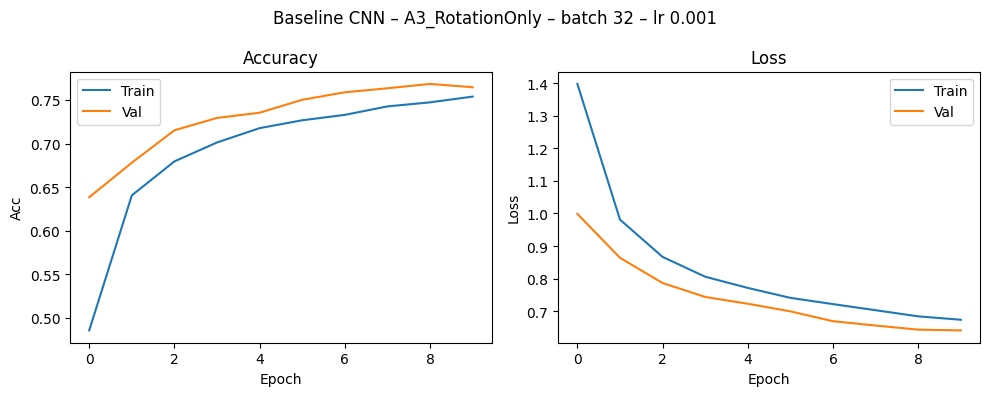

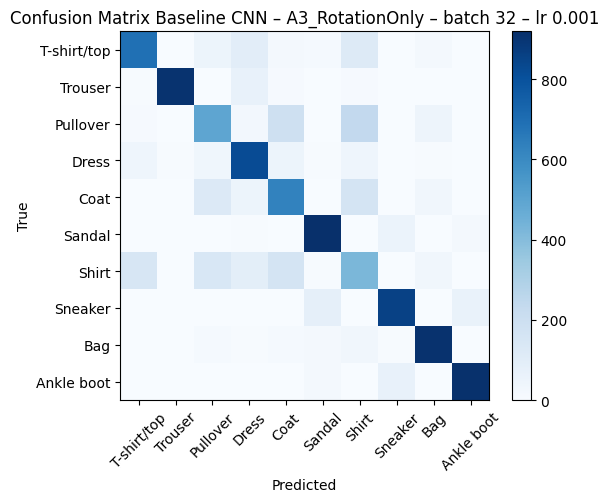


Training Baseline CNN with aug=A3_RotationOnly, batch=64, epochs=10, lr=0.002, seed=42
Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.3042 - loss: 1.8333 - val_accuracy: 0.6112 - val_loss: 1.0750
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6025 - loss: 1.0695 - val_accuracy: 0.6572 - val_loss: 0.9692
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6358 - loss: 0.9847 - val_accuracy: 0.6710 - val_loss: 0.9171
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6506 - loss: 0.9440 - val_accuracy: 0.6666 - val_loss: 0.9015
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6605 - loss: 0.9173 - val_accuracy: 0.6832 - val_loss: 0.8738
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6695 - loss: 0.8958 - val_accuracy: 0.6918 - val_loss: 0.8363
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6768 - loss: 0.8685 - val_accuracy: 0.6884 - val_loss: 0.8659
Epoch 8/10
860/8

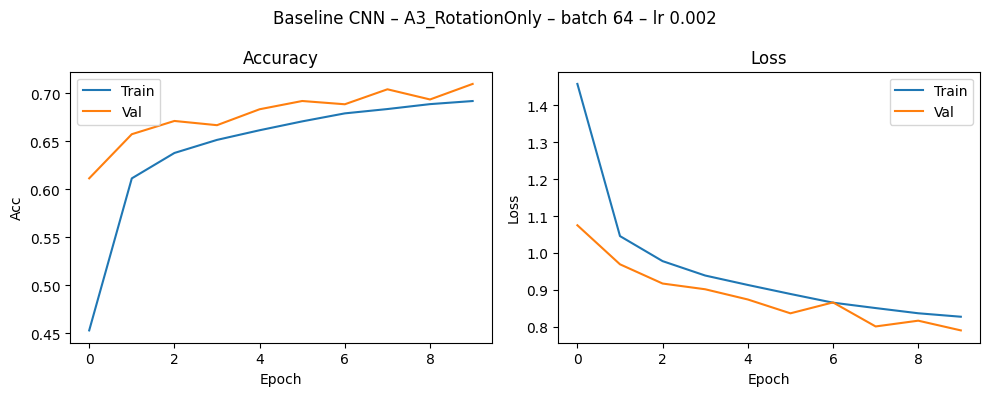

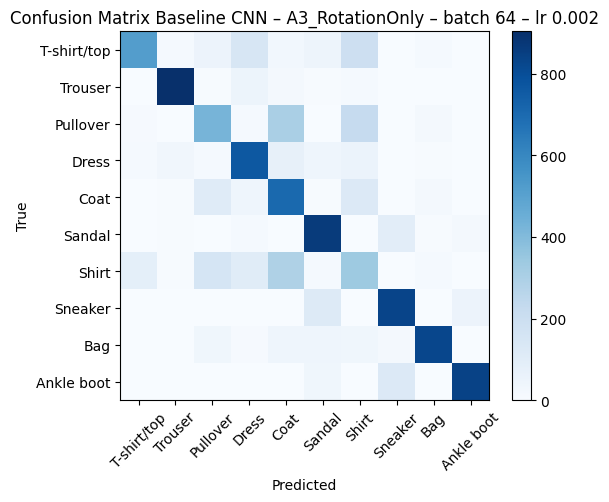


Training Baseline CNN with aug=A4_StrongAugmentation, batch=16, epochs=10, lr=0.0005, seed=42
Epoch 1/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - accuracy: 0.2987 - loss: 1.8926 - val_accuracy: 0.5942 - val_loss: 1.1297
Epoch 2/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.5681 - loss: 1.1846 - val_accuracy: 0.6452 - val_loss: 1.0023
Epoch 3/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.6089 - loss: 1.0651 - val_accuracy: 0.6676 - val_loss: 0.9239
Epoch 4/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.6290 - loss: 1.0099 - val_accuracy: 0.6700 - val_loss: 0.8814
Epoch 5/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.6421 - loss: 0.9651 - val_accuracy: 0.6760 - val_loss: 0.8651
Epoch 6/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.6553 - loss: 0.9342 - val_accuracy: 0.6916 - val_loss: 0.8271
Epoch 7/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.6608 - loss: 0.9096 - val_accuracy: 0.6852 - val_l

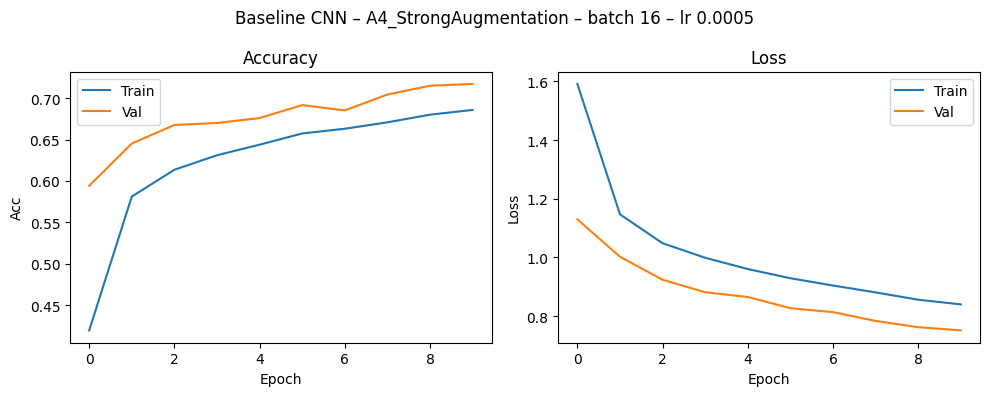

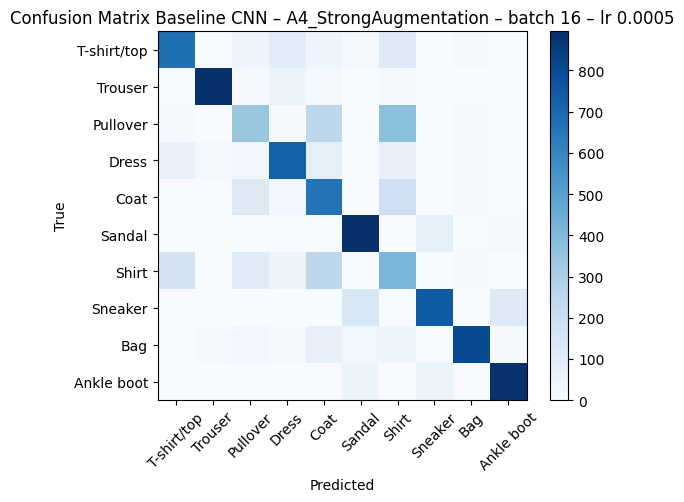


Training Baseline CNN with aug=A4_StrongAugmentation, batch=32, epochs=10, lr=0.001, seed=42
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.2783 - loss: 1.9502 - val_accuracy: 0.5918 - val_loss: 1.1243
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5740 - loss: 1.1615 - val_accuracy: 0.6220 - val_loss: 1.0222
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6098 - loss: 1.0517 - val_accuracy: 0.6574 - val_loss: 0.9179
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6284 - loss: 1.0022 - val_accuracy: 0.6714 - val_loss: 0.8938
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6433 - loss: 0.9638 - val_accuracy: 0.6772 - val_loss: 0.8528
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6507 - loss: 0.9340 - val_accuracy: 0.6736 - val_loss: 0.8375
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6589 - loss: 0.9164 - val_accuracy: 0.6770 - val_loss: 0.

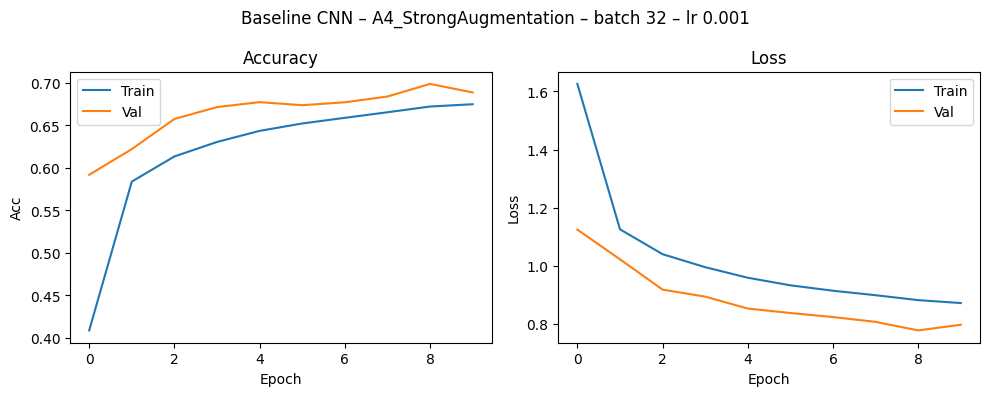

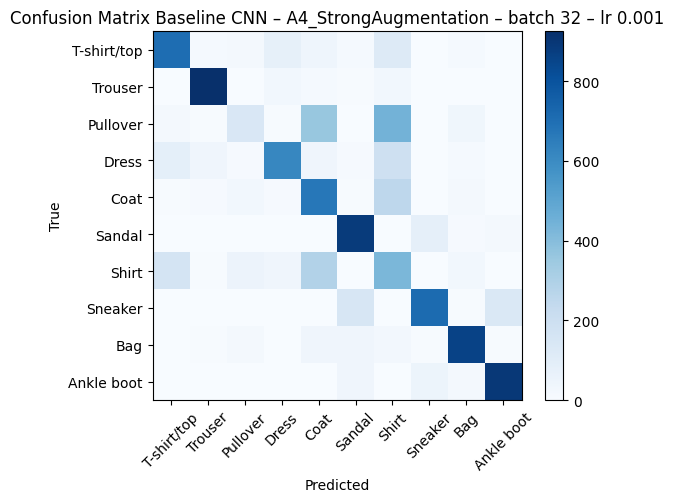


Training Baseline CNN with aug=A4_StrongAugmentation, batch=64, epochs=10, lr=0.002, seed=42
Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.0990 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.0967 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 8/10

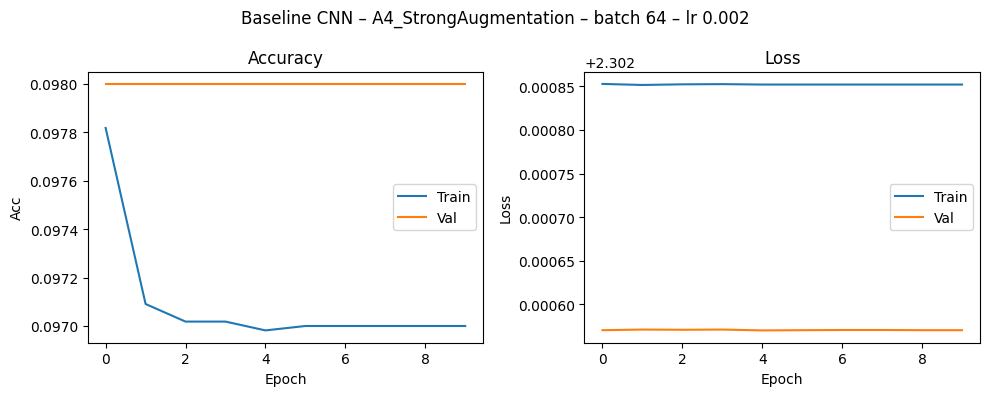

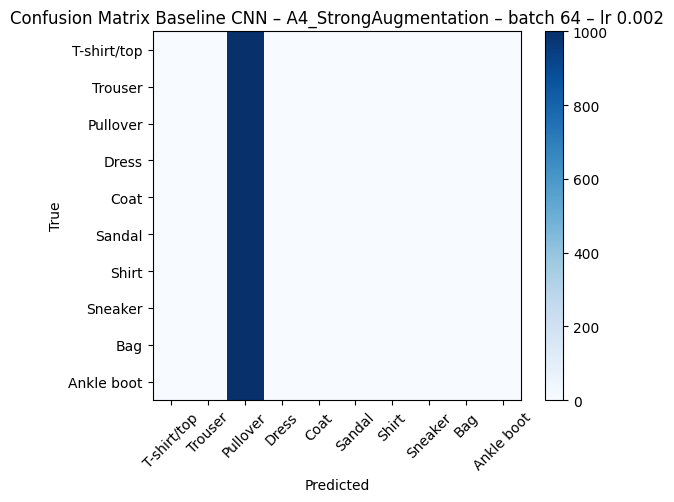

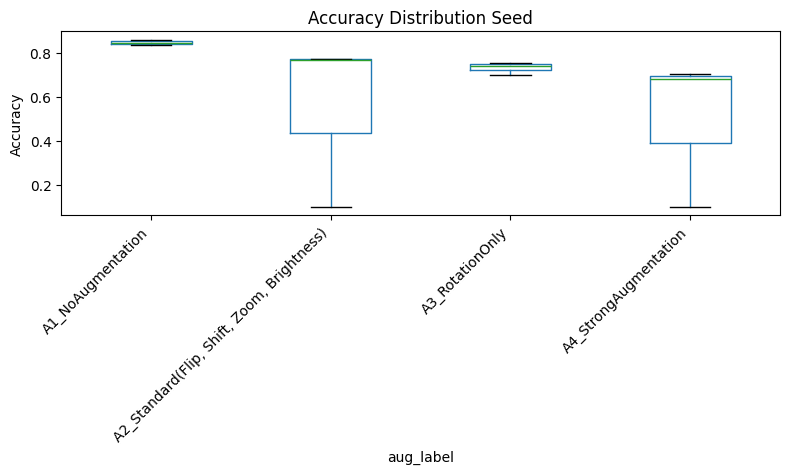

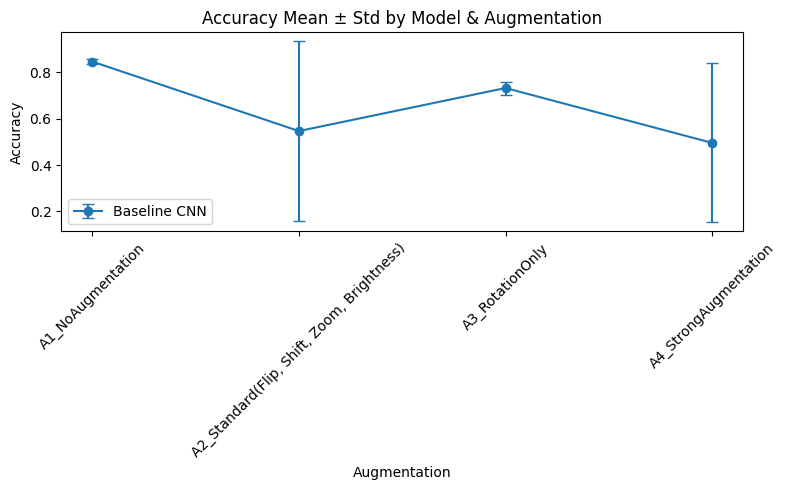


Metrics for Baseline CNN with A1_NoAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
0,42,0.846,0.847,0.005,10,8.24
1,42,0.859,0.857,0.008,10,4.56
2,42,0.834,0.833,0.006,10,2.70



Metrics for Baseline CNN with A2_Standard(Flip, Shift, Zoom, Brightness)


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
3,42,0.768,0.771,-0.007,10,17.39
4,42,0.772,0.771,-0.005,10,8.91
5,42,0.100,0.018,-0.001,1,4.58



Metrics for Baseline CNN with A3_RotationOnly


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
6,42,0.741,0.741,-0.018,10,16.70
7,42,0.755,0.754,-0.021,9,8.63
8,42,0.701,0.701,-0.018,10,4.44



Metrics for Baseline CNN with A4_StrongAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
9,42,0.705,0.707,-0.031,10,17.69
10,42,0.682,0.676,-0.027,9,9.18
11,42,0.100,0.018,-0.000,1,4.75


In [ ]:
# Part 4.1: Training, Evaluation, and Output Generation for Baseline CNN

# Initialize result containers
results = []
histories = {}
confusions = {}
trained_models = {}
# Define seed and parameter grid for Baseline CNN
SEEDS = [42]
PARAMS_M1 = [
    {"batch_size": 16, "epochs": 10, "lr": 5e-4},
    {"batch_size": 32, "epochs": 10, "lr": 1e-3},
    {"batch_size": 64, "epochs": 10, "lr": 2e-3}
]

# Define augmentation strategies
AUGS = {
    "A1_NoAugmentation": None,
    "A2_Standard(Flip, Shift, Zoom, Brightness)": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1)
    ]),
    "A3_RotationOnly": keras.Sequential([
        layers.RandomRotation(0.2)
    ]),
    "A4_StrongAugmentation": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2)
    ])
}


# Class labels for confusion matrix
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Model builder for Baseline CNN
def build_cnn(aug=None, lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    if aug is not None:
        x = aug(x, training=True)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="baseline_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Seed control for reproducibility
def set_seed(seed):
    import os, random
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

# Train model once with given config
def train_once(model, batch_size, max_epochs, seed, early_stop=False):
    set_seed(seed)
    callbacks = []
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True))
    start = time.time()
    hist = model.fit(x_train, y_train,
                     validation_data=(x_val, y_val),
                     batch_size=batch_size,
                     epochs=max_epochs,
                     verbose=1,
                     callbacks=callbacks)
    dur = time.time() - start
    best_ep = np.argmax(hist.history["val_accuracy"]) + 1
    return hist, dur, best_ep

# Evaluate model on test set
def eval_on_test(model):
    preds = model.predict(x_test, verbose=0)
    y_pred = np.argmax(preds, axis=1)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    cm = confusion_matrix(y_test, y_pred)
    return acc, f1, cm, y_pred

# Compute train–val accuracy gap
def train_val_gap(hist):
    best_ep = np.argmax(hist.history["val_accuracy"])
    train_acc = hist.history["accuracy"][best_ep]
    val_acc = hist.history["val_accuracy"][best_ep]
    return round(train_acc - val_acc, 3)

# Plot training history
def plot_history(hist, title="Training History"):
    # Check for valid history object
    if hist is None or not hasattr(hist, "history"):
        print("Invalid history object — skipping plot.")
        return

    keys = hist.history.keys()
    required_keys = ["accuracy", "val_accuracy", "loss", "val_loss"]
    missing = [k for k in required_keys if k not in keys]
    if missing:
        print(f"Missing keys in history: {missing} — skipping plot.")
        return
    # Create figure and suppress object display
    plt.figure(figsize=(10, 4));
  # Accuracy subplot
    plt.subplot(1, 2, 1)
    plt.plot(hist.history["accuracy"], label="Train")
    plt.plot(hist.history["val_accuracy"], label="Val")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Acc")
    plt.legend()
    # Loss subplot
    plt.subplot(1, 2, 2)
    plt.plot(hist.history["loss"], label="Train")
    plt.plot(hist.history["val_loss"], label="Val")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    # Final layout
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# Plot confusion matrix
def plot_confusion(cm, title="Confusion Matrix"):
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.colorbar()
    plt.xticks(ticks=np.arange(10), labels=class_names, rotation=45)
    plt.yticks(ticks=np.arange(10), labels=class_names)
    plt.tight_layout()
    plt.show()

# Plot accuracy distribution across seeds
def plot_box_accuracy(df):
    # Create a simplified label column for x-axis
    df["aug_label"] = df["aug"]
    fig, ax = plt.subplots(figsize=(8, 5))
    df.boxplot(column="acc", by="aug_label", grid=False, ax=ax)
    ax.set_title("Accuracy Distribution Seed")
    fig.suptitle("")  # remove default grouping title
    ax.set_ylabel("Accuracy")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    plt.show()

def plot_errorbar_accuracy(df):
    grouped = df.groupby(["model", "aug"])["acc"].agg(["mean", "std"]).reset_index()
    plt.figure(figsize=(8, 5))
    for model in grouped["model"].unique():
        subset = grouped[grouped["model"] == model]
        plt.errorbar(subset["aug"], subset["mean"], yerr=subset["std"], label=model, capsize=4, marker="o")
    plt.title("Accuracy Mean ± Std by Model & Augmentation")
    plt.ylabel("Accuracy")
    plt.xlabel("Augmentation")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Display metrics table for one augmentation
def table_metrics(df, model="Baseline CNN", aug="A2_standard (Flip, Shift, Zoom, Brightness)"):
    subset = df[(df["model"] == model) & (df["aug"] == aug)]
    print(f"\nMetrics for {model} with {aug}")
    display(subset[["seed", "acc", "macro_f1", "gap", "best_epoch", "sec_per_epoch"]])

# Display augmentation comparison table
def table_aug_comparison(df):
    grouped = df.groupby(["model", "aug"])[["acc", "macro_f1", "gap"]].agg(["mean", "std"])
    print("Augmentation Comparison Across Models")
    display(grouped.round(3))

# Run training loop for Baseline CNN across all configs × augmentations × seeds
for aug_key in AUGS:
    for config in PARAMS_M1:
        for seed in SEEDS:
            print(f"\nTraining Baseline CNN with aug={aug_key}, batch={config['batch_size']}, epochs={config['epochs']}, lr={config['lr']}, seed={seed}")

            model = build_cnn(aug=AUGS[aug_key], lr=config["lr"])
            hist, dur, best_ep = train_once(model,
                                            batch_size=config["batch_size"],
                                            max_epochs=config["epochs"],
                                            seed=seed,
                                            early_stop=False)
            acc, f1, cm, y_pred = eval_on_test(model)
            gap = train_val_gap(hist)

            results.append(dict(model="Baseline CNN", aug=aug_key,
                                batch=config["batch_size"], epochs=config["epochs"],
                                lr=config["lr"], seed=seed, early_stop=False,
                                acc=round(acc, 3), macro_f1=round(f1, 3),
                                gap=round(gap, 3), best_epoch=best_ep,
                                actual_epochs=len(hist.history["val_accuracy"]),
                                sec_per_epoch=round(dur/config["epochs"], 2)))

            if seed == 42:
                key = ("Baseline CNN", aug_key, config["batch_size"], config["epochs"], config["lr"])
                histories[key] = hist
                confusions[key] = cm
                trained_models[key] = model
                plot_history(hist, f"Baseline CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")
                plot_confusion(cm, f"Confusion Matrix Baseline CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")

# Create dataframe after training loop
df = pd.DataFrame(results)
df = df[["model", "aug", "seed", "batch", "epochs", "lr", "early_stop",
         "acc", "macro_f1", "gap", "best_epoch", "actual_epochs", "sec_per_epoch"]]
df = df.sort_values(by=["aug", "batch", "epochs", "lr", "seed"])

# Generate summary plots and tables
plot_box_accuracy(df)
plot_errorbar_accuracy(df)

# Display metrics tables for all augmentations
for aug_key in ["A1_NoAugmentation", "A2_Standard(Flip, Shift, Zoom, Brightness)", "A3_RotationOnly", "A4_StrongAugmentation"]:
    table_metrics(df, model="Baseline CNN", aug=aug_key)

df_baseline = df.copy()
# --- Add models to global_trained_models ---
if "global_trained_models" not in globals():
    global_trained_models = {}

df_local = df_baseline
for key, model in trained_models.items():
    model_name, aug_key, *_ = key
    if not df_local[(df_local["model"] == model_name) & (df_local["aug"] == aug_key) & (df_local["seed"] == 42)].empty:
        global_trained_models[(model_name, aug_key)] = model

### 4.2 Training : Deeper CNN


Training Deeper CNN with aug=A1_NoAugmentation, batch=16, epochs=15, lr=0.0005, seed=42
Epoch 1/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - accuracy: 0.0987 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.0971 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 3/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 4/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 5/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 6/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 7/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027


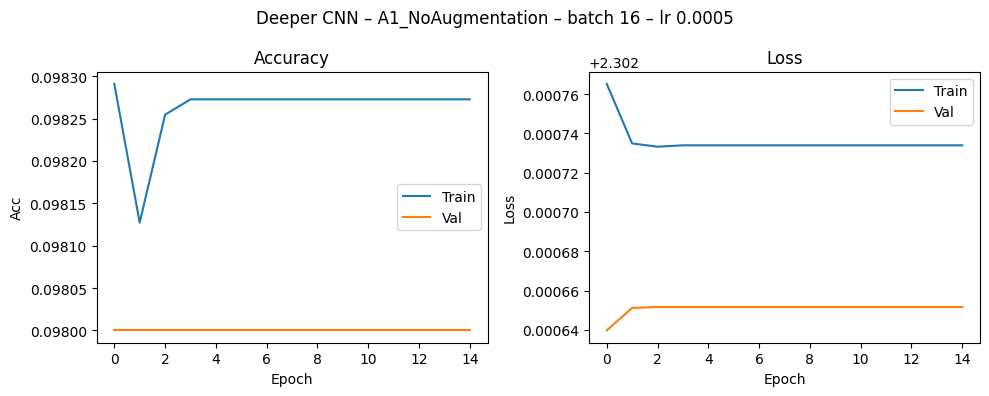

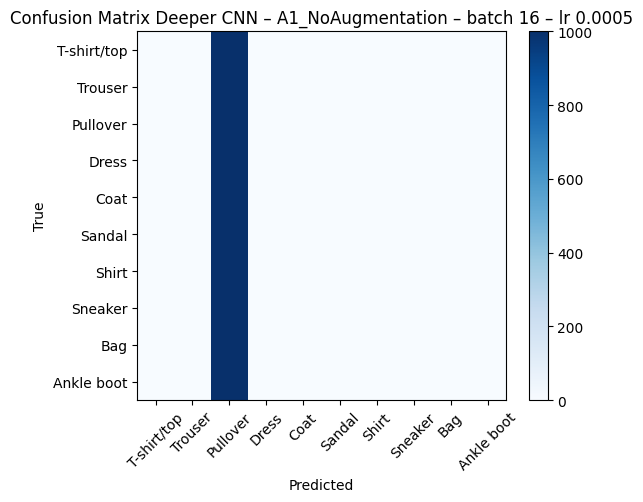


Training Deeper CNN with aug=A1_NoAugmentation, batch=32, epochs=15, lr=0.001, seed=42
Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.5487 - loss: 1.1902 - val_accuracy: 0.7846 - val_loss: 0.5672
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7805 - loss: 0.5723 - val_accuracy: 0.8248 - val_loss: 0.4657
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8304 - loss: 0.4623 - val_accuracy: 0.8450 - val_loss: 0.4152
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8548 - loss: 0.4038 - val_accuracy: 0.8526 - val_loss: 0.3867
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8660 - loss: 0.3683 - val_accuracy: 0.8680 - val_loss: 0.3632
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8741 - loss: 0.3413 - val_accuracy: 0.8690 - val_loss: 0.3434
Epoch 7/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8811 - loss: 0.3203 - val_accuracy: 0.8730 - val_loss: 0.3359
E

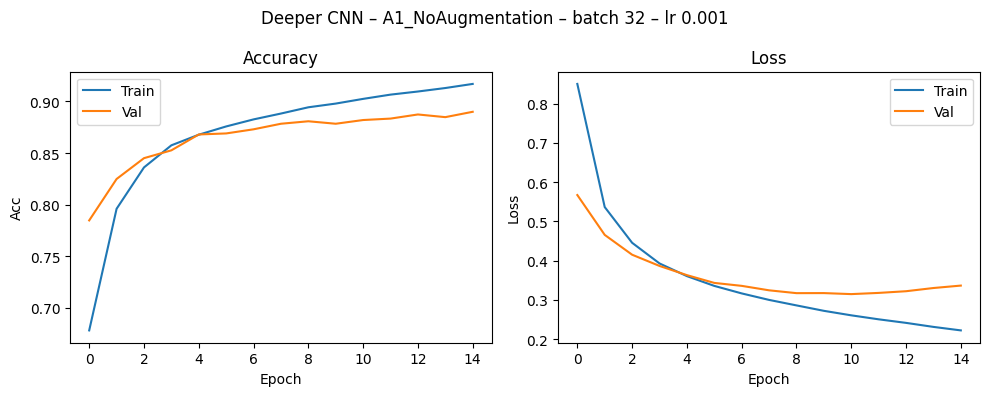

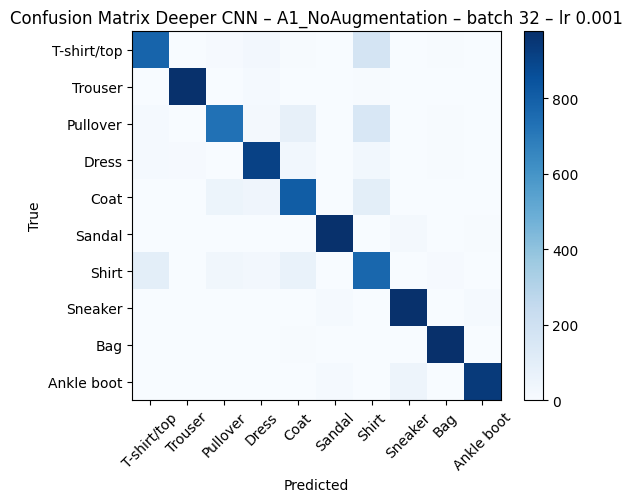


Training Deeper CNN with aug=A1_NoAugmentation, batch=64, epochs=15, lr=0.002, seed=42
Epoch 1/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.0994 - loss: 2.3030 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0963 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 8/15
860/8

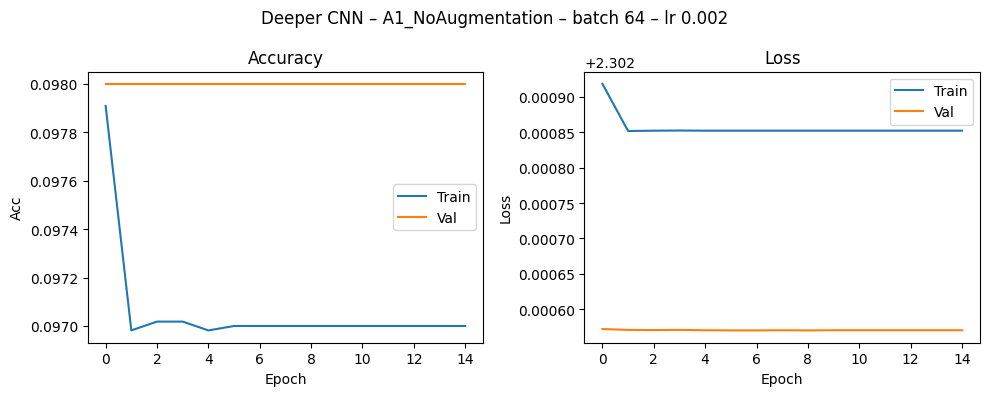

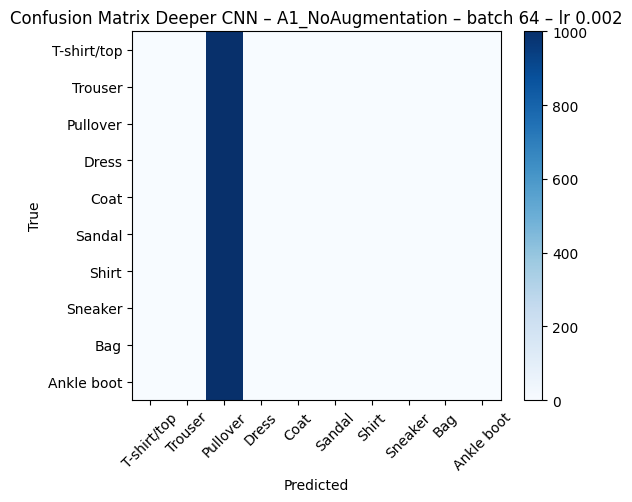


Training Deeper CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=16, epochs=15, lr=0.0005, seed=42
Epoch 1/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 22s 6ms/step - accuracy: 0.1000 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0976 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 3/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 4/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 5/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0976 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 6/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 7/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accur

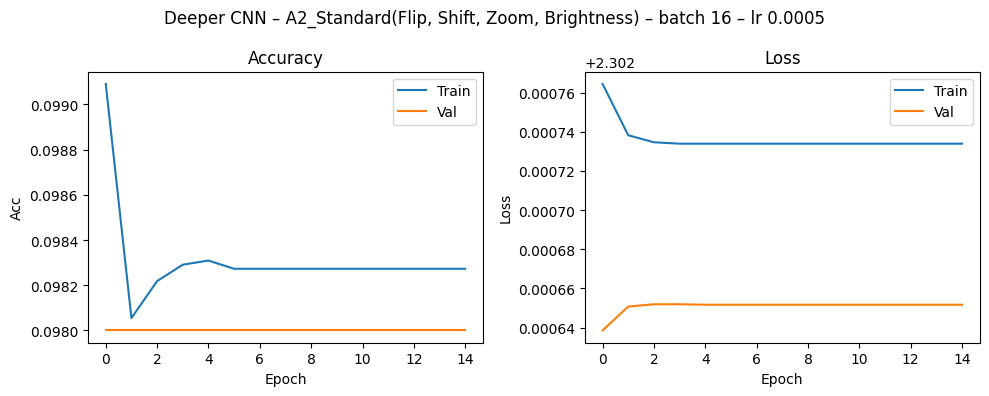

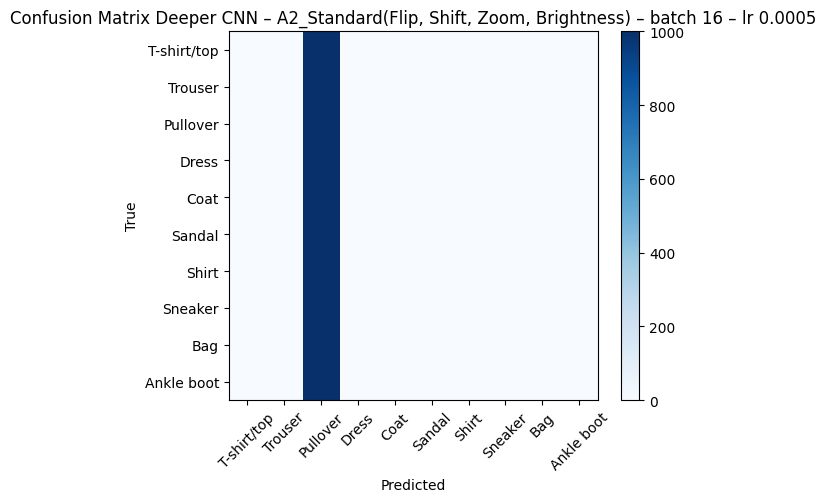


Training Deeper CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=32, epochs=15, lr=0.001, seed=42
Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.0988 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accura

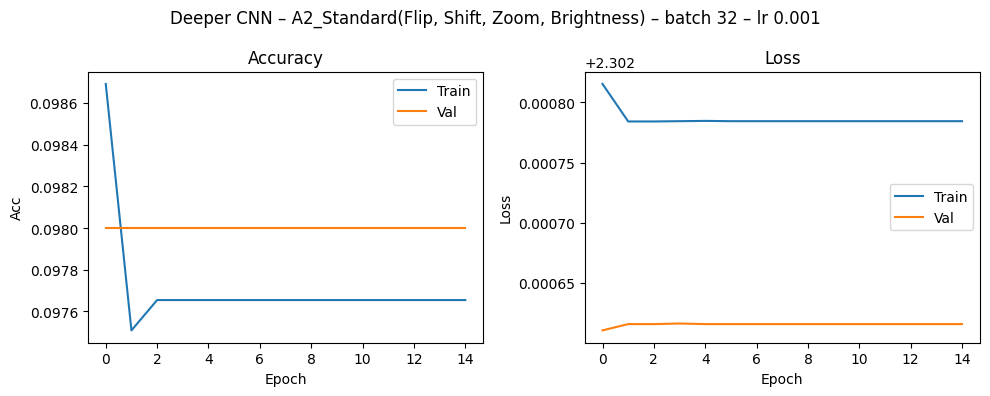

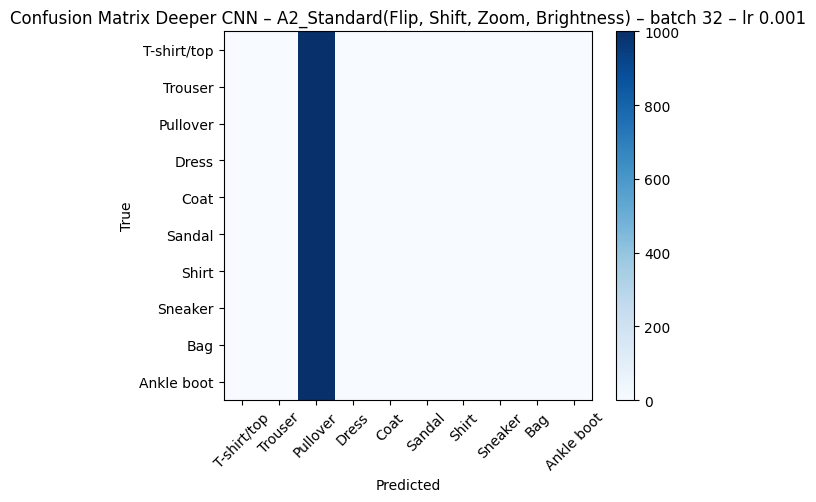


Training Deeper CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=64, epochs=15, lr=0.002, seed=42
Epoch 1/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.1000 - loss: 2.3032 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0963 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss

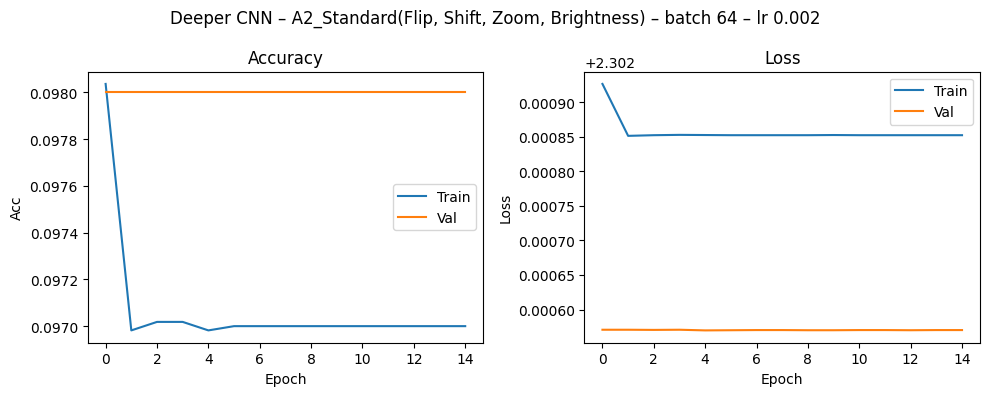

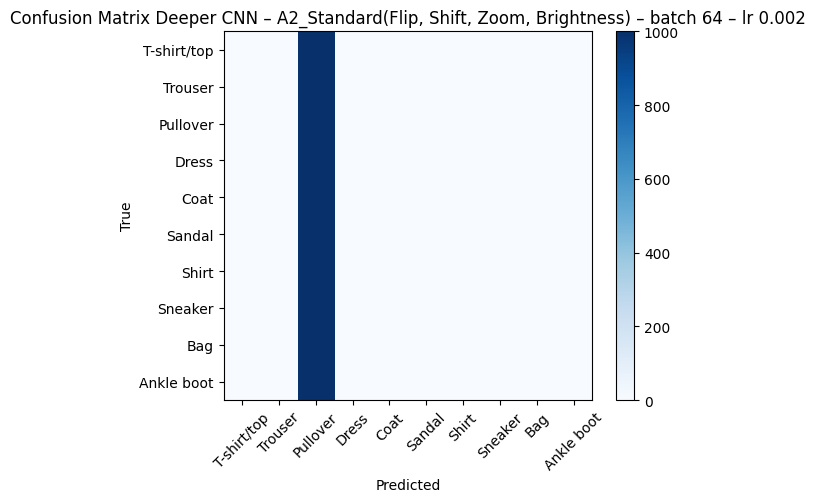


Training Deeper CNN with aug=A3_RotationOnly, batch=16, epochs=15, lr=0.0005, seed=42
Epoch 1/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 22s 6ms/step - accuracy: 0.0983 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0973 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 3/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0979 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 4/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 5/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0976 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 6/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 7/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3

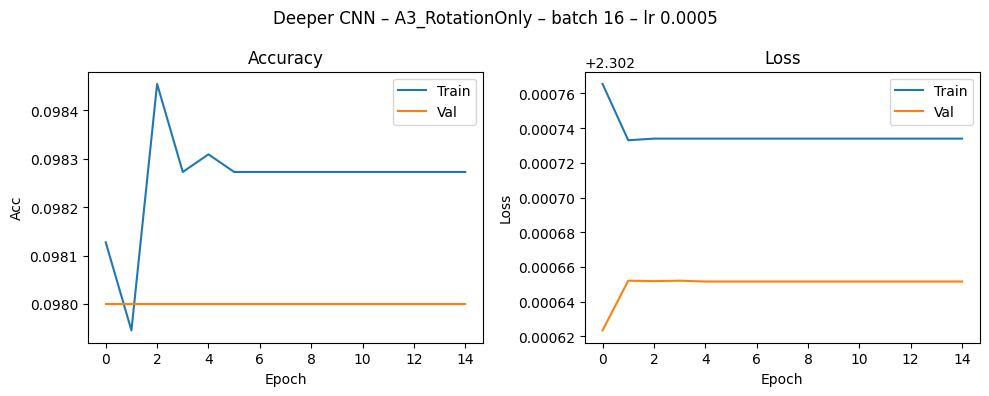

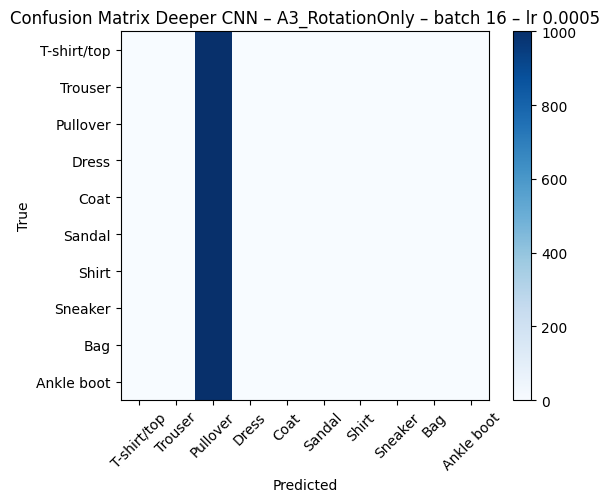


Training Deeper CNN with aug=A3_RotationOnly, batch=32, epochs=15, lr=0.001, seed=42
Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.0972 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0969 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.30

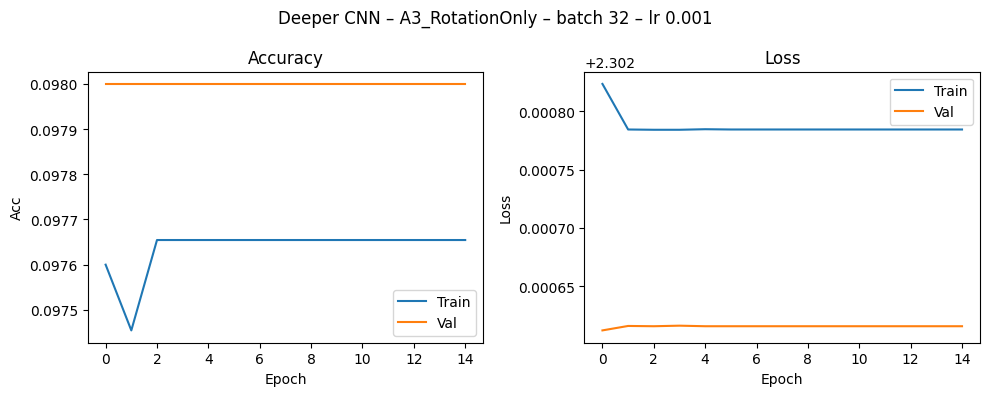

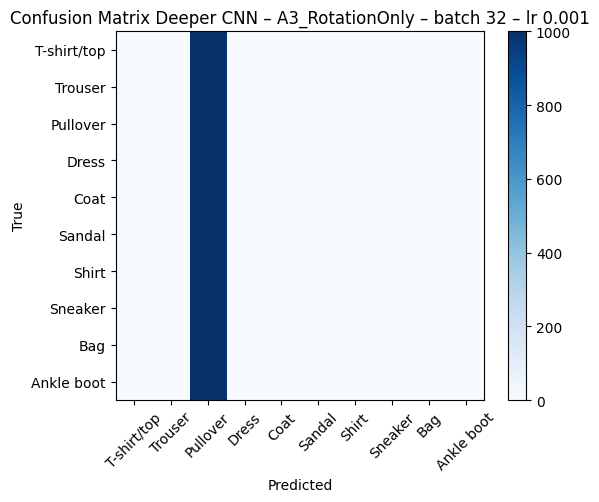


Training Deeper CNN with aug=A3_RotationOnly, batch=64, epochs=15, lr=0.002, seed=42
Epoch 1/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.0988 - loss: 2.3030 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0963 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 8/15
860/860

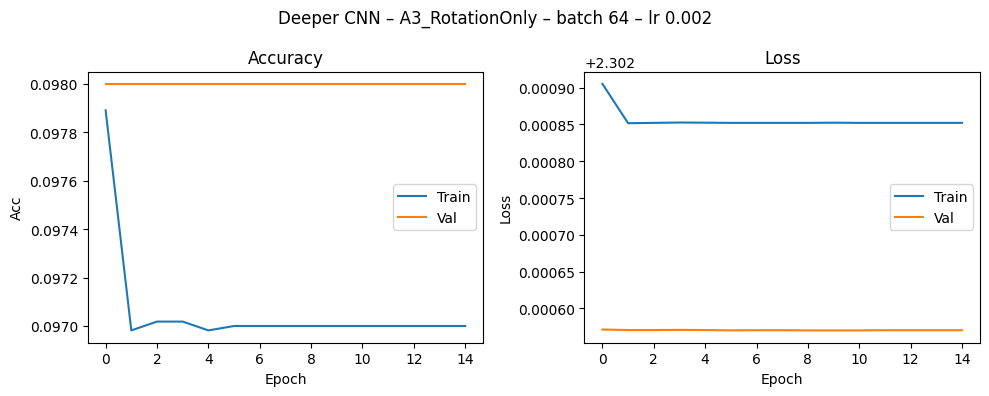

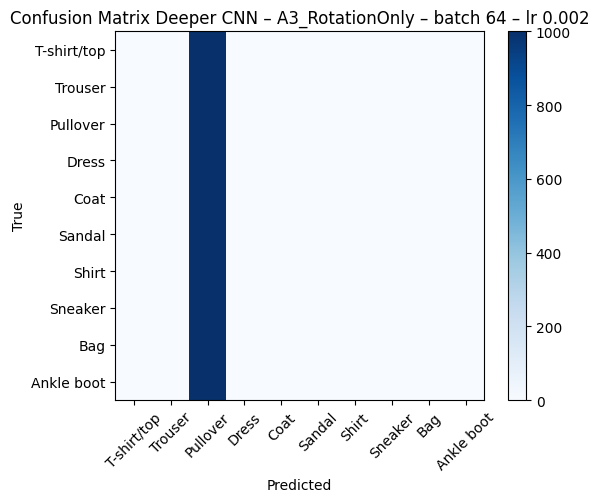


Training Deeper CNN with aug=A4_StrongAugmentation, batch=16, epochs=15, lr=0.0005, seed=42
Epoch 1/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 24s 6ms/step - accuracy: 0.0988 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0972 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 3/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 4/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 22s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 5/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 22s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 6/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 7/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_los

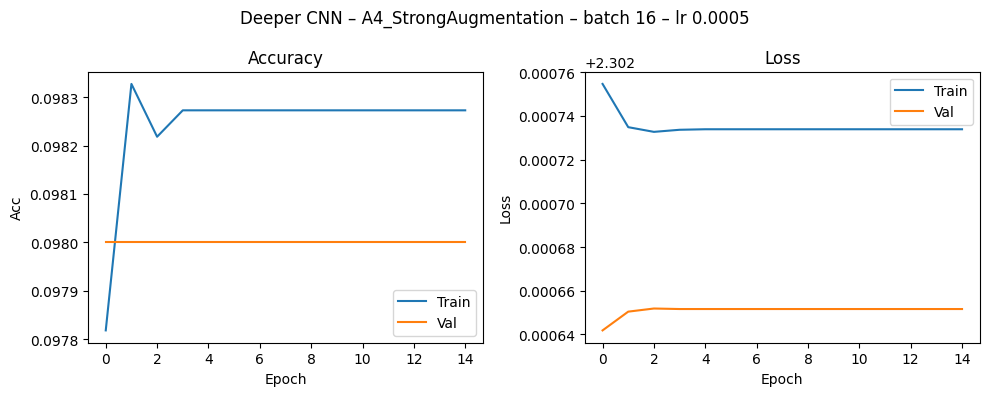

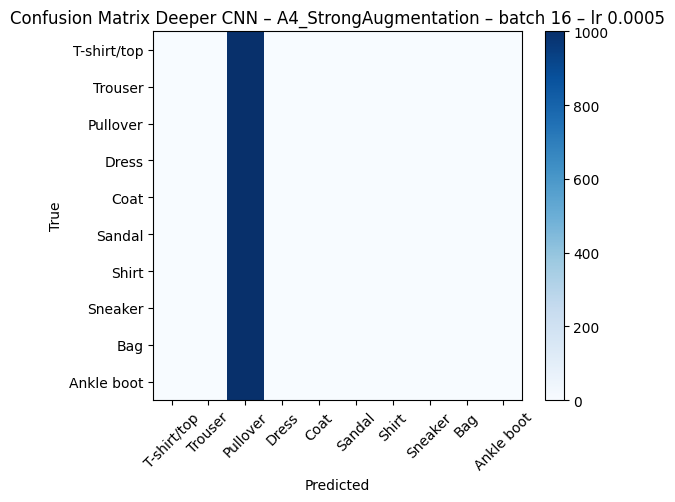


Training Deeper CNN with aug=A4_StrongAugmentation, batch=32, epochs=15, lr=0.001, seed=42
Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.0999 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0974 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss

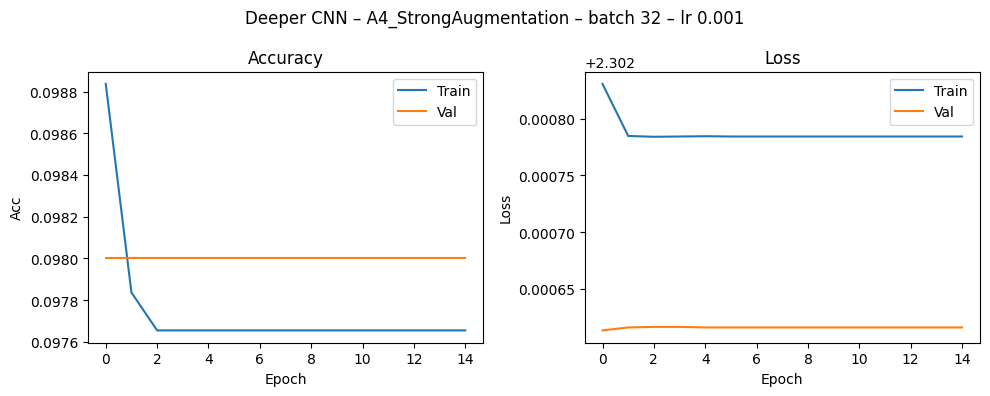

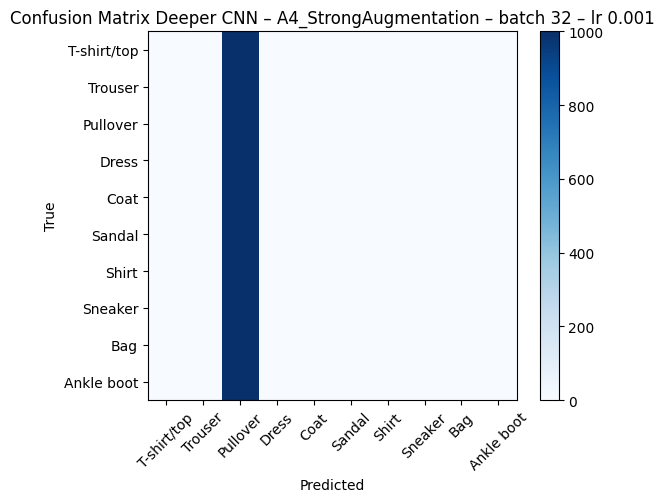


Training Deeper CNN with aug=A4_StrongAugmentation, batch=64, epochs=15, lr=0.002, seed=42
Epoch 1/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.0994 - loss: 2.3030 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0963 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 8/15
8

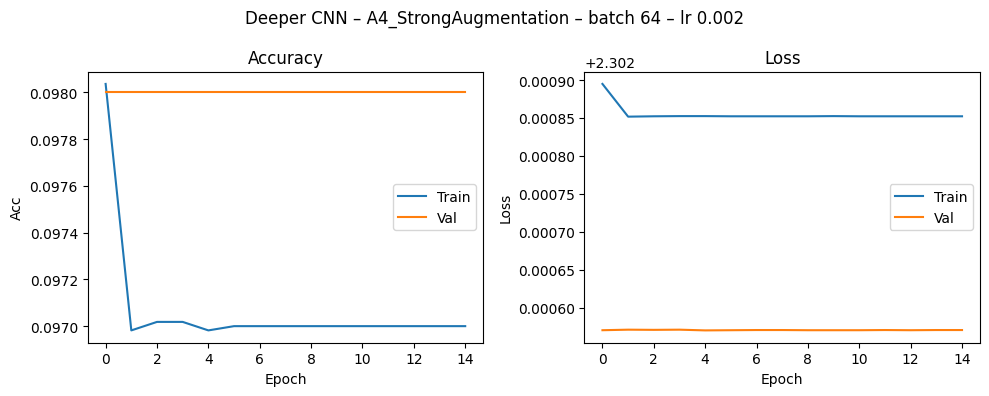

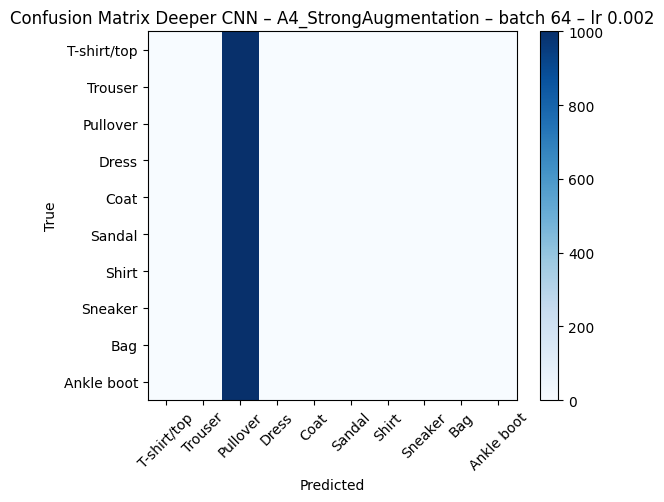

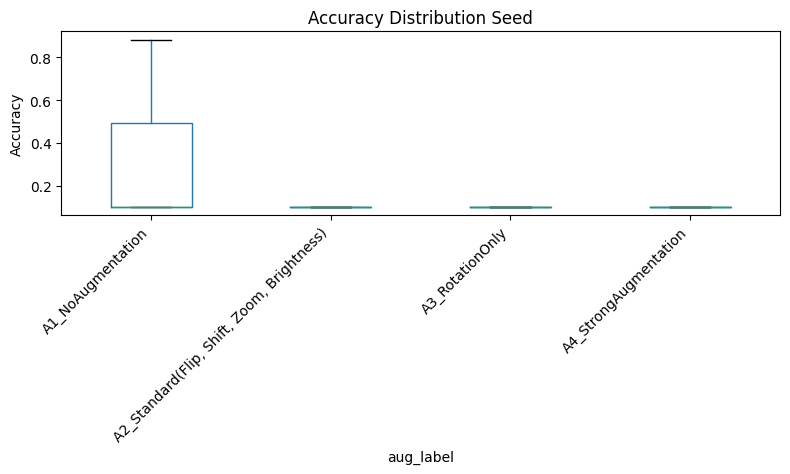

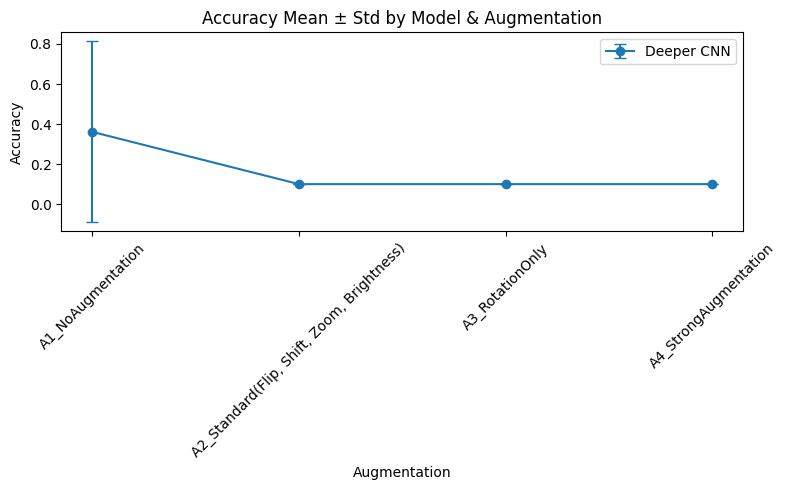


Metrics for Deeper CNN with A1_NoAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
0,42,0.100,0.018,0.000,1,9.19
1,42,0.883,0.885,0.027,15,5.07
2,42,0.100,0.018,-0.000,1,2.88



Metrics for Deeper CNN with A2_Standard(Flip, Shift, Zoom, Brightness)


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
3,42,0.1,0.018,0.001,1,20.49
4,42,0.1,0.018,0.001,1,10.52
5,42,0.1,0.018,0.000,1,5.44



Metrics for Deeper CNN with A3_RotationOnly


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
6,42,0.1,0.018,0.0,1,19.91
7,42,0.1,0.018,-0.0,1,10.41
8,42,0.1,0.018,-0.0,1,5.36



Metrics for Deeper CNN with A4_StrongAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
9,42,0.1,0.018,-0.000,1,21.67
10,42,0.1,0.018,0.001,1,10.94
11,42,0.1,0.018,0.000,1,5.63


In [ ]:
# 4.2 Deeper CNN: Training, Evaluation, and Output Generation
# Initialize result containers
results = []
histories = {}
confusions = {}
trained_models = {}

# Seed and parameter grid
SEEDS = [42]
PARAMS_M1 = [
    {"batch_size": 16, "epochs": 15, "lr": 5e-4},
    {"batch_size": 32, "epochs": 15, "lr": 1e-3},
    {"batch_size": 64, "epochs": 15, "lr": 2e-3}
]

# Augmentation strategies
AUGS = {
    "A1_NoAugmentation": None,
    "A2_Standard(Flip, Shift, Zoom, Brightness)": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1)
    ]),
    "A3_RotationOnly": keras.Sequential([
        layers.RandomRotation(0.2)
    ]),
    "A4_StrongAugmentation": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2)
    ])
}

# Class labels
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Model builder
def build_deeper_cnn(aug=None, lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    if aug is not None:
        x = aug(x, training=True)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="deeper_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Seed control
def set_seed(seed):
    import os, random
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

# Train once
def train_once(model, batch_size, max_epochs, seed, early_stop=False):
    set_seed(seed)
    callbacks = []
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True))
    start = time.time()
    hist = model.fit(x_train, y_train,
                     validation_data=(x_val, y_val),
                     batch_size=batch_size,
                     epochs=max_epochs,
                     verbose=1,
                     callbacks=callbacks)
    dur = time.time() - start
    best_ep = np.argmax(hist.history["val_accuracy"]) + 1
    return hist, dur, best_ep

# Evaluate
def eval_on_test(model):
    preds = model.predict(x_test, verbose=0)
    y_pred = np.argmax(preds, axis=1)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    cm = confusion_matrix(y_test, y_pred)
    return acc, f1, cm, y_pred

# Accuracy gap
def train_val_gap(hist):
    best_ep = np.argmax(hist.history["val_accuracy"])
    train_acc = hist.history["accuracy"][best_ep]
    val_acc = hist.history["val_accuracy"][best_ep]
    return round(train_acc - val_acc, 3)

# Plot history
def plot_history(hist, title="Training History"):
    if hist is None or not hasattr(hist, "history"):
        print("Invalid history object — skipping plot.")
        return
    keys = hist.history.keys()
    required_keys = ["accuracy", "val_accuracy", "loss", "val_loss"]
    missing = [k for k in required_keys if k not in keys]
    if missing:
        print(f"Missing keys in history: {missing} — skipping plot.")
        return
    plt.figure(figsize=(10, 4));
    plt.subplot(1, 2, 1)
    plt.plot(hist.history["accuracy"], label="Train")
    plt.plot(hist.history["val_accuracy"], label="Val")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Acc")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(hist.history["loss"], label="Train")
    plt.plot(hist.history["val_loss"], label="Val")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Plot confusion
def plot_confusion(cm, title="Confusion Matrix"):
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.colorbar()
    plt.xticks(ticks=np.arange(10), labels=class_names, rotation=45)
    plt.yticks(ticks=np.arange(10), labels=class_names)
    plt.tight_layout()
    plt.show()

# Box plot
def plot_box_accuracy(df):
    df["aug_label"] = df["aug"]
    fig, ax = plt.subplots(figsize=(8, 5))
    df.boxplot(column="acc", by="aug_label", grid=False, ax=ax)
    ax.set_title("Accuracy Distribution Seed")
    fig.suptitle("")
    ax.set_ylabel("Accuracy")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    plt.show()

# Error bar plot
def plot_errorbar_accuracy(df):
    grouped = df.groupby(["model", "aug"])["acc"].agg(["mean", "std"]).reset_index()
    plt.figure(figsize=(8, 5))
    for model in grouped["model"].unique():
        subset = grouped[grouped["model"] == model]
        plt.errorbar(subset["aug"], subset["mean"], yerr=subset["std"], label=model, capsize=4, marker="o")
    plt.title("Accuracy Mean ± Std by Model & Augmentation")
    plt.ylabel("Accuracy")
    plt.xlabel("Augmentation")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Metrics table
def table_metrics(df, model="Deeper CNN", aug="A2_Standard(Flip, Shift, Zoom, Brightness)"):
    subset = df[(df["model"] == model) & (df["aug"] == aug)]
    print(f"\nMetrics for {model} with {aug}")
    display(subset[["seed", "acc", "macro_f1", "gap", "best_epoch", "sec_per_epoch"]])

# Augmentation comparison
def table_aug_comparison(df):
    grouped = df.groupby(["model", "aug"])[["acc", "macro_f1", "gap"]].agg(["mean", "std"])
    print("Augmentation Comparison Across Models")
    display(grouped.round(3))

# Training loop
for aug_key in AUGS:
    for config in PARAMS_M1:
        for seed in SEEDS:
            print(f"\nTraining Deeper CNN with aug={aug_key}, batch={config['batch_size']}, epochs={config['epochs']}, lr={config['lr']}, seed={seed}")
            model = build_deeper_cnn(aug=AUGS[aug_key], lr=config["lr"])
            hist, dur, best_ep = train_once(model, config["batch_size"], config["epochs"], seed, early_stop=False)
            acc, f1, cm, y_pred = eval_on_test(model)
            gap = train_val_gap(hist)
            results.append(dict(model="Deeper CNN", aug=aug_key,
                                batch=config["batch_size"], epochs=config["epochs"],
                                lr=config["lr"], seed=seed, early_stop=False,
                                acc=round(acc, 3), macro_f1=round(f1, 3),
                                gap=round(gap, 3), best_epoch=best_ep,
                                actual_epochs=len(hist.history["val_accuracy"]),
                                sec_per_epoch=round(dur/config["epochs"], 2)))
            if seed == 42:
                key = ("Deeper CNN", aug_key, config["batch_size"], config["epochs"], config["lr"])
                histories[key] = hist
                confusions[key] = cm
                trained_models[key] = model
                plot_history(hist, f"Deeper CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")
                plot_confusion(cm, f"Confusion Matrix Deeper CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")

# Create dataframe after training loop
df = pd.DataFrame(results)
df = df[["model", "aug", "seed", "batch", "epochs", "lr", "early_stop",
         "acc", "macro_f1", "gap", "best_epoch", "actual_epochs", "sec_per_epoch"]]
df = df.sort_values(by=["aug", "batch", "epochs", "lr", "seed"])

# Generate summary plots and tables
plot_box_accuracy(df)
plot_errorbar_accuracy(df)

# Display metrics tables for all augmentations
for aug_key in ["A1_NoAugmentation", "A2_Standard(Flip, Shift, Zoom, Brightness)", "A3_RotationOnly", "A4_StrongAugmentation"]:
    table_metrics(df, model="Deeper CNN", aug=aug_key)
df_deeper = df.copy()

# --- Add models to global_trained_models ---
if "global_trained_models" not in globals():
    global_trained_models = {}

df_local = df_deeper
for key, model in trained_models.items():
    model_name, aug_key, *_ = key
    if not df_local[(df_local["model"] == model_name) & (df_local["aug"] == aug_key) & (df_local["seed"] == 42)].empty:
        global_trained_models[(model_name, aug_key)] = model



### 4.3 Traning : BatchNorm CNN


Training BatchNorm CNN with aug=A1_NoAugmentation, batch=16, epochs=20, lr=0.0005, seed=42
Epoch 1/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.8012 - loss: 0.5701 - val_accuracy: 0.8440 - val_loss: 0.4216
Epoch 2/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8816 - loss: 0.3254 - val_accuracy: 0.7984 - val_loss: 0.7188
Epoch 3/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9038 - loss: 0.2680 - val_accuracy: 0.8746 - val_loss: 0.3381
Epoch 4/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9186 - loss: 0.2261 - val_accuracy: 0.8484 - val_loss: 0.4326
Epoch 5/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9333 - loss: 0.1862 - val_accuracy: 0.2594 - val_loss: 4.1295
Epoch 6/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9432 - loss: 0.1580 - val_accuracy: 0.8538 - val_loss: 0.4923
Epoch 7/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9536 - loss: 0.1286 - val_accuracy: 0.3382 - val_loss

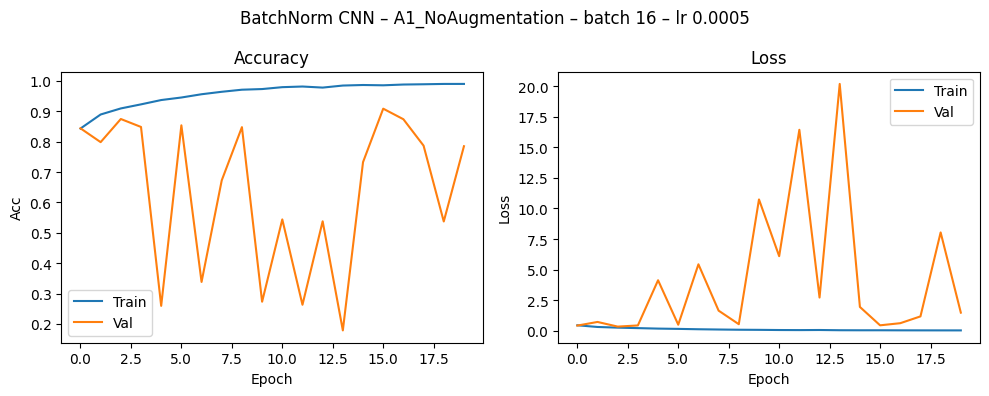

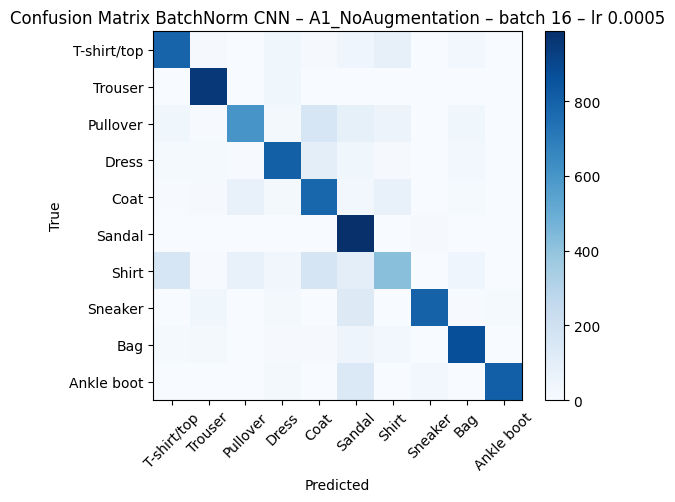


Training BatchNorm CNN with aug=A1_NoAugmentation, batch=32, epochs=20, lr=0.001, seed=42
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.8083 - loss: 0.5412 - val_accuracy: 0.8772 - val_loss: 0.3404
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8879 - loss: 0.3027 - val_accuracy: 0.8716 - val_loss: 0.3760
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9093 - loss: 0.2488 - val_accuracy: 0.8996 - val_loss: 0.2699
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9242 - loss: 0.2088 - val_accuracy: 0.8718 - val_loss: 0.3583
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9360 - loss: 0.1774 - val_accuracy: 0.9012 - val_loss: 0.2802
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9487 - loss: 0.1437 - val_accuracy: 0.9040 - val_loss: 0.2911
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9579 - loss: 0.1177 - val_accuracy: 0.8996 - val_loss: 0.327

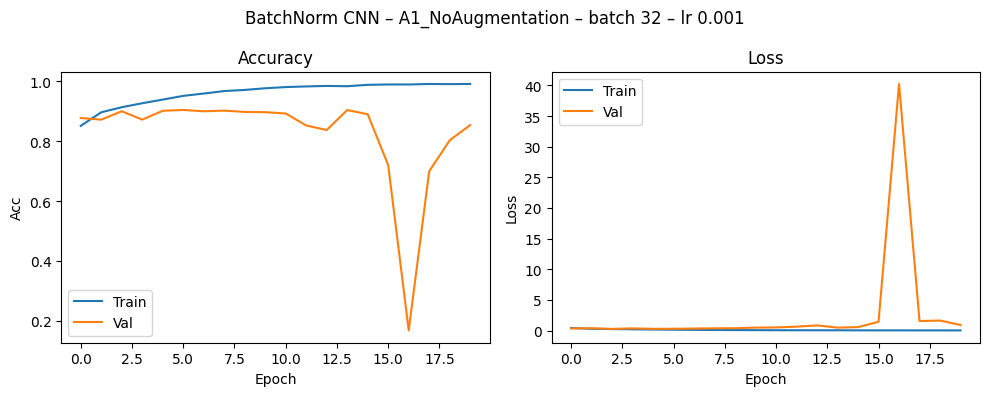

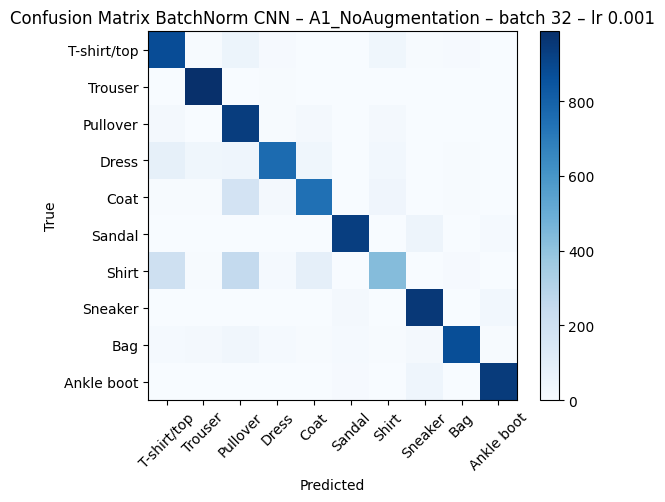


Training BatchNorm CNN with aug=A1_NoAugmentation, batch=64, epochs=20, lr=0.002, seed=42
Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8066 - loss: 0.5443 - val_accuracy: 0.8180 - val_loss: 0.5219
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8885 - loss: 0.3030 - val_accuracy: 0.8702 - val_loss: 0.3829
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9093 - loss: 0.2479 - val_accuracy: 0.8952 - val_loss: 0.2749
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9209 - loss: 0.2147 - val_accuracy: 0.9020 - val_loss: 0.2718
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9305 - loss: 0.1880 - val_accuracy: 0.8840 - val_loss: 0.3197
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9413 - loss: 0.1594 - val_accuracy: 0.8882 - val_loss: 0.3574
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9496 - loss: 0.1379 - val_accuracy: 0.9166 - val_loss: 0.2707
Epoch 8/20
8

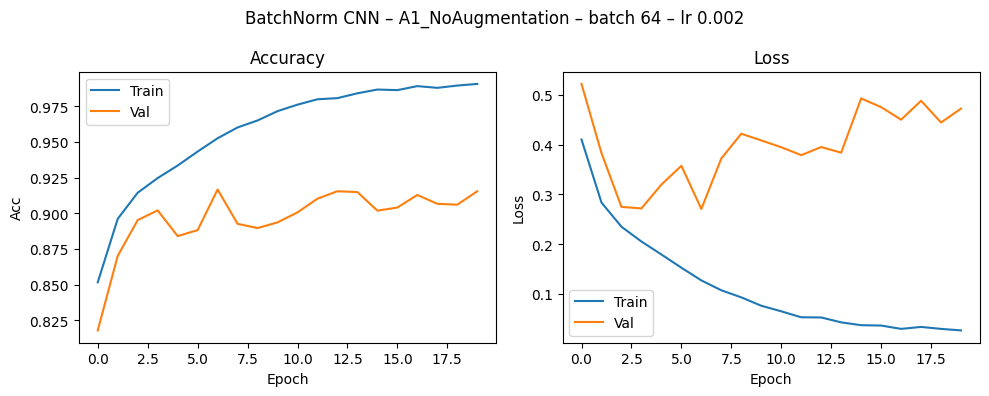

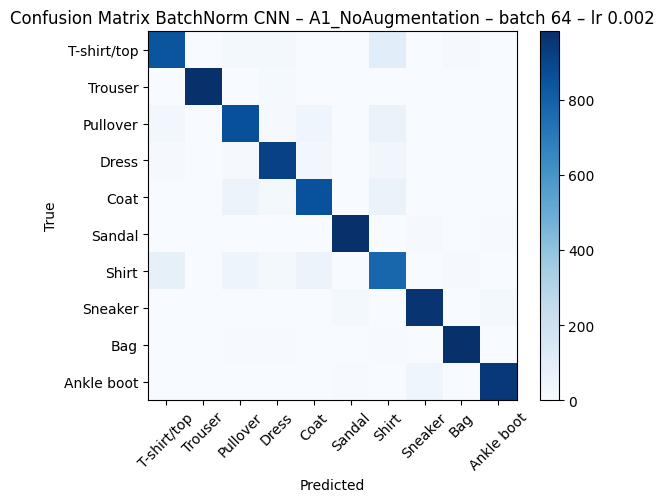


Training BatchNorm CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=16, epochs=20, lr=0.0005, seed=42
Epoch 1/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 39s 10ms/step - accuracy: 0.7173 - loss: 0.8074 - val_accuracy: 0.7910 - val_loss: 0.5665
Epoch 2/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8268 - loss: 0.4907 - val_accuracy: 0.7798 - val_loss: 0.5923
Epoch 3/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8499 - loss: 0.4186 - val_accuracy: 0.7352 - val_loss: 0.7426
Epoch 4/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8619 - loss: 0.3819 - val_accuracy: 0.8564 - val_loss: 0.4023
Epoch 5/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8726 - loss: 0.3551 - val_accuracy: 0.8420 - val_loss: 0.4284
Epoch 6/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 34s 10ms/step - accuracy: 0.8778 - loss: 0.3382 - val_accuracy: 0.7262 - val_loss: 1.2154
Epoch 7/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8848 - loss: 0.3209 -

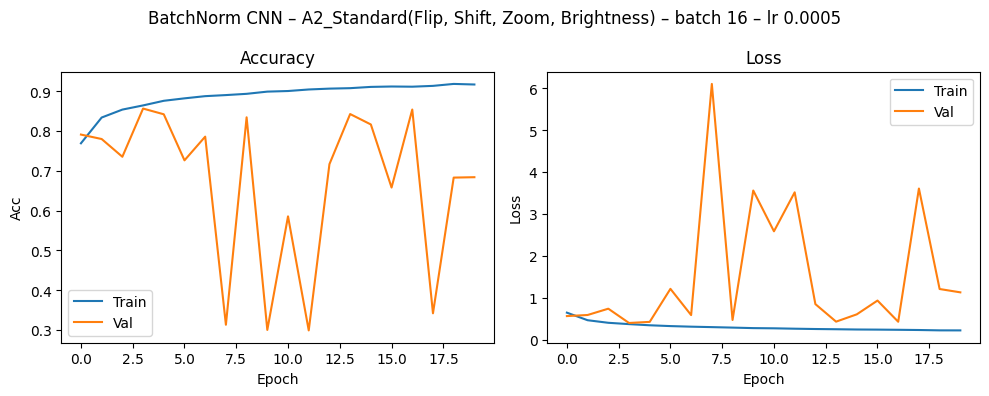

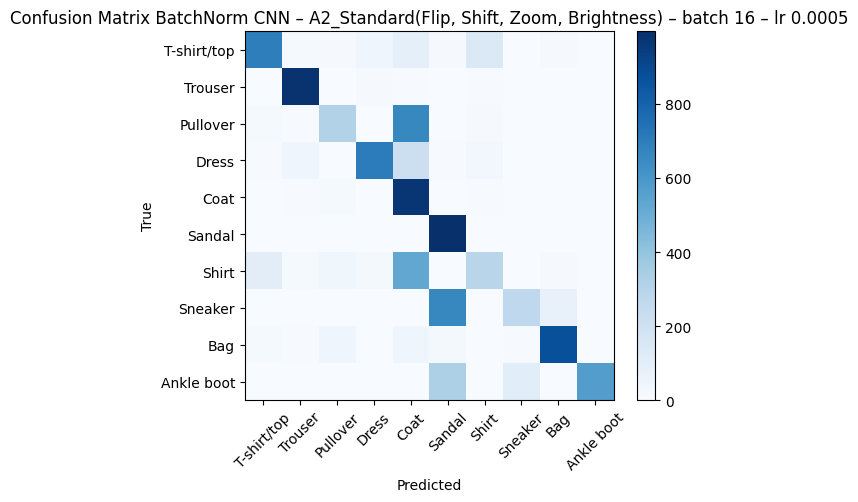


Training BatchNorm CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=32, epochs=20, lr=0.001, seed=42
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - accuracy: 0.7302 - loss: 0.7608 - val_accuracy: 0.8180 - val_loss: 0.5269
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8329 - loss: 0.4565 - val_accuracy: 0.8538 - val_loss: 0.4044
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8588 - loss: 0.3882 - val_accuracy: 0.7838 - val_loss: 0.6032
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8703 - loss: 0.3642 - val_accuracy: 0.8252 - val_loss: 0.4941
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8781 - loss: 0.3340 - val_accuracy: 0.8390 - val_loss: 0.4300
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8859 - loss: 0.3145 - val_accuracy: 0.8590 - val_loss: 0.3925
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8886 - loss: 0.2991 - 

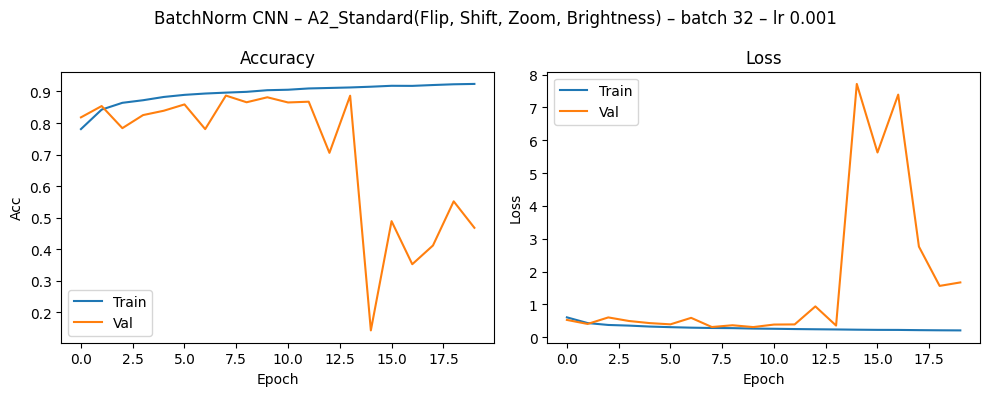

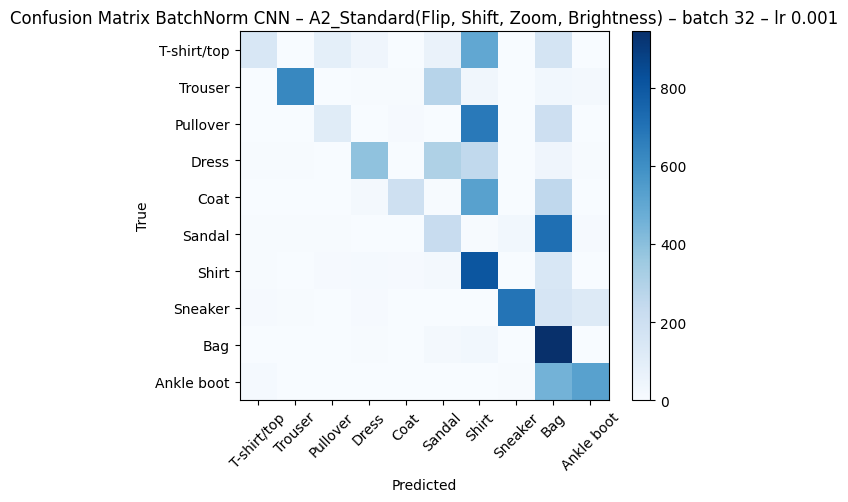


Training BatchNorm CNN with aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=64, epochs=20, lr=0.002, seed=42
Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.7367 - loss: 0.7458 - val_accuracy: 0.7526 - val_loss: 0.6801
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8417 - loss: 0.4379 - val_accuracy: 0.6414 - val_loss: 1.1354
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8624 - loss: 0.3779 - val_accuracy: 0.7076 - val_loss: 0.8173
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8771 - loss: 0.3456 - val_accuracy: 0.7438 - val_loss: 0.7052
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8829 - loss: 0.3255 - val_accuracy: 0.8670 - val_loss: 0.3718
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8896 - loss: 0.3053 - val_accuracy: 0.8020 - val_loss: 0.5354
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8930 - loss: 0.2915 - val_accuracy: 0.8250

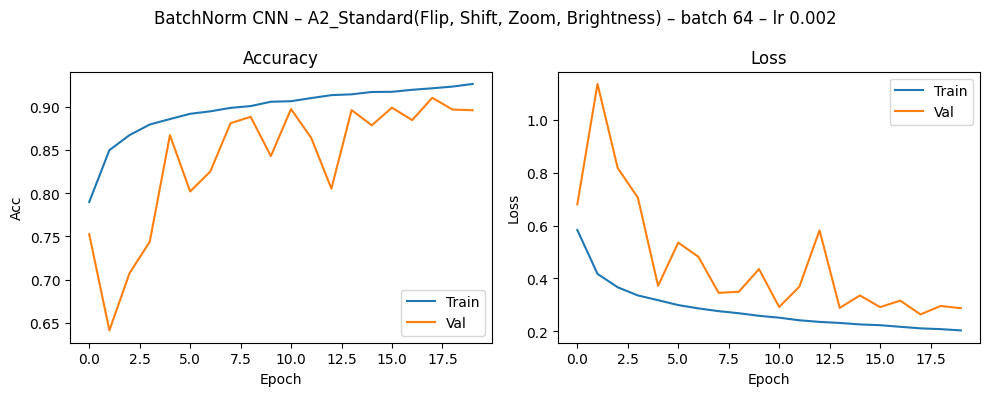

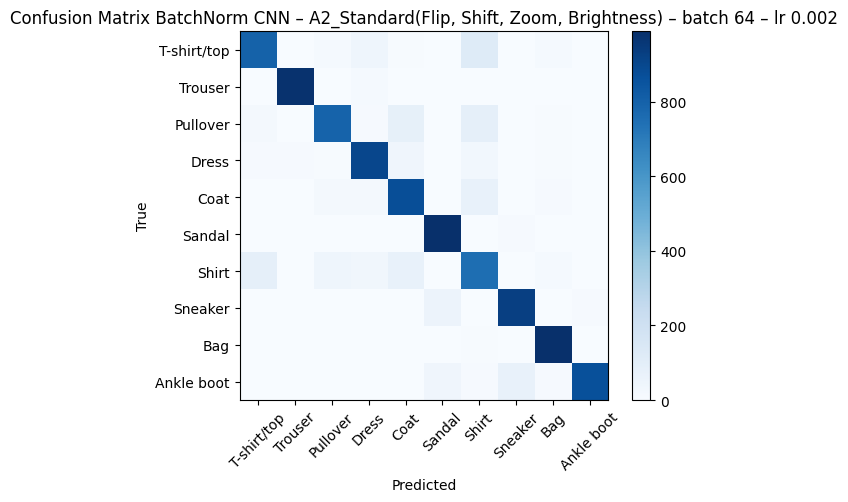


Training BatchNorm CNN with aug=A3_RotationOnly, batch=16, epochs=20, lr=0.0005, seed=42
Epoch 1/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 39s 10ms/step - accuracy: 0.6669 - loss: 0.9506 - val_accuracy: 0.7836 - val_loss: 0.5898
Epoch 2/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.7923 - loss: 0.5802 - val_accuracy: 0.7760 - val_loss: 0.5887
Epoch 3/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 34s 10ms/step - accuracy: 0.8241 - loss: 0.4950 - val_accuracy: 0.7894 - val_loss: 0.5844
Epoch 4/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 34s 10ms/step - accuracy: 0.8384 - loss: 0.4522 - val_accuracy: 0.8150 - val_loss: 0.5073
Epoch 5/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 34s 10ms/step - accuracy: 0.8490 - loss: 0.4196 - val_accuracy: 0.8306 - val_loss: 0.4576
Epoch 6/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8580 - loss: 0.3968 - val_accuracy: 0.7004 - val_loss: 1.4379
Epoch 7/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 34s 10ms/step - accuracy: 0.8673 - loss: 0.3731 - val_accuracy: 0.2776 - val

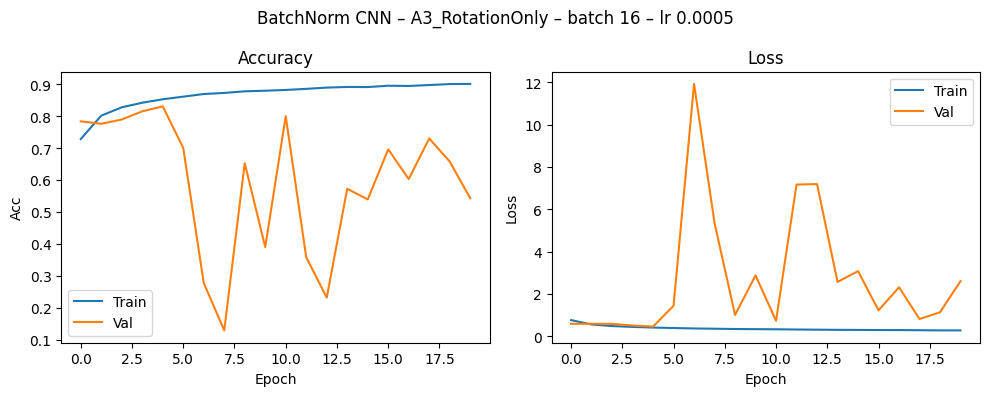

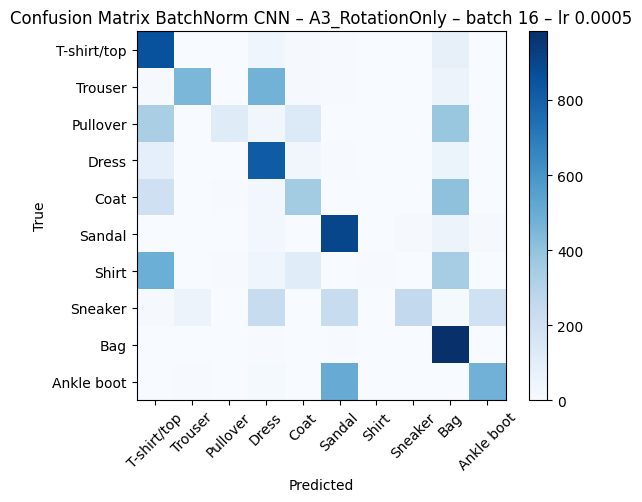


Training BatchNorm CNN with aug=A3_RotationOnly, batch=32, epochs=20, lr=0.001, seed=42
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 22s 10ms/step - accuracy: 0.6853 - loss: 0.8919 - val_accuracy: 0.7638 - val_loss: 0.7244
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8059 - loss: 0.5369 - val_accuracy: 0.8190 - val_loss: 0.5156
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8340 - loss: 0.4578 - val_accuracy: 0.8260 - val_loss: 0.5041
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8494 - loss: 0.4167 - val_accuracy: 0.8354 - val_loss: 0.4544
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8592 - loss: 0.3851 - val_accuracy: 0.8558 - val_loss: 0.3996
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8674 - loss: 0.3689 - val_accuracy: 0.8528 - val_loss: 0.4094
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.8753 - loss: 0.3447 - val_accuracy: 0.7422 - val_

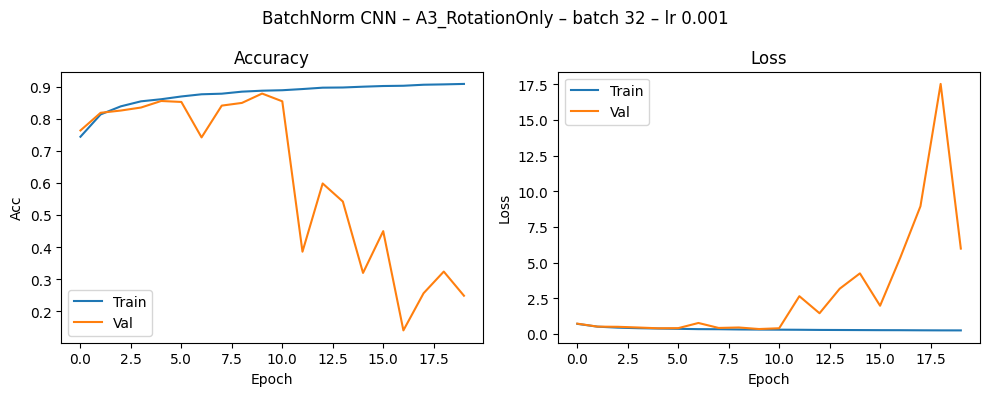

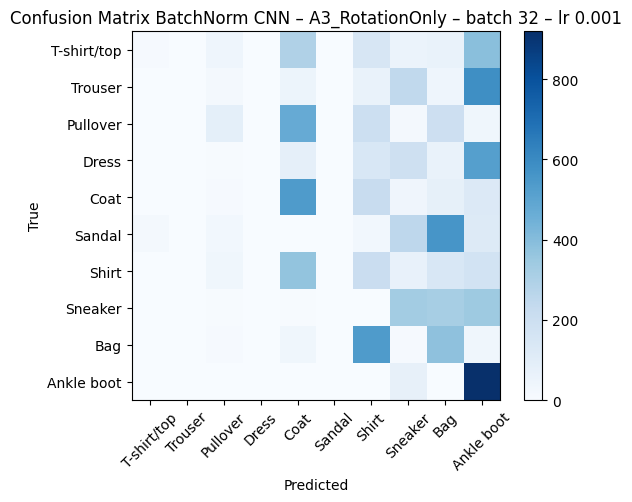


Training BatchNorm CNN with aug=A3_RotationOnly, batch=64, epochs=20, lr=0.002, seed=42
Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.6909 - loss: 0.8883 - val_accuracy: 0.4926 - val_loss: 1.7554
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8125 - loss: 0.5232 - val_accuracy: 0.7208 - val_loss: 1.1067
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8378 - loss: 0.4482 - val_accuracy: 0.5550 - val_loss: 1.4290
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8389 - loss: 0.4385 - val_accuracy: 0.7324 - val_loss: 0.7899
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8624 - loss: 0.3777 - val_accuracy: 0.7946 - val_loss: 0.6480
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8702 - loss: 0.3540 - val_accuracy: 0.7480 - val_loss: 1.1086
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8748 - loss: 0.3432 - val_accuracy: 0.8122 - val_loss: 0.5600
Epoch 8

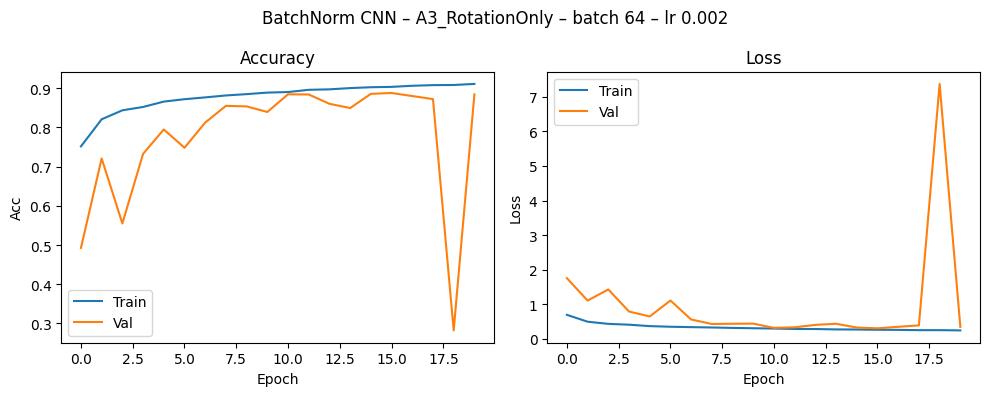

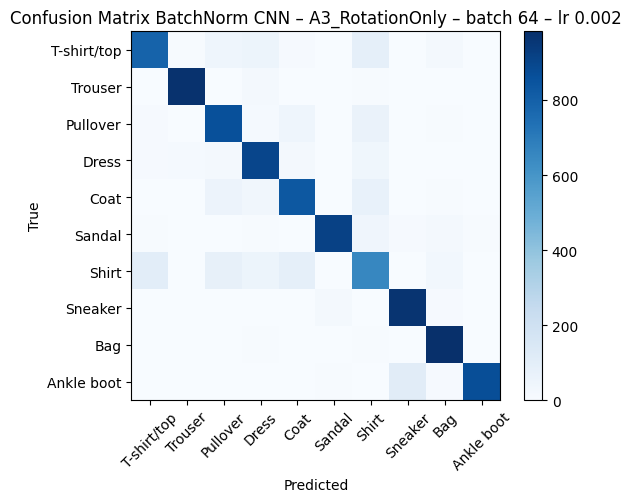


Training BatchNorm CNN with aug=A4_StrongAugmentation, batch=16, epochs=20, lr=0.0005, seed=42
Epoch 1/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.6172 - loss: 1.0972 - val_accuracy: 0.7602 - val_loss: 0.6926
Epoch 2/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 37s 11ms/step - accuracy: 0.7516 - loss: 0.6925 - val_accuracy: 0.7184 - val_loss: 0.7528
Epoch 3/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 37s 11ms/step - accuracy: 0.7829 - loss: 0.6009 - val_accuracy: 0.7652 - val_loss: 0.5945
Epoch 4/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 36s 11ms/step - accuracy: 0.8065 - loss: 0.5455 - val_accuracy: 0.7736 - val_loss: 0.6559
Epoch 5/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 37s 11ms/step - accuracy: 0.8146 - loss: 0.5135 - val_accuracy: 0.8180 - val_loss: 0.5293
Epoch 6/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 36s 11ms/step - accuracy: 0.8243 - loss: 0.4888 - val_accuracy: 0.5532 - val_loss: 1.2982
Epoch 7/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 36s 11ms/step - accuracy: 0.8325 - loss: 0.4674 - val_accuracy: 0.7262

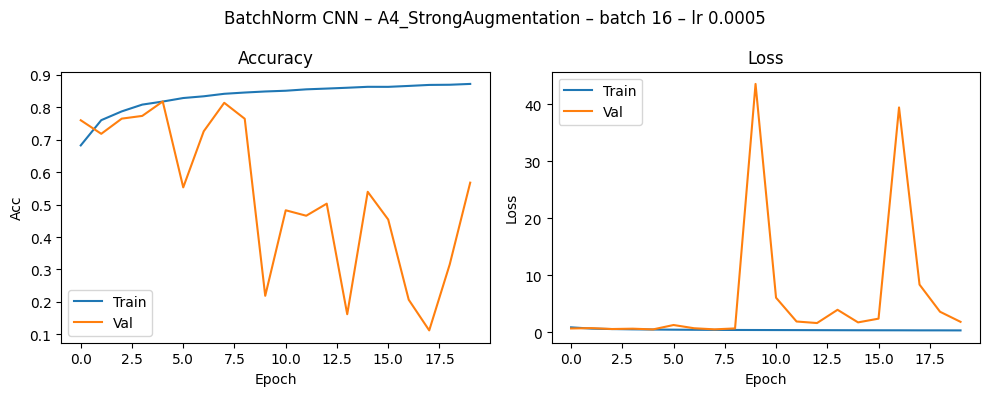

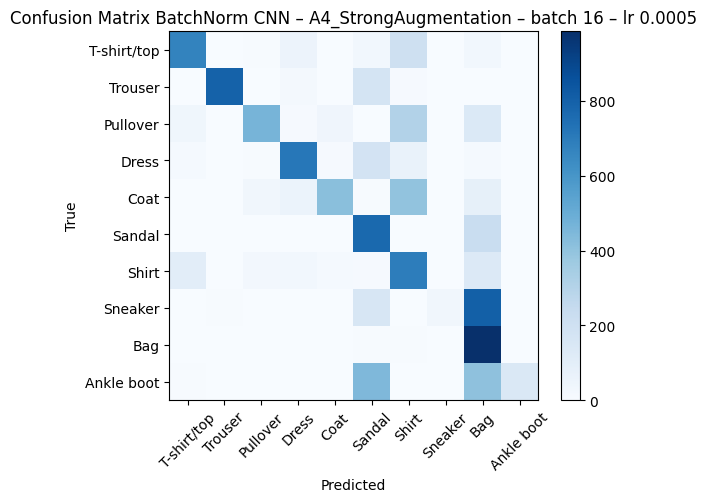


Training BatchNorm CNN with aug=A4_StrongAugmentation, batch=32, epochs=20, lr=0.001, seed=42
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - accuracy: 0.6384 - loss: 1.0317 - val_accuracy: 0.4612 - val_loss: 2.0641
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.7667 - loss: 0.6503 - val_accuracy: 0.5882 - val_loss: 1.4103
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.7967 - loss: 0.5641 - val_accuracy: 0.3828 - val_loss: 2.9993
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8142 - loss: 0.5136 - val_accuracy: 0.4480 - val_loss: 2.6236
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8279 - loss: 0.4800 - val_accuracy: 0.2812 - val_loss: 4.0472
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8351 - loss: 0.4572 - val_accuracy: 0.4386 - val_loss: 2.3362
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8417 - loss: 0.4334 - val_accuracy: 0.4768 

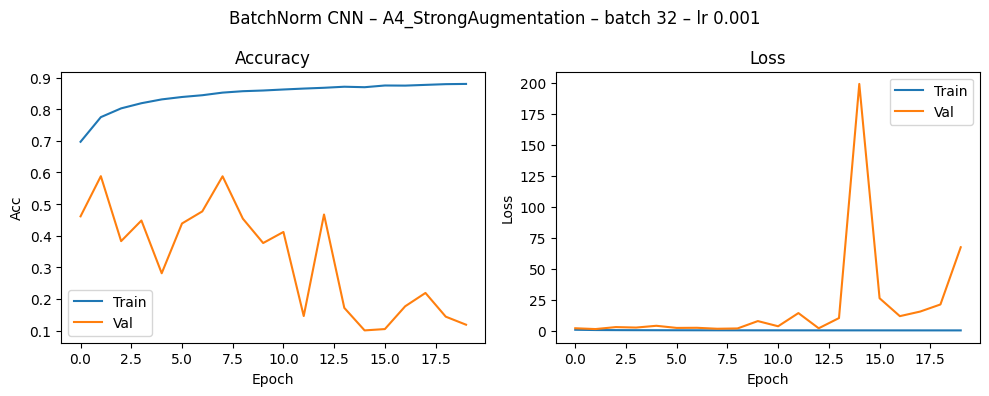

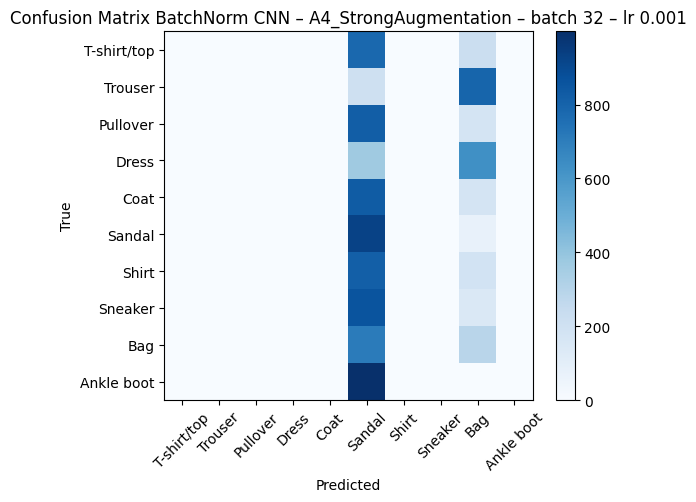


Training BatchNorm CNN with aug=A4_StrongAugmentation, batch=64, epochs=20, lr=0.002, seed=42
Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.6447 - loss: 1.0085 - val_accuracy: 0.6134 - val_loss: 1.3588
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7722 - loss: 0.6221 - val_accuracy: 0.5172 - val_loss: 1.5085
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7898 - loss: 0.5841 - val_accuracy: 0.7652 - val_loss: 0.6310
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8215 - loss: 0.4931 - val_accuracy: 0.8022 - val_loss: 0.5569
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8310 - loss: 0.4607 - val_accuracy: 0.7808 - val_loss: 0.6043
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8405 - loss: 0.4385 - val_accuracy: 0.7006 - val_loss: 0.8176
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8474 - loss: 0.4209 - val_accuracy: 0.8132 - val_loss: 0.5305
E

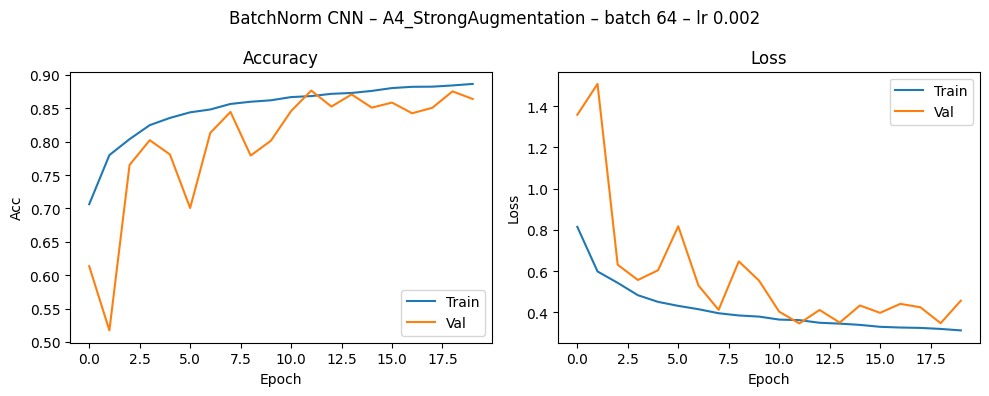

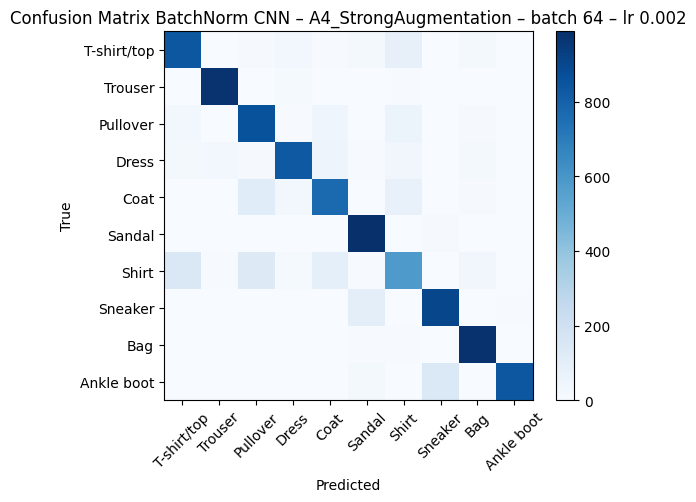

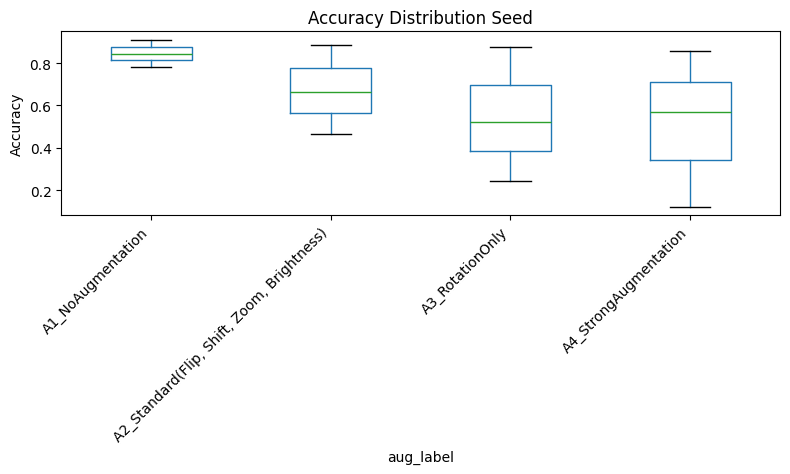

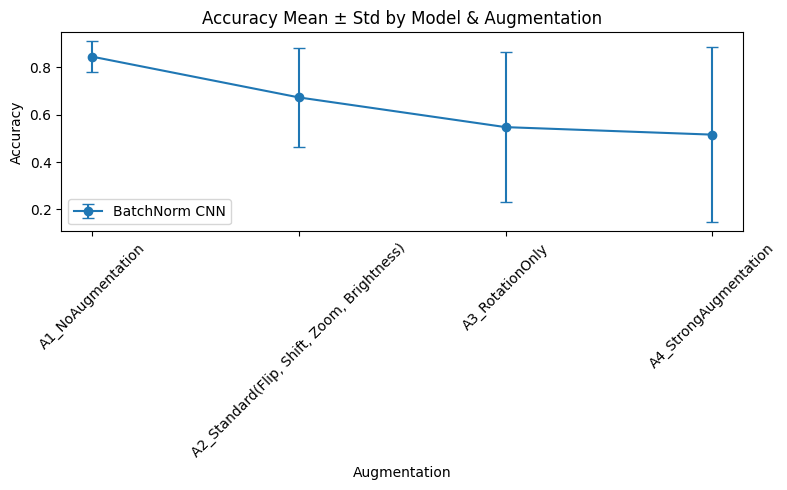


Metrics for BatchNorm CNN with A1_NoAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
0,42,0.781,0.778,0.077,16,10.51
1,42,0.843,0.840,0.047,6,5.74
2,42,0.910,0.910,0.036,7,3.32



Metrics for BatchNorm CNN with A2_Standard(Flip, Shift, Zoom, Brightness)


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
3,42,0.665,0.654,0.008,4,34.90
4,42,0.466,0.458,0.009,8,18.07
5,42,0.887,0.887,0.011,18,9.36



Metrics for BatchNorm CNN with A3_RotationOnly


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
6,42,0.521,0.464,0.022,5,34.75
7,42,0.246,0.169,0.009,10,17.75
8,42,0.875,0.874,0.016,16,9.19



Metrics for BatchNorm CNN with A4_StrongAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
9,42,0.568,0.543,-0.000,5,36.83
10,42,0.122,0.038,0.187,2,18.52
11,42,0.857,0.855,-0.008,12,9.60


In [ ]:
# 4.3 BatchNorm CNN: Training, Evaluation, and Output Generation
# Initialize result containers
results = []
histories = {}
confusions = {}
trained_models = {}
# Seed and parameter grid
SEEDS = [42]
PARAMS_M1 = [
    {"batch_size": 16, "epochs": 20, "lr": 5e-4},
    {"batch_size": 32, "epochs": 20, "lr": 1e-3},
    {"batch_size": 64, "epochs": 20, "lr": 2e-3}
]

# Augmentation strategies
AUGS = {
    "A1_NoAugmentation": None,
    "A2_Standard(Flip, Shift, Zoom, Brightness)": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1)
    ]),
    "A3_RotationOnly": keras.Sequential([
        layers.RandomRotation(0.2)
    ]),
    "A4_StrongAugmentation": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2)
    ])
}

# Class labels
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Model builder for BatchNorm CNN
def build_batchnorm_cnn(aug=None, lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    if aug is not None:
        x = aug(x, training=True)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="batchnorm_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Seed control
def set_seed(seed):
    import os, random
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

# Train once
def train_once(model, batch_size, max_epochs, seed, early_stop=False):
    set_seed(seed)
    callbacks = []
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True))
    start = time.time()
    hist = model.fit(x_train, y_train,
                     validation_data=(x_val, y_val),
                     batch_size=batch_size,
                     epochs=max_epochs,
                     verbose=1,
                     callbacks=callbacks)
    dur = time.time() - start
    best_ep = np.argmax(hist.history["val_accuracy"]) + 1
    return hist, dur, best_ep

# Evaluate
def eval_on_test(model):
    preds = model.predict(x_test, verbose=0)
    y_pred = np.argmax(preds, axis=1)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    cm = confusion_matrix(y_test, y_pred)
    return acc, f1, cm, y_pred

# Accuracy gap
def train_val_gap(hist):
    best_ep = np.argmax(hist.history["val_accuracy"])
    train_acc = hist.history["accuracy"][best_ep]
    val_acc = hist.history["val_accuracy"][best_ep]
    return round(train_acc - val_acc, 3)

# Plot history
def plot_history(hist, title="Training History"):
    if hist is None or not hasattr(hist, "history"):
        print("Invalid history object — skipping plot.")
        return
    keys = hist.history.keys()
    required_keys = ["accuracy", "val_accuracy", "loss", "val_loss"]
    missing = [k for k in required_keys if k not in keys]
    if missing:
        print(f"Missing keys in history: {missing} — skipping plot.")
        return
    plt.figure(figsize=(10, 4));
    plt.subplot(1, 2, 1)
    plt.plot(hist.history["accuracy"], label="Train")
    plt.plot(hist.history["val_accuracy"], label="Val")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Acc")
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(hist.history["loss"], label="Train")
    plt.plot(hist.history["val_loss"], label="Val")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Plot confusion
def plot_confusion(cm, title="Confusion Matrix"):
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.colorbar()
    plt.xticks(ticks=np.arange(10), labels=class_names, rotation=45)
    plt.yticks(ticks=np.arange(10), labels=class_names)
    plt.tight_layout()
    plt.show()

# Box plot
def plot_box_accuracy(df):
    df["aug_label"] = df["aug"]
    fig, ax = plt.subplots(figsize=(8, 5))
    df.boxplot(column="acc", by="aug_label", grid=False, ax=ax)
    ax.set_title("Accuracy Distribution Seed")
    fig.suptitle("")
    ax.set_ylabel("Accuracy")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    plt.show()

# Error bar plot
def plot_errorbar_accuracy(df):
    grouped = df.groupby(["model", "aug"])["acc"].agg(["mean", "std"]).reset_index()
    plt.figure(figsize=(8, 5))
    for model in grouped["model"].unique():
        subset = grouped[grouped["model"] == model]
        plt.errorbar(subset["aug"], subset["mean"], yerr=subset["std"], label=model, capsize=4, marker="o")
    plt.title("Accuracy Mean ± Std by Model & Augmentation")
    plt.ylabel("Accuracy")
    plt.xlabel("Augmentation")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Metrics table
def table_metrics(df, model="BatchNorm CNN", aug="A2_Standard(Flip, Shift, Zoom, Brightness)"):
    subset = df[(df["model"] == model) & (df["aug"] == aug)]
    print(f"\nMetrics for {model} with {aug}")
    display(subset[["seed", "acc", "macro_f1", "gap", "best_epoch", "sec_per_epoch"]])

# Augmentation comparison
def table_aug_comparison(df):
    grouped = df.groupby(["model", "aug"])[["acc", "macro_f1", "gap"]].agg(["mean", "std"])
    print("Augmentation Comparison Across Models")
    display(grouped.round(3))

# Training loop
for aug_key in AUGS:
    for config in PARAMS_M1:
        for seed in SEEDS:
            print(f"\nTraining BatchNorm CNN with aug={aug_key}, batch={config['batch_size']}, epochs={config['epochs']}, lr={config['lr']}, seed={seed}")
            model = build_batchnorm_cnn(aug=AUGS[aug_key], lr=config["lr"])
            hist, dur, best_ep = train_once(model, config["batch_size"], config["epochs"], seed, early_stop=False)
            acc, f1, cm, y_pred = eval_on_test(model)
            gap = train_val_gap(hist)
            results.append(dict(model="BatchNorm CNN", aug=aug_key,
                                batch=config["batch_size"], epochs=config["epochs"],
                                lr=config["lr"], seed=seed, early_stop=False,
                                acc=round(acc, 3), macro_f1=round(f1, 3),
                                gap=round(gap, 3), best_epoch=best_ep,
                                actual_epochs=len(hist.history["val_accuracy"]),
                                sec_per_epoch=round(dur/config["epochs"], 2)))
            if seed == 42:
                key = ("BatchNorm CNN", aug_key, config["batch_size"], config["epochs"], config["lr"])
                histories[key] = hist
                confusions[key] = cm
                trained_models[key] = model
                plot_history(hist, f"BatchNorm CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")
                plot_confusion(cm, f"Confusion Matrix BatchNorm CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")

# Create dataframe after training loop
df = pd.DataFrame(results)
df = df[["model", "aug", "seed", "batch", "epochs", "lr", "early_stop",
         "acc", "macro_f1", "gap", "best_epoch", "actual_epochs", "sec_per_epoch"]]
df = df.sort_values(by=["aug", "batch", "epochs", "lr", "seed"])

# Generate summary plots and tables
plot_box_accuracy(df)
plot_errorbar_accuracy(df)

# Display metrics tables for all augmentations
for aug_key in ["A1_NoAugmentation", "A2_Standard(Flip, Shift, Zoom, Brightness)", "A3_RotationOnly", "A4_StrongAugmentation"]:
    table_metrics(df, model="BatchNorm CNN", aug=aug_key)
df_batchnorm = df.copy()

# --- Add models to global_trained_models ---
if "global_trained_models" not in globals():
    global_trained_models = {}

df_local = df_batchnorm
for key, model in trained_models.items():
    model_name, aug_key, *_ = key
    if not df_local[(df_local["model"] == model_name) & (df_local["aug"] == aug_key) & (df_local["seed"] == 42)].empty:
        global_trained_models[(model_name, aug_key)] = model



## 5. Training Models with Early Stopping

### 5.1 Training : LeNet-style CNN (Early Stopping)


Training Baseline CNN with EARLY STOP – aug=A1_NoAugmentation, batch=16, epochs=10, lr=0.0005, seed=42
Epoch 1/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.5549 - loss: 1.2192 - val_accuracy: 0.7466 - val_loss: 0.6675
Epoch 2/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.7452 - loss: 0.6724 - val_accuracy: 0.7804 - val_loss: 0.5881
Epoch 3/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.7788 - loss: 0.5884 - val_accuracy: 0.8022 - val_loss: 0.5327
Epoch 4/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8027 - loss: 0.5306 - val_accuracy: 0.8192 - val_loss: 0.4912
Epoch 5/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8181 - loss: 0.4902 - val_accuracy: 0.8330 - val_loss: 0.4589
Epoch 6/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8293 - loss: 0.4595 - val_accuracy: 0.8402 - val_loss: 0.4396
Epoch 7/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8390 - loss: 0.4357 - val_accuracy: 0.8448 - va

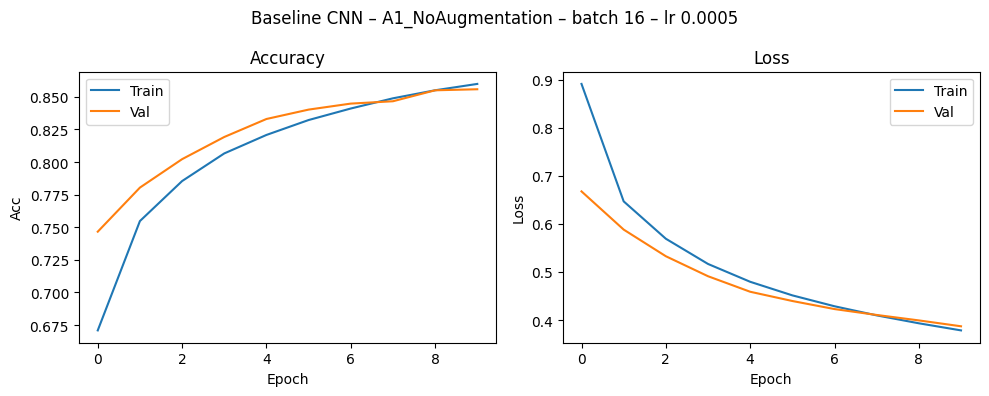

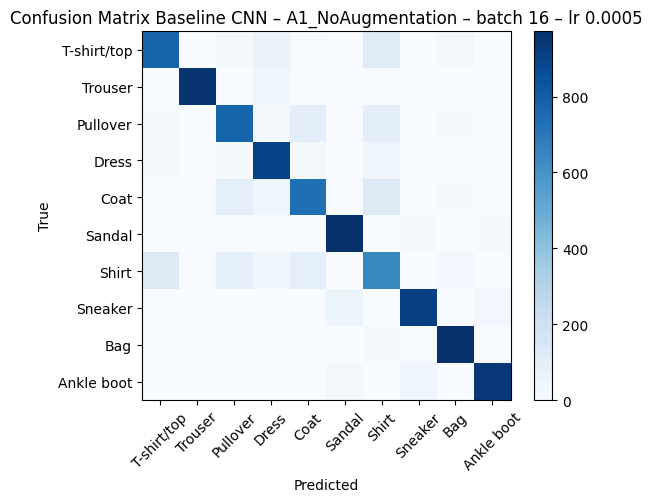


Training Baseline CNN with EARLY STOP – aug=A1_NoAugmentation, batch=32, epochs=10, lr=0.001, seed=42
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.5287 - loss: 1.2812 - val_accuracy: 0.7458 - val_loss: 0.6639
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7559 - loss: 0.6471 - val_accuracy: 0.7832 - val_loss: 0.5621
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7922 - loss: 0.5537 - val_accuracy: 0.8108 - val_loss: 0.5036
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8153 - loss: 0.4984 - val_accuracy: 0.8256 - val_loss: 0.4700
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8288 - loss: 0.4629 - val_accuracy: 0.8362 - val_loss: 0.4435
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8403 - loss: 0.4367 - val_accuracy: 0.8386 - val_loss: 0.4231
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8484 - loss: 0.4148 - val_accuracy: 0.8456 - val_

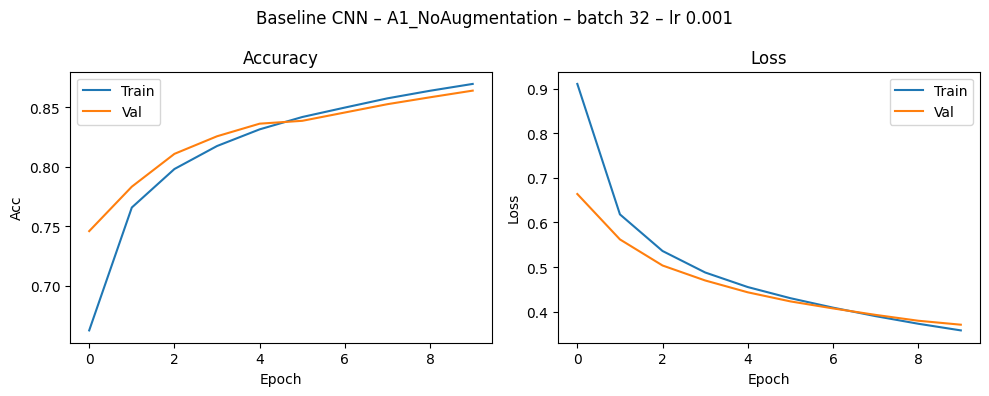

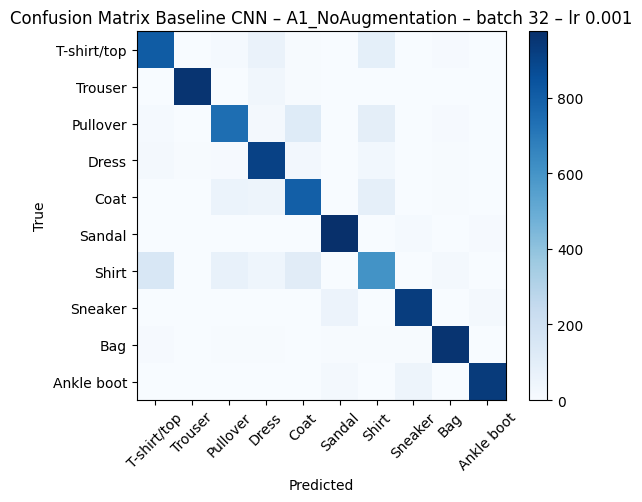


Training Baseline CNN with EARLY STOP – aug=A1_NoAugmentation, batch=64, epochs=10, lr=0.002, seed=42
Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.4991 - loss: 1.3566 - val_accuracy: 0.7068 - val_loss: 0.7406
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7325 - loss: 0.7076 - val_accuracy: 0.7366 - val_loss: 0.6778
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7555 - loss: 0.6409 - val_accuracy: 0.7608 - val_loss: 0.6031
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7807 - loss: 0.5831 - val_accuracy: 0.7800 - val_loss: 0.5492
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7977 - loss: 0.5365 - val_accuracy: 0.7956 - val_loss: 0.5109
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8121 - loss: 0.5017 - val_accuracy: 0.8138 - val_loss: 0.4762
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8226 - loss: 0.4754 - val_accuracy: 0.8250 - val_loss: 0.4546
E

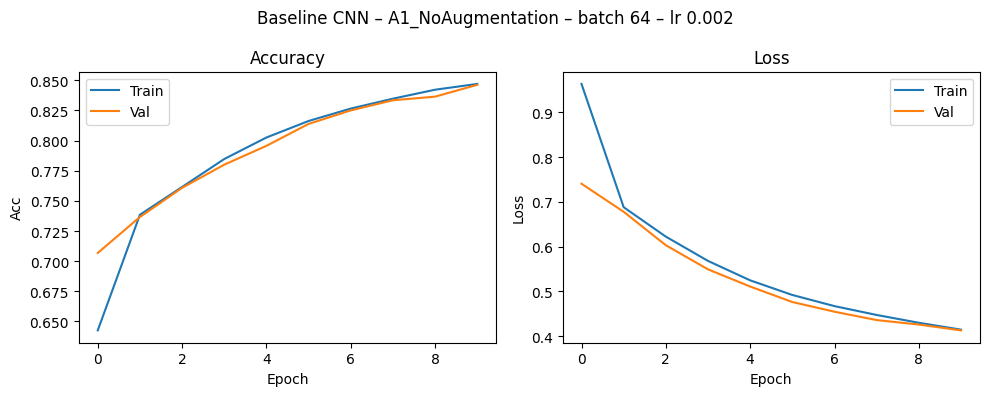

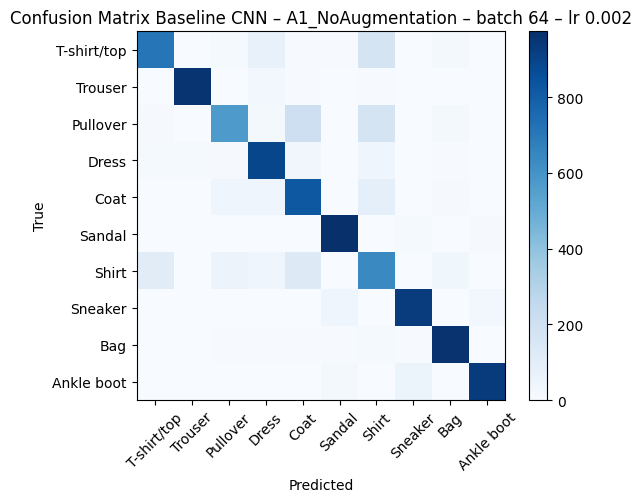


Training Baseline CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=16, epochs=10, lr=0.0005, seed=42
Epoch 1/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.4442 - loss: 1.5251 - val_accuracy: 0.6942 - val_loss: 0.8121
Epoch 2/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.6886 - loss: 0.8430 - val_accuracy: 0.7278 - val_loss: 0.7086
Epoch 3/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7133 - loss: 0.7573 - val_accuracy: 0.7494 - val_loss: 0.6535
Epoch 4/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.7340 - loss: 0.7076 - val_accuracy: 0.7584 - val_loss: 0.6357
Epoch 5/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.7471 - loss: 0.6673 - val_accuracy: 0.7602 - val_loss: 0.6142
Epoch 6/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7604 - loss: 0.6361 - val_accuracy: 0.7700 - val_loss: 0.6001
Epoch 7/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.7688 - loss: 0.6

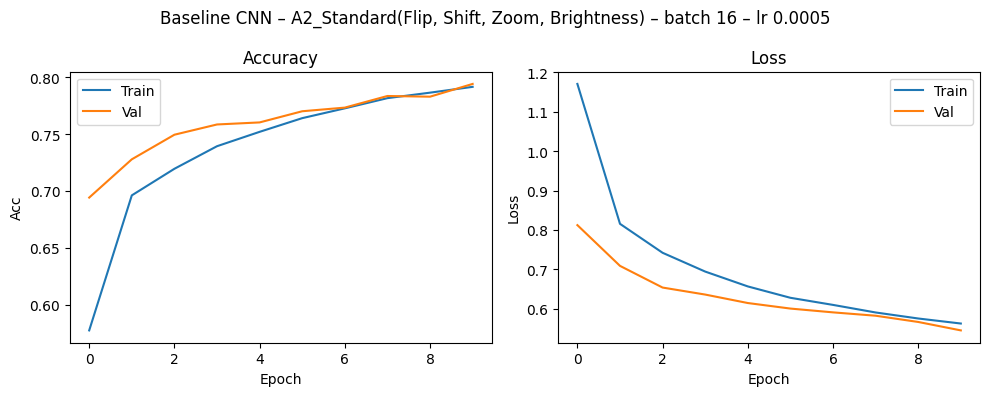

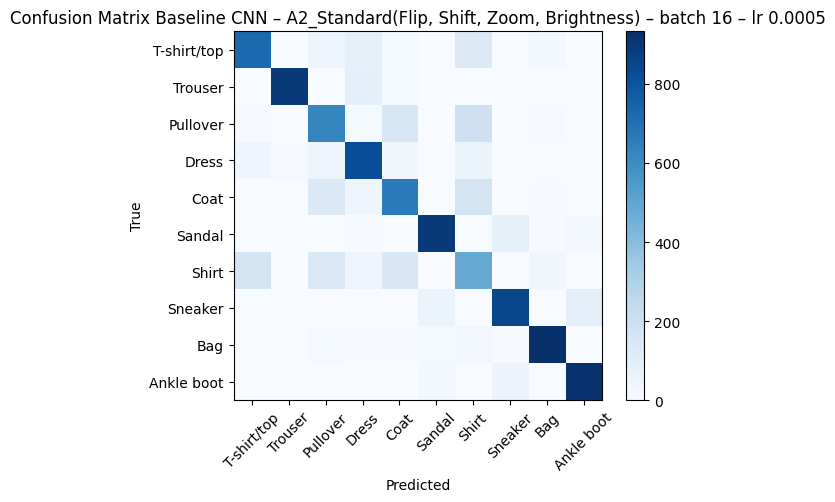


Training Baseline CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=32, epochs=10, lr=0.001, seed=42
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.4264 - loss: 1.5575 - val_accuracy: 0.7008 - val_loss: 0.7714
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6871 - loss: 0.8425 - val_accuracy: 0.7268 - val_loss: 0.7134
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7146 - loss: 0.7615 - val_accuracy: 0.7436 - val_loss: 0.6729
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7288 - loss: 0.7187 - val_accuracy: 0.7496 - val_loss: 0.6493
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7414 - loss: 0.6878 - val_accuracy: 0.7642 - val_loss: 0.6282
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7527 - loss: 0.6606 - val_accuracy: 0.7734 - val_loss: 0.6063
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7607 - loss: 0.6390 - v

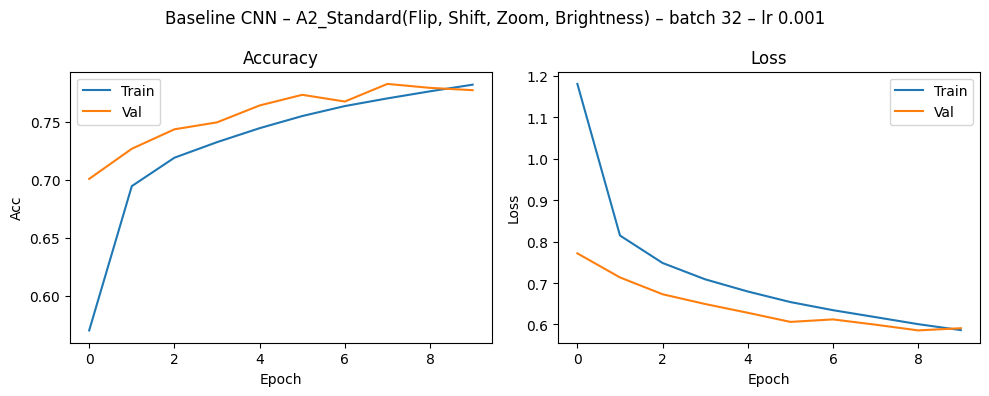

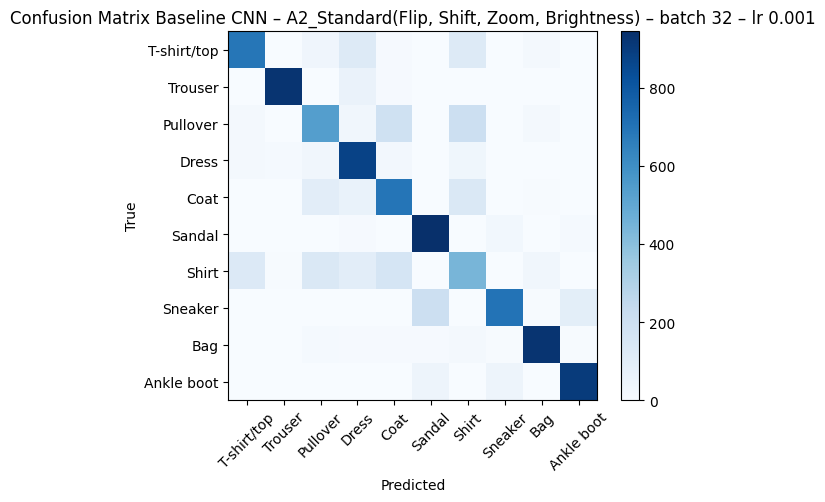


Training Baseline CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=64, epochs=10, lr=0.002, seed=42
Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.3716 - loss: 1.6945 - val_accuracy: 0.7152 - val_loss: 0.7797
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6877 - loss: 0.8474 - val_accuracy: 0.7320 - val_loss: 0.7201
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7136 - loss: 0.7639 - val_accuracy: 0.7500 - val_loss: 0.6667
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7283 - loss: 0.7186 - val_accuracy: 0.7524 - val_loss: 0.6460
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7402 - loss: 0.6859 - val_accuracy: 0.7678 - val_loss: 0.6114
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7501 - loss: 0.6603 - val_accuracy: 0.7746 - val_loss: 0.6023
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7563 - loss: 0.6442 - val_accuracy: 0.

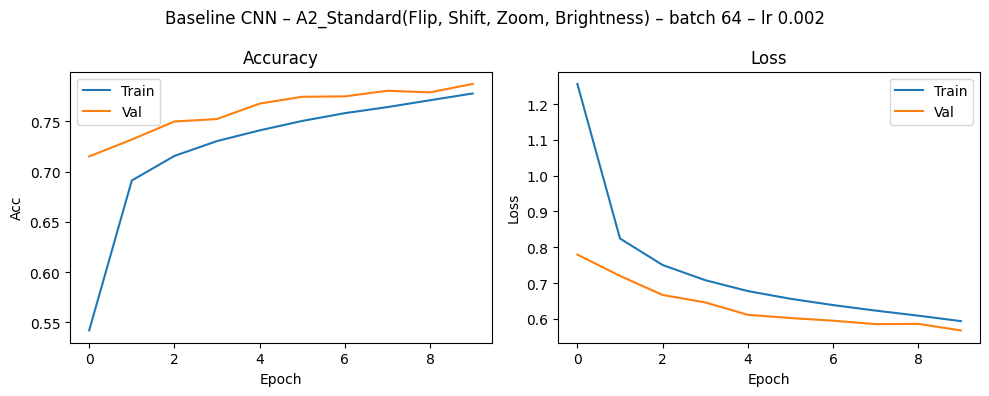

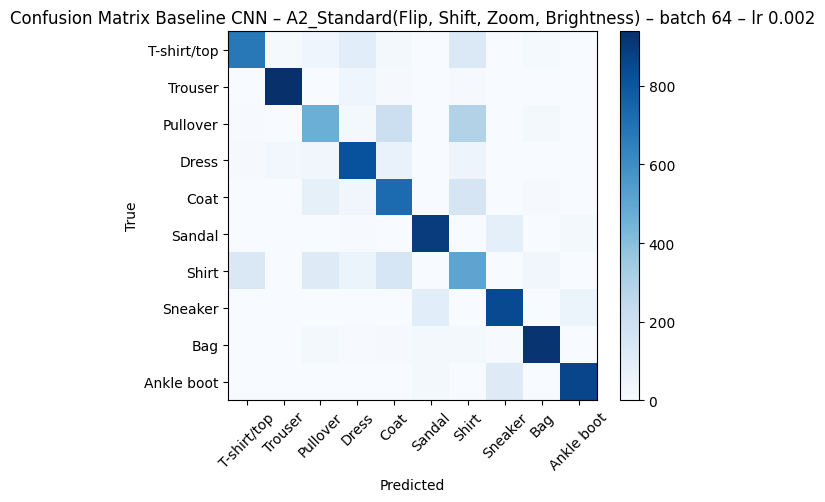


Training Baseline CNN with EARLY STOP – aug=A3_RotationOnly, batch=16, epochs=10, lr=0.0005, seed=42
Epoch 1/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.3809 - loss: 1.6946 - val_accuracy: 0.6300 - val_loss: 1.0323
Epoch 2/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.6285 - loss: 1.0332 - val_accuracy: 0.6786 - val_loss: 0.9043
Epoch 3/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.6742 - loss: 0.8967 - val_accuracy: 0.7018 - val_loss: 0.8166
Epoch 4/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.6955 - loss: 0.8246 - val_accuracy: 0.7172 - val_loss: 0.7646
Epoch 5/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.7098 - loss: 0.7821 - val_accuracy: 0.7324 - val_loss: 0.7314
Epoch 6/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.7225 - loss: 0.7516 - val_accuracy: 0.7400 - val_loss: 0.7104
Epoch 7/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.7293 - loss: 0.7292 - val_accuracy: 0.7480 

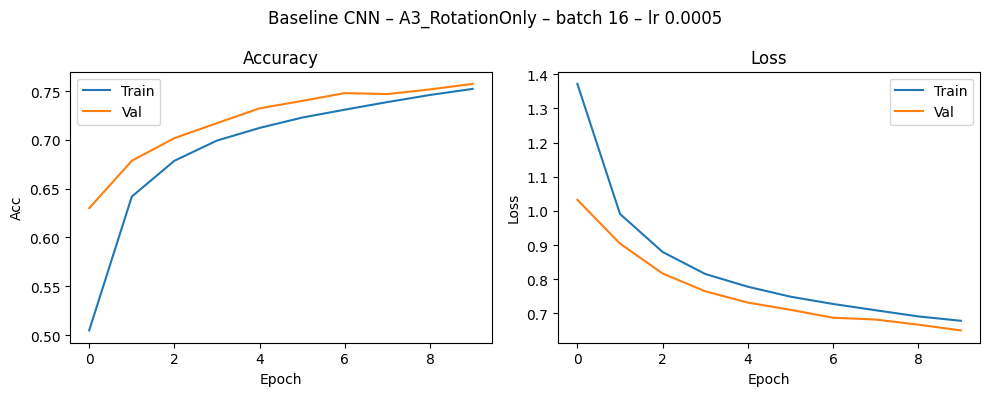

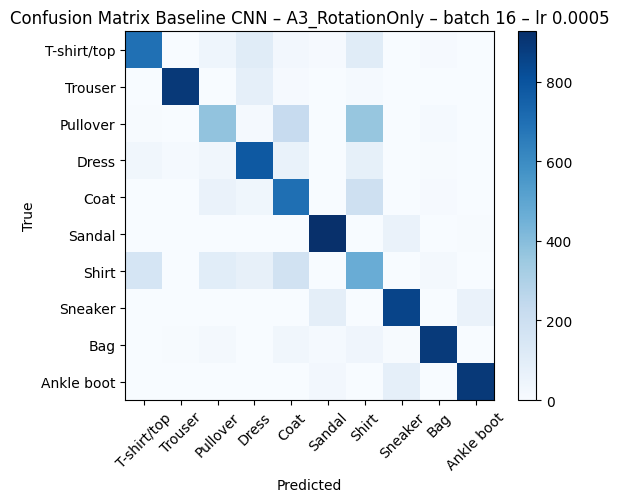


Training Baseline CNN with EARLY STOP – aug=A3_RotationOnly, batch=32, epochs=10, lr=0.001, seed=42
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.3638 - loss: 1.7227 - val_accuracy: 0.6172 - val_loss: 1.0391
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6244 - loss: 1.0403 - val_accuracy: 0.6726 - val_loss: 0.8973
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6654 - loss: 0.9165 - val_accuracy: 0.7008 - val_loss: 0.8227
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6842 - loss: 0.8529 - val_accuracy: 0.7006 - val_loss: 0.7785
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7051 - loss: 0.8036 - val_accuracy: 0.7174 - val_loss: 0.7477
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7158 - loss: 0.7738 - val_accuracy: 0.7354 - val_loss: 0.7119
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7268 - loss: 0.7436 - val_accuracy: 0.7434 - val_l

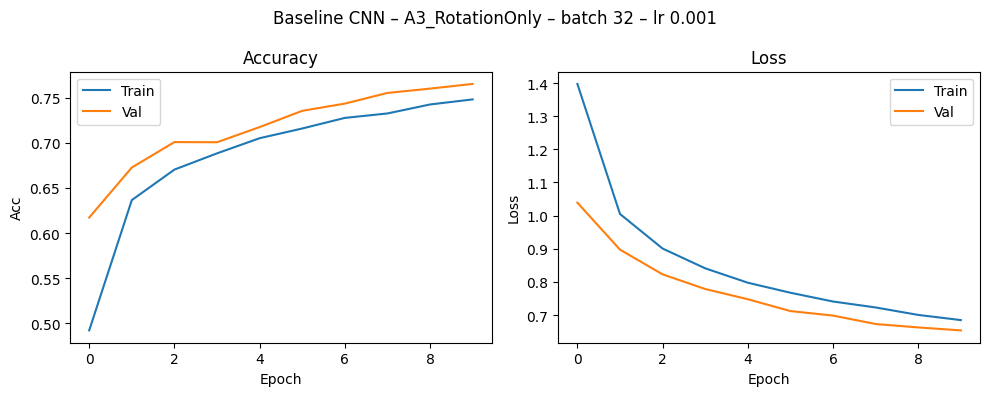

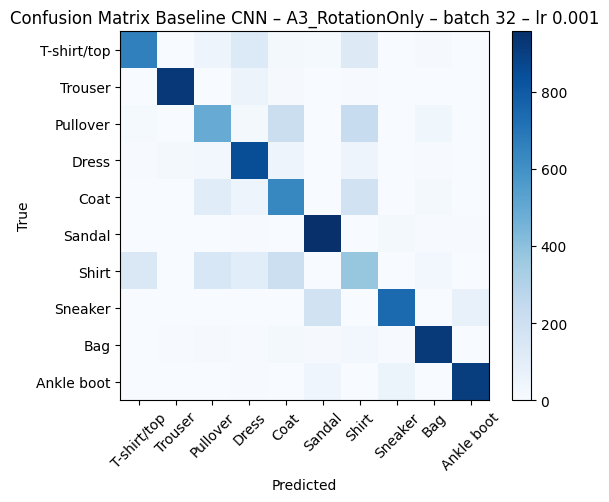


Training Baseline CNN with EARLY STOP – aug=A3_RotationOnly, batch=64, epochs=10, lr=0.002, seed=42
Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.3040 - loss: 1.8531 - val_accuracy: 0.6212 - val_loss: 1.0682
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.5960 - loss: 1.1013 - val_accuracy: 0.6448 - val_loss: 0.9732
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6446 - loss: 0.9682 - val_accuracy: 0.6890 - val_loss: 0.8798
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6679 - loss: 0.9013 - val_accuracy: 0.7004 - val_loss: 0.8269
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6856 - loss: 0.8544 - val_accuracy: 0.7166 - val_loss: 0.7882
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6956 - loss: 0.8218 - val_accuracy: 0.7230 - val_loss: 0.7638
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7063 - loss: 0.8011 - val_accuracy: 0.7362 - val_loss: 0.7398
Epo

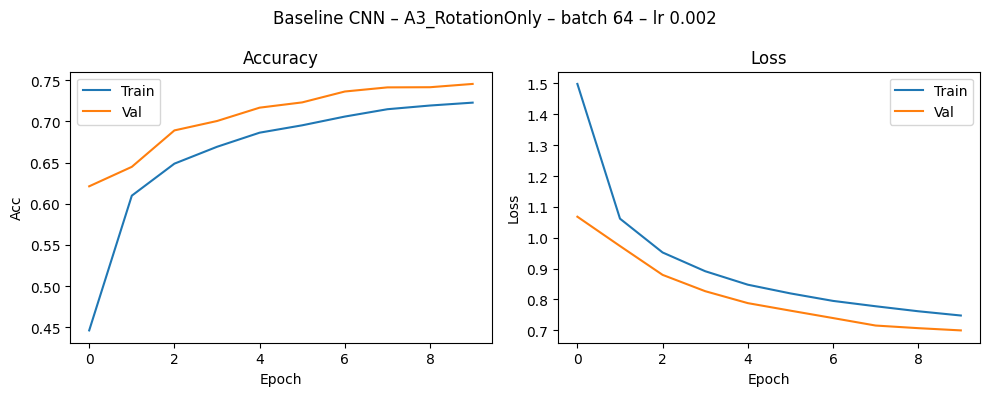

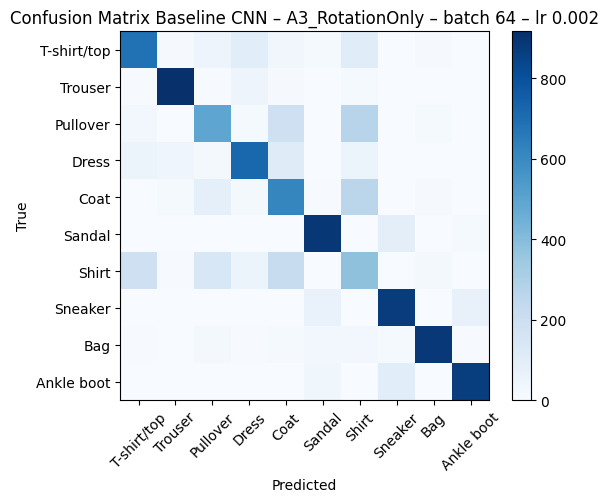


Training Baseline CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=16, epochs=10, lr=0.0005, seed=42
Epoch 1/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 19s 5ms/step - accuracy: 0.2886 - loss: 1.8996 - val_accuracy: 0.6130 - val_loss: 1.0695
Epoch 2/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.5757 - loss: 1.1657 - val_accuracy: 0.6542 - val_loss: 0.9824
Epoch 3/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.6111 - loss: 1.0595 - val_accuracy: 0.6676 - val_loss: 0.8880
Epoch 4/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.6322 - loss: 0.9936 - val_accuracy: 0.6780 - val_loss: 0.8502
Epoch 5/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.6485 - loss: 0.9501 - val_accuracy: 0.7082 - val_loss: 0.8130
Epoch 6/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.6613 - loss: 0.9151 - val_accuracy: 0.7042 - val_loss: 0.7832
Epoch 7/10
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - accuracy: 0.6724 - loss: 0.8843 - val_accuracy: 0

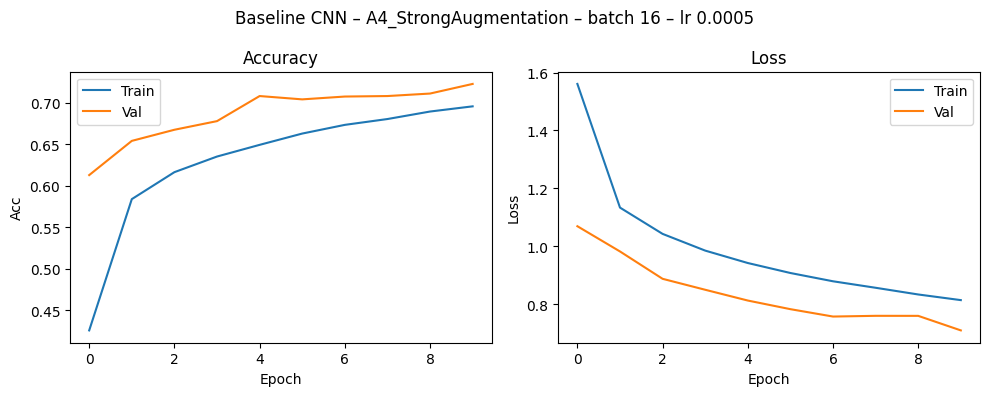

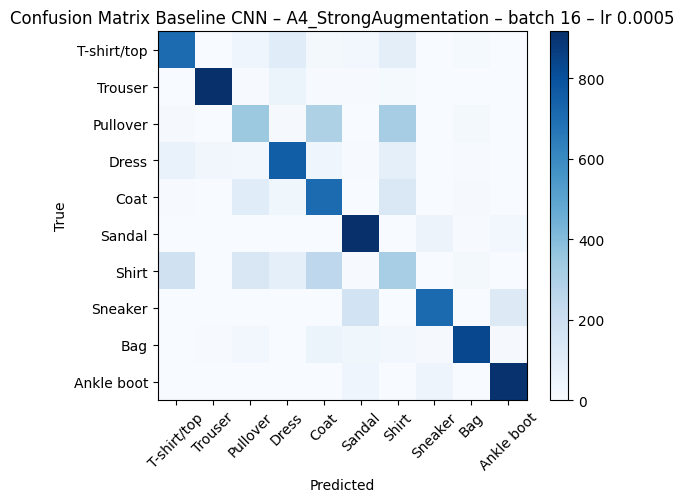


Training Baseline CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=32, epochs=10, lr=0.001, seed=42
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.2894 - loss: 1.9097 - val_accuracy: 0.6174 - val_loss: 1.0689
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5792 - loss: 1.1582 - val_accuracy: 0.6322 - val_loss: 0.9863
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6142 - loss: 1.0411 - val_accuracy: 0.6790 - val_loss: 0.8932
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6368 - loss: 0.9823 - val_accuracy: 0.6686 - val_loss: 0.8648
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6506 - loss: 0.9379 - val_accuracy: 0.6930 - val_loss: 0.8121
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6608 - loss: 0.9091 - val_accuracy: 0.7044 - val_loss: 0.7872
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.6726 - loss: 0.8758 - val_accuracy: 0.7112 -

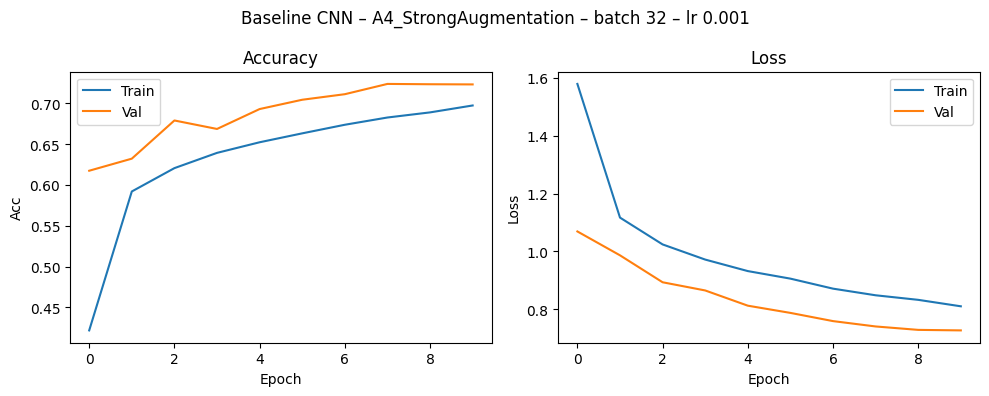

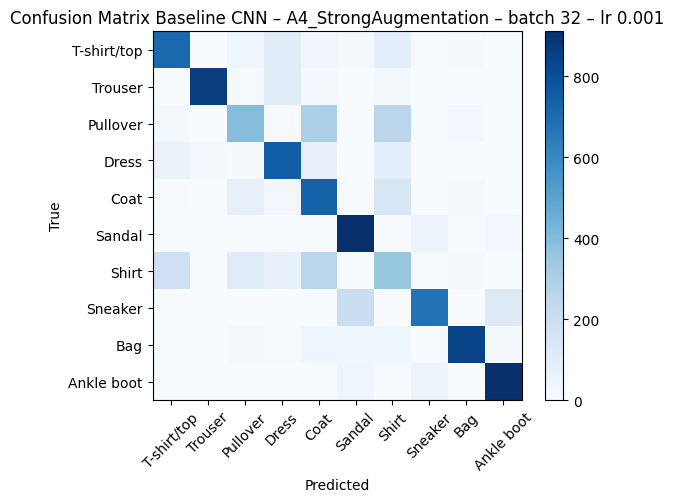


Training Baseline CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=64, epochs=10, lr=0.002, seed=42
Epoch 1/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.2838 - loss: 1.9318 - val_accuracy: 0.5886 - val_loss: 1.1348
Epoch 2/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.5665 - loss: 1.1704 - val_accuracy: 0.6390 - val_loss: 0.9914
Epoch 3/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6049 - loss: 1.0630 - val_accuracy: 0.6750 - val_loss: 0.8907
Epoch 4/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6227 - loss: 1.0110 - val_accuracy: 0.6818 - val_loss: 0.8699
Epoch 5/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6319 - loss: 0.9856 - val_accuracy: 0.6940 - val_loss: 0.8439
Epoch 6/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6434 - loss: 0.9544 - val_accuracy: 0.7040 - val_loss: 0.8162
Epoch 7/10
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6451 - loss: 0.9404 - val_accuracy: 0.7110 - val_loss: 0.79

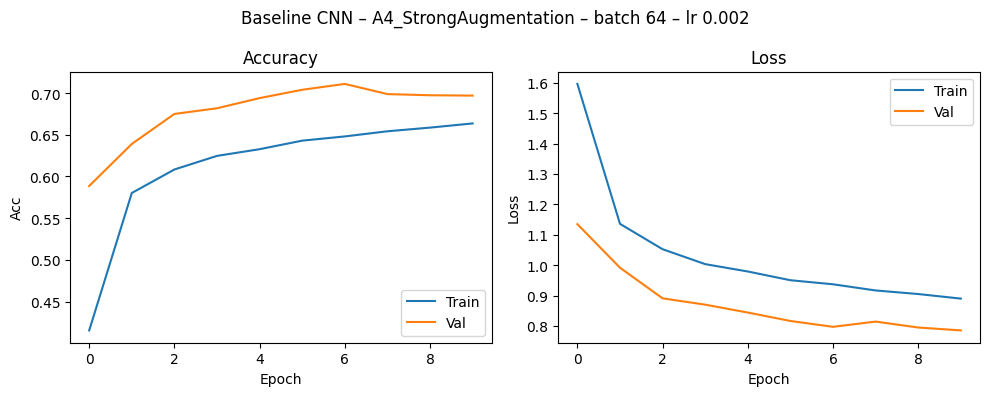

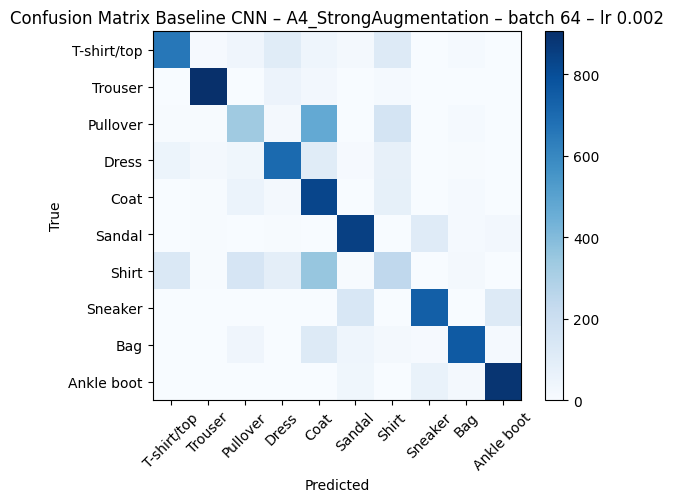

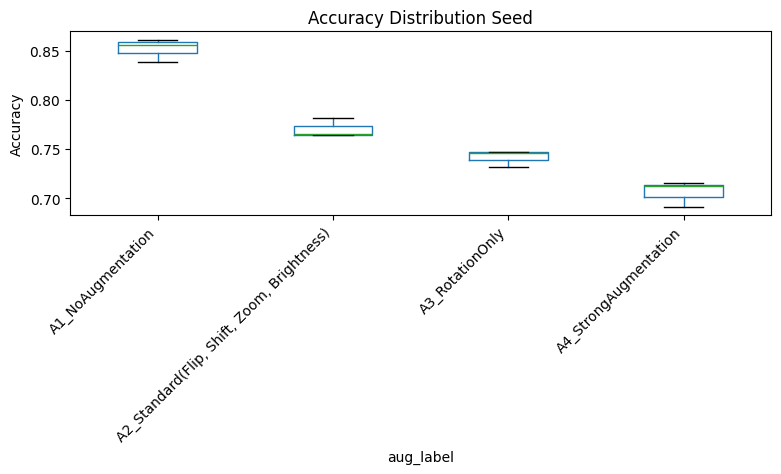

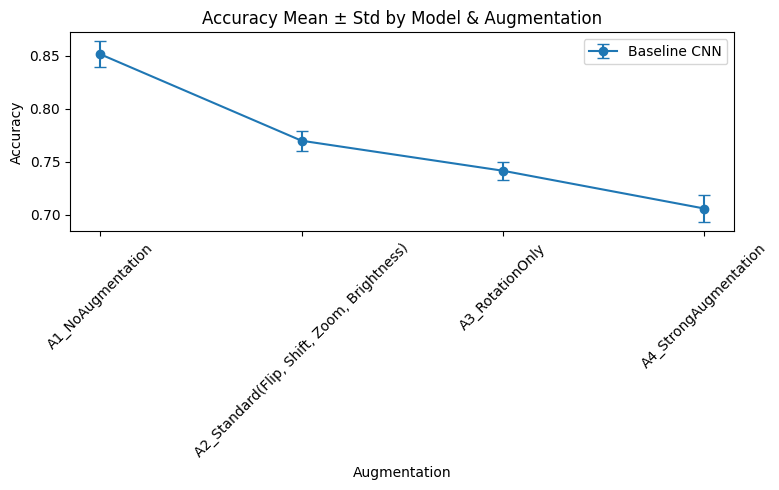


Metrics for Baseline CNN with A1_NoAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
0,42,0.856,0.856,0.004,10,8.29
1,42,0.861,0.860,0.006,10,4.51
2,42,0.838,0.837,0.001,10,2.69



Metrics for Baseline CNN with A2_Standard(Flip, Shift, Zoom, Brightness)


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
3,42,0.781,0.782,-0.003,10,16.85
4,42,0.764,0.761,-0.012,8,8.81
5,42,0.765,0.765,-0.010,10,4.54



Metrics for Baseline CNN with A3_RotationOnly


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
6,42,0.747,0.748,-0.005,10,16.52
7,42,0.746,0.744,-0.017,10,8.59
8,42,0.732,0.734,-0.023,10,4.41



Metrics for Baseline CNN with A4_StrongAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
9,42,0.712,0.709,-0.027,10,17.84
10,42,0.715,0.713,-0.041,8,9.11
11,42,0.691,0.687,-0.063,7,4.72


In [ ]:
# Part 5.1: Training, Evaluation, and Output Generation for Baseline CNN (Early Stopping)
# Initialize result containers
results_es = []
histories = {}
confusions = {}
trained_models = {}
# Define seed and parameter grid
SEEDS = [42]
PARAMS_M1 = [
    {"batch_size": 16, "epochs": 10, "lr": 5e-4},
    {"batch_size": 32, "epochs": 10, "lr": 1e-3},
    {"batch_size": 64, "epochs": 10, "lr": 2e-3}
]

# Define augmentation strategies
AUGS = {
    "A1_NoAugmentation": None,
    "A2_Standard(Flip, Shift, Zoom, Brightness)": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1)
    ]),
    "A3_RotationOnly": keras.Sequential([
        layers.RandomRotation(0.2)
    ]),
    "A4_StrongAugmentation": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2)
    ])
}

# Class labels
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Model builder
def build_cnn(aug=None, lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    if aug is not None:
        x = aug(x, training=True)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="baseline_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Seed control
def set_seed(seed):
    import os, random
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

# Train once
def train_once(model, batch_size, max_epochs, seed, early_stop=True):
    set_seed(seed)
    callbacks = []
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True))
    start = time.time()
    hist = model.fit(x_train, y_train,
                     validation_data=(x_val, y_val),
                     batch_size=batch_size,
                     epochs=max_epochs,
                     verbose=1,
                     callbacks=callbacks)
    dur = time.time() - start
    best_ep = np.argmax(hist.history["val_accuracy"]) + 1
    return hist, dur, best_ep

# Evaluate
def eval_on_test(model):
    preds = model.predict(x_test, verbose=0)
    y_pred = np.argmax(preds, axis=1)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    cm = confusion_matrix(y_test, y_pred)
    return acc, f1, cm, y_pred

# Accuracy gap
def train_val_gap(hist):
    best_ep = np.argmax(hist.history["val_accuracy"])
    train_acc = hist.history["accuracy"][best_ep]
    val_acc = hist.history["val_accuracy"][best_ep]
    return round(train_acc - val_acc, 3)

# Training loop with early stopping
for aug_key in AUGS:
    for config in PARAMS_M1:
        for seed in SEEDS:
            print(f"\nTraining Baseline CNN with EARLY STOP – aug={aug_key}, batch={config['batch_size']}, epochs={config['epochs']}, lr={config['lr']}, seed={seed}")
            model = build_cnn(aug=AUGS[aug_key], lr=config["lr"])
            hist, dur, best_ep = train_once(model, config["batch_size"], config["epochs"], seed, early_stop=True)
            acc, f1, cm, y_pred = eval_on_test(model)
            gap = train_val_gap(hist)
            results_es.append(dict(model="Baseline CNN", aug=aug_key,
                                   batch=config["batch_size"], epochs=config["epochs"],
                                   lr=config["lr"], seed=seed, early_stop=True,
                                   acc=round(acc, 3), macro_f1=round(f1, 3),
                                   gap=round(gap, 3), best_epoch=best_ep,
                                   actual_epochs=len(hist.history["val_accuracy"]),
                                   sec_per_epoch=round(dur / len(hist.history["val_accuracy"]), 2)))
            if seed == 42:
                key = ("Baseline CNN", aug_key, config["batch_size"], config["epochs"], config["lr"])
                histories[key] = hist
                confusions[key] = cm
                trained_models[key] = model
                plot_history(hist, f"Baseline CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")
                plot_confusion(cm, f"Confusion Matrix Baseline CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")

# Create df_es
df_es = pd.DataFrame(results_es)
df_es = df_es[["model", "aug", "seed", "batch", "epochs", "lr", "early_stop",
               "acc", "macro_f1", "gap", "best_epoch", "actual_epochs", "sec_per_epoch"]]
df_es = df_es.sort_values(by=["aug", "batch", "epochs", "lr", "seed"])

# Generate summary plots and tables
plot_box_accuracy(df_es)
plot_errorbar_accuracy(df_es)

# Display metrics tables for all augmentations
for aug_key in ["A1_NoAugmentation", "A2_Standard(Flip, Shift, Zoom, Brightness)", "A3_RotationOnly", "A4_StrongAugmentation"]:
    table_metrics(df_es, model="Baseline CNN", aug=aug_key)
df_es_baseline = df_es.copy()

# --- Add models to global_trained_models ---
if "global_trained_models" not in globals():
    global_trained_models = {}

df_local = df_es_baseline
for key, model in trained_models.items():
    model_name, aug_key, *_ = key
    if not df_local[(df_local["model"] == model_name) & (df_local["aug"] == aug_key) & (df_local["seed"] == 42)].empty:
        global_trained_models[(model_name + " (EarlyStop)", aug_key)] = model



### 5.2 Training : Deeper CNN (Early Stopping)


Training Deeper CNN with EARLY STOP – aug=A1_NoAugmentation, batch=16, epochs=15, lr=0.0005, seed=42
Epoch 1/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 15s 3ms/step - accuracy: 0.5362 - loss: 1.2215 - val_accuracy: 0.7824 - val_loss: 0.5773
Epoch 2/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.7829 - loss: 0.5689 - val_accuracy: 0.8102 - val_loss: 0.5184
Epoch 3/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8227 - loss: 0.4757 - val_accuracy: 0.8408 - val_loss: 0.4489
Epoch 4/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8425 - loss: 0.4244 - val_accuracy: 0.8542 - val_loss: 0.4093
Epoch 5/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8590 - loss: 0.3856 - val_accuracy: 0.8662 - val_loss: 0.3726
Epoch 6/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8699 - loss: 0.3562 - val_accuracy: 0.8702 - val_loss: 0.3533
Epoch 7/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8781 - loss: 0.3331 - val_accuracy: 0.8714 - val_

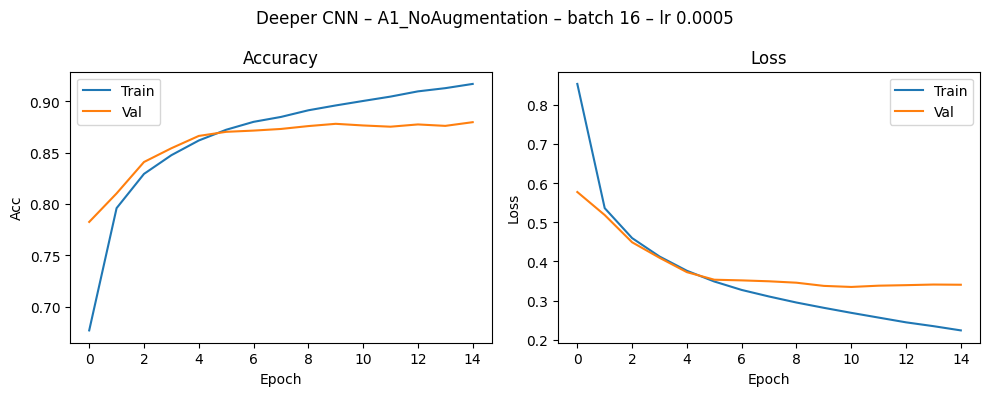

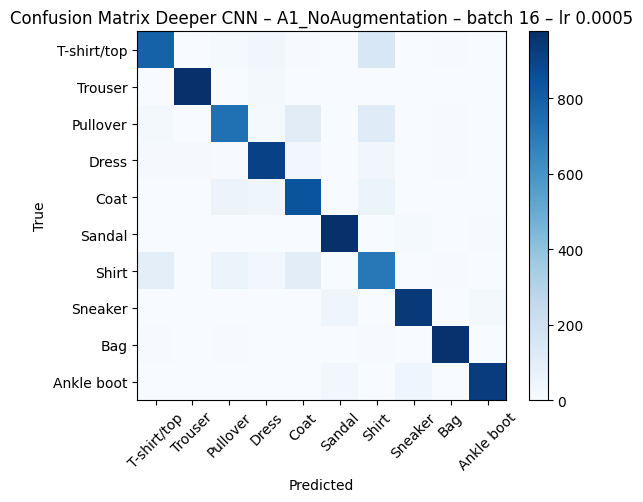


Training Deeper CNN with EARLY STOP – aug=A1_NoAugmentation, batch=32, epochs=15, lr=0.001, seed=42
Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - accuracy: 0.5477 - loss: 1.1873 - val_accuracy: 0.7852 - val_loss: 0.5760
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7969 - loss: 0.5363 - val_accuracy: 0.8356 - val_loss: 0.4475
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8415 - loss: 0.4359 - val_accuracy: 0.8478 - val_loss: 0.4006
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8575 - loss: 0.3862 - val_accuracy: 0.8608 - val_loss: 0.3699
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8702 - loss: 0.3531 - val_accuracy: 0.8682 - val_loss: 0.3529
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8775 - loss: 0.3301 - val_accuracy: 0.8734 - val_loss: 0.3437
Epoch 7/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8841 - loss: 0.3106 - val_accuracy: 0.8788 - val_l

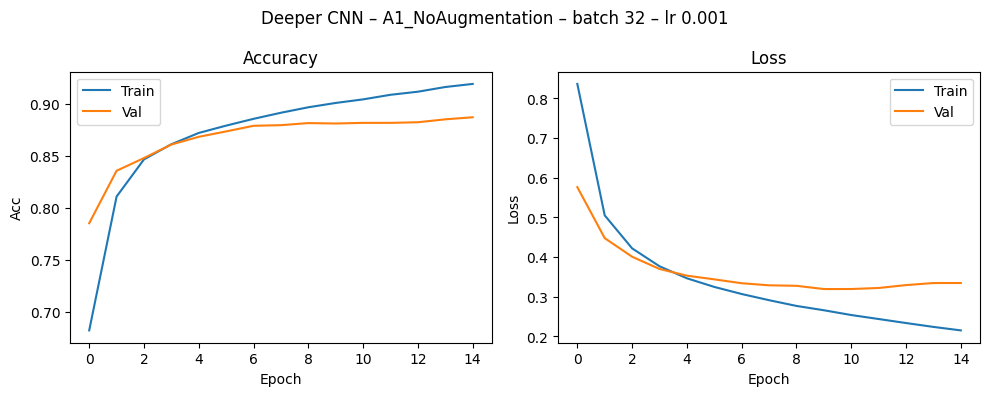

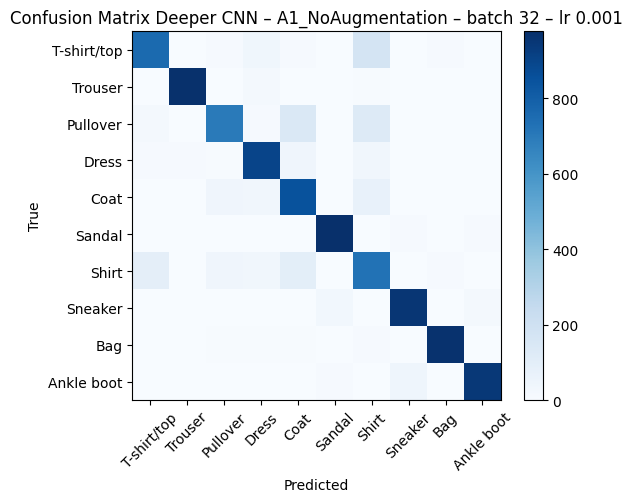


Training Deeper CNN with EARLY STOP – aug=A1_NoAugmentation, batch=64, epochs=15, lr=0.002, seed=42
Epoch 1/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.0994 - loss: 2.3030 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.0963 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epo

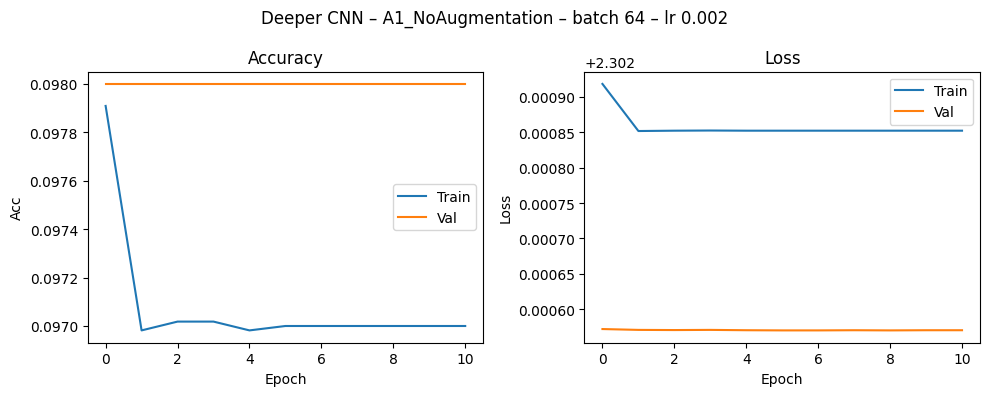

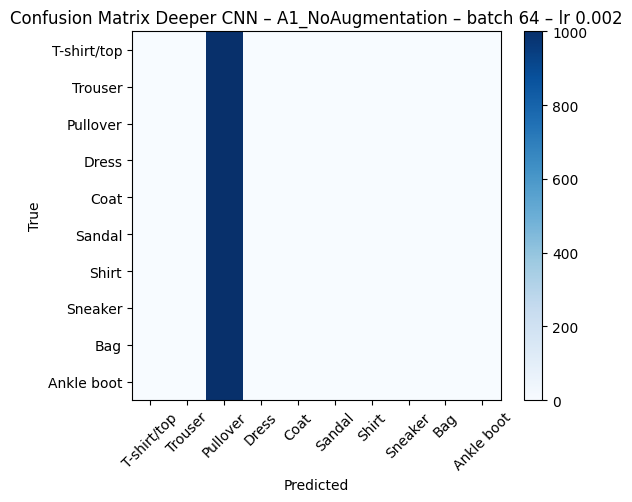


Training Deeper CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=16, epochs=15, lr=0.0005, seed=42
Epoch 1/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 23s 6ms/step - accuracy: 0.1000 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0977 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0972 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 4/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 5/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0976 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 6/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027


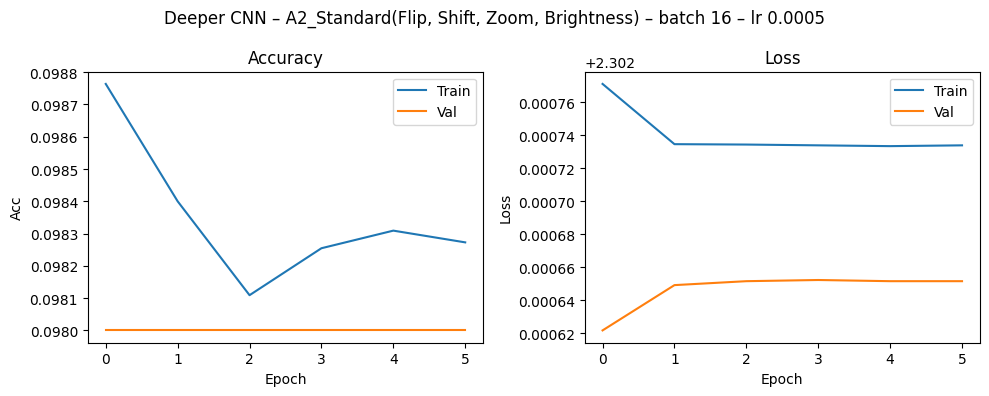

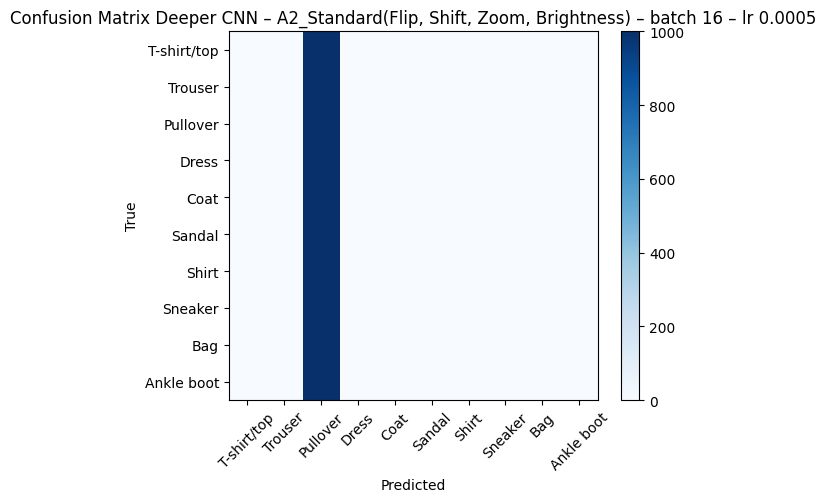


Training Deeper CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=32, epochs=15, lr=0.001, seed=42
Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.0998 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0972 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026


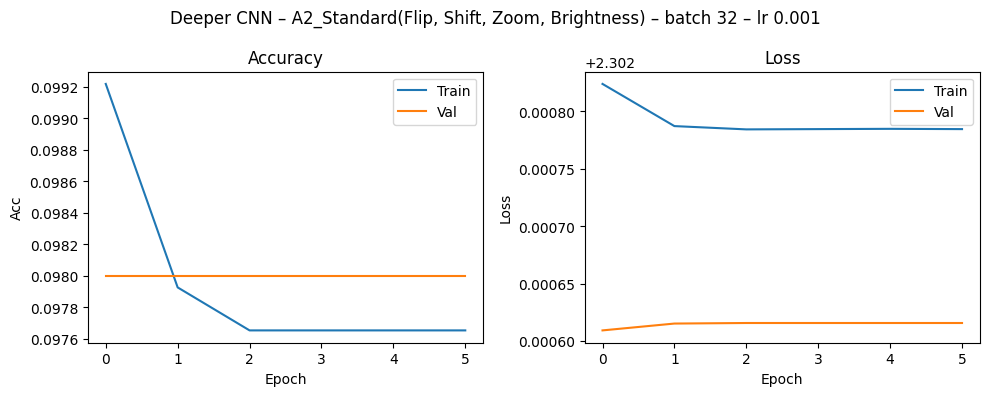

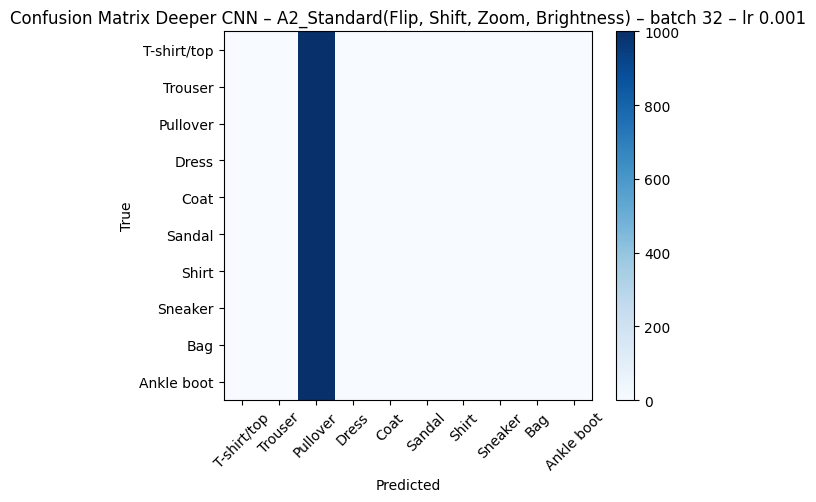


Training Deeper CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=64, epochs=15, lr=0.002, seed=42
Epoch 1/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.0977 - loss: 2.3030 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0957 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.09

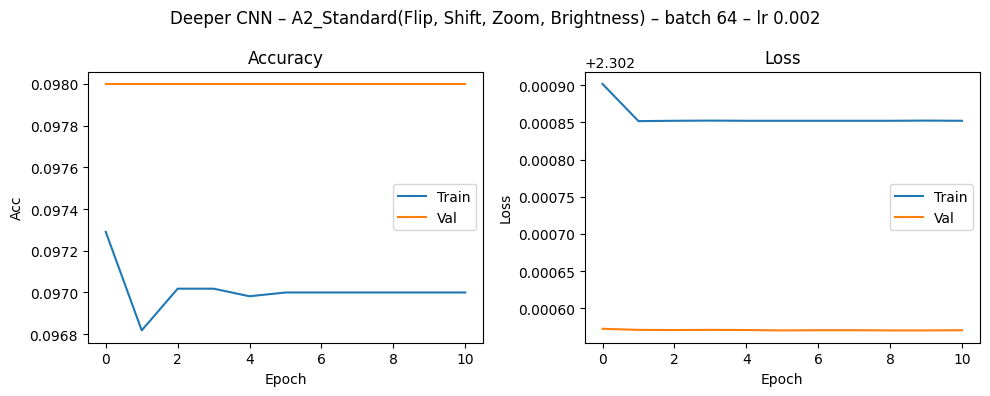

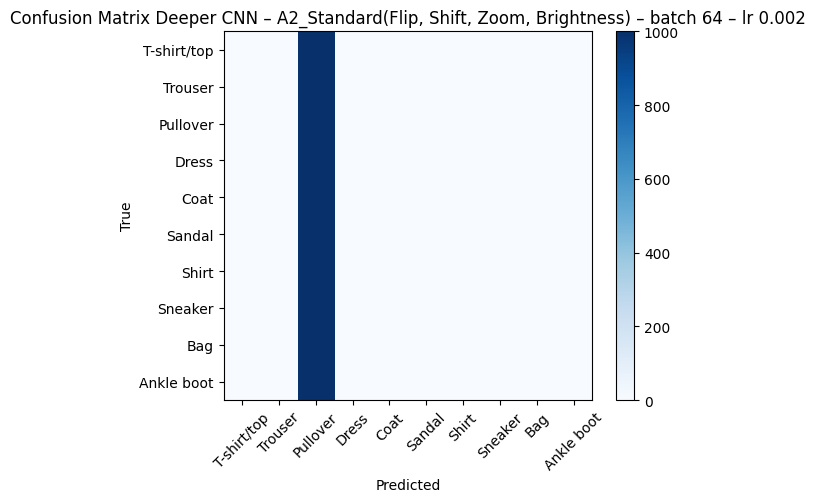


Training Deeper CNN with EARLY STOP – aug=A3_RotationOnly, batch=16, epochs=15, lr=0.0005, seed=42
Epoch 1/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 22s 6ms/step - accuracy: 0.0980 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0974 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 3/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 4/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 5/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 6/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027


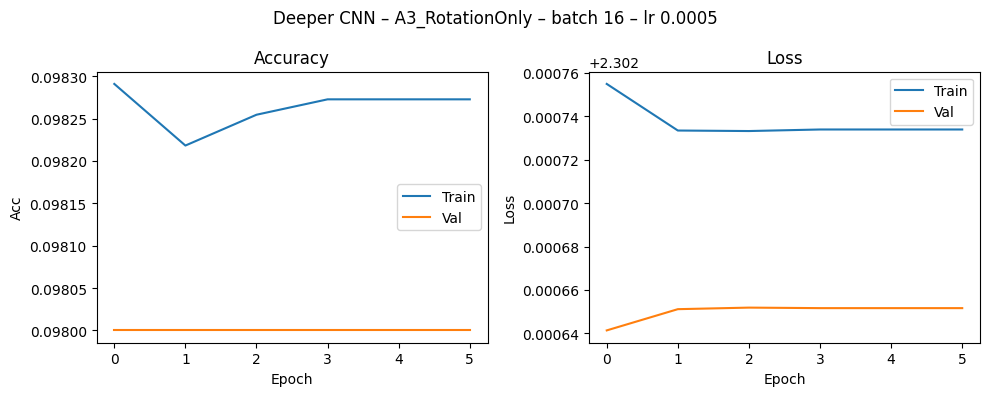

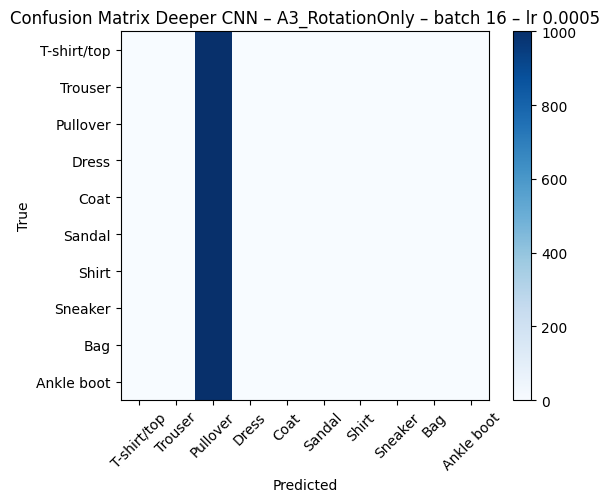


Training Deeper CNN with EARLY STOP – aug=A3_RotationOnly, batch=32, epochs=15, lr=0.001, seed=42
Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.0982 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0967 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026


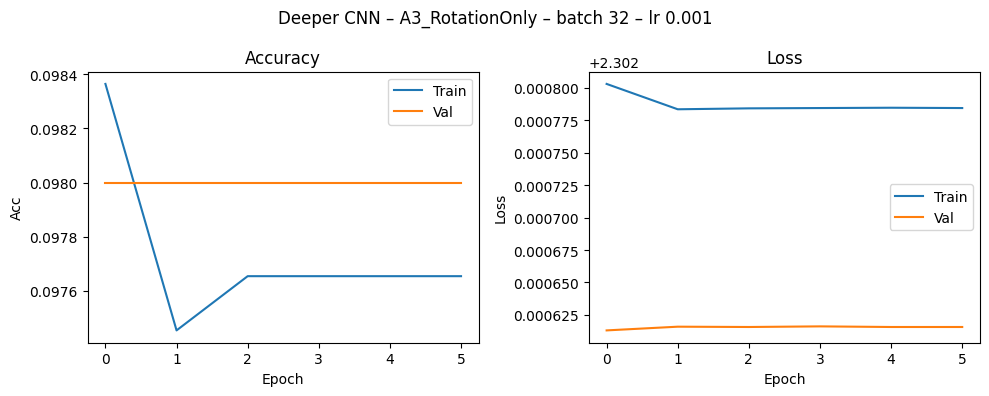

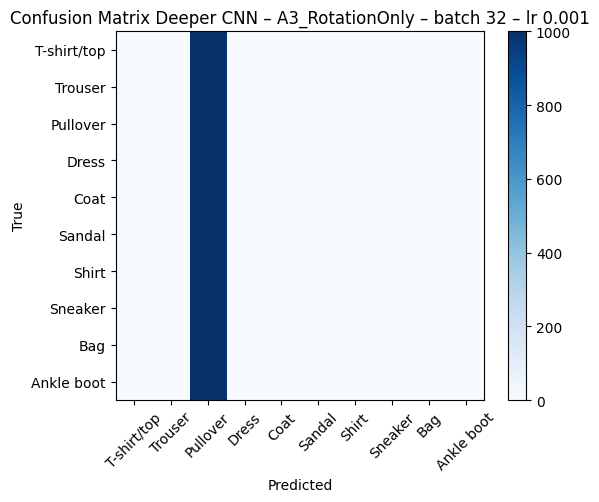


Training Deeper CNN with EARLY STOP – aug=A3_RotationOnly, batch=64, epochs=15, lr=0.002, seed=42
Epoch 1/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.0980 - loss: 2.3030 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0961 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026


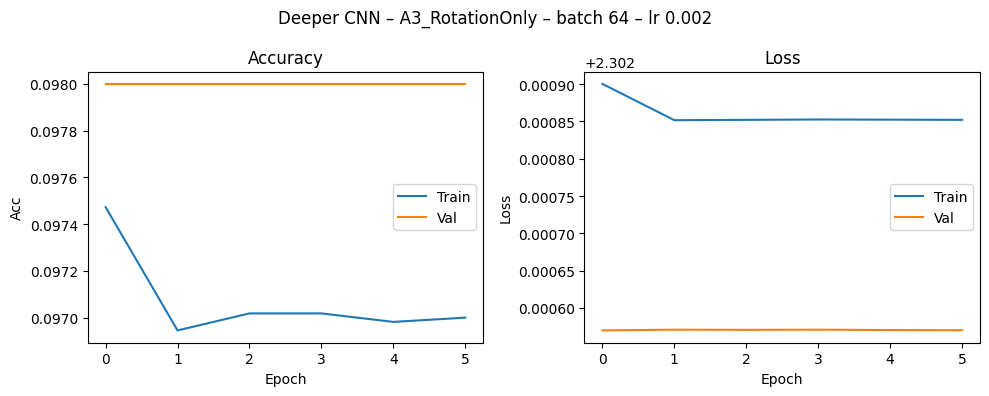

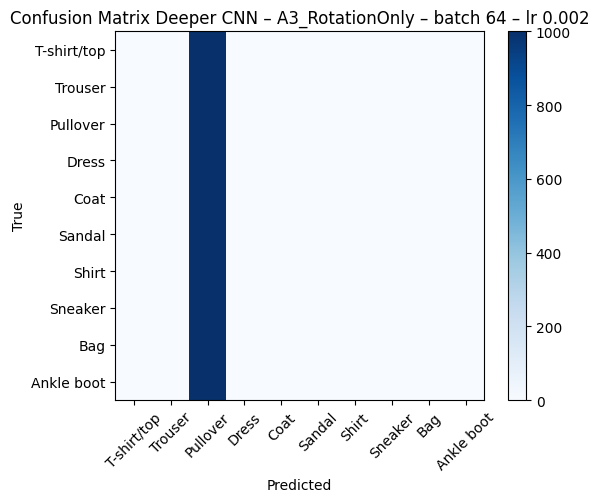


Training Deeper CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=16, epochs=15, lr=0.0005, seed=42
Epoch 1/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 24s 6ms/step - accuracy: 0.0981 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0976 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 4/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 5/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027
Epoch 6/15
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 21s 6ms/step - accuracy: 0.0975 - loss: 2.3027 - val_accuracy: 0.0980 - val_loss: 2.3027


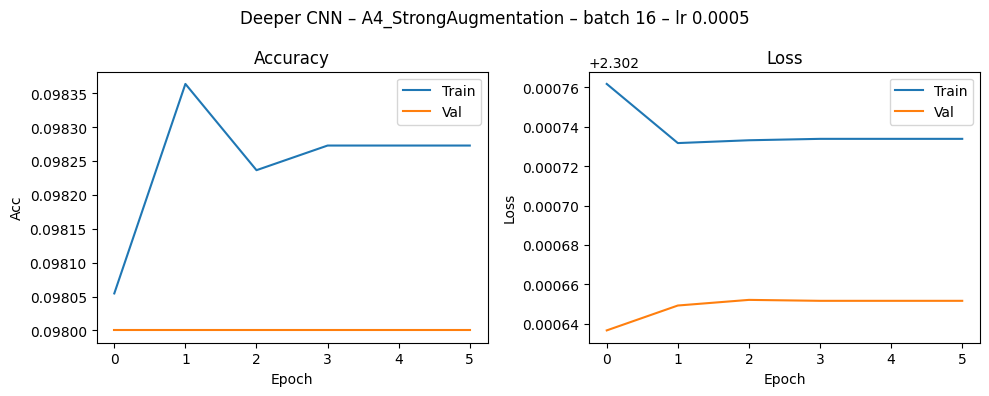

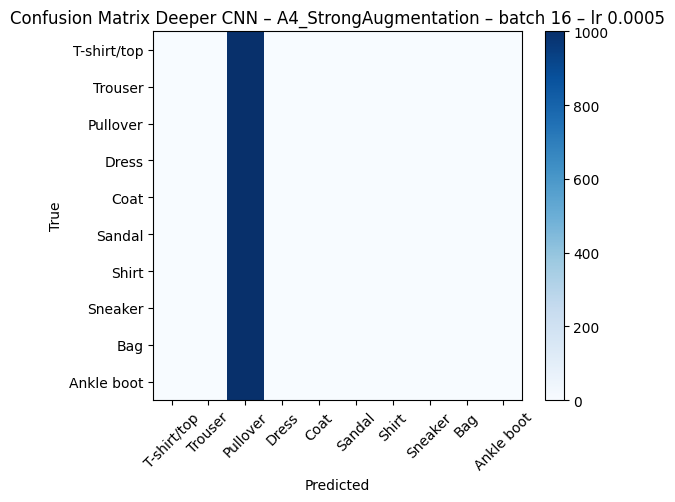


Training Deeper CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=32, epochs=15, lr=0.001, seed=42
Epoch 1/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.0984 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0959 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.0970 - loss: 2.3028 - val_accuracy: 0.0980 - val_loss: 2.3026


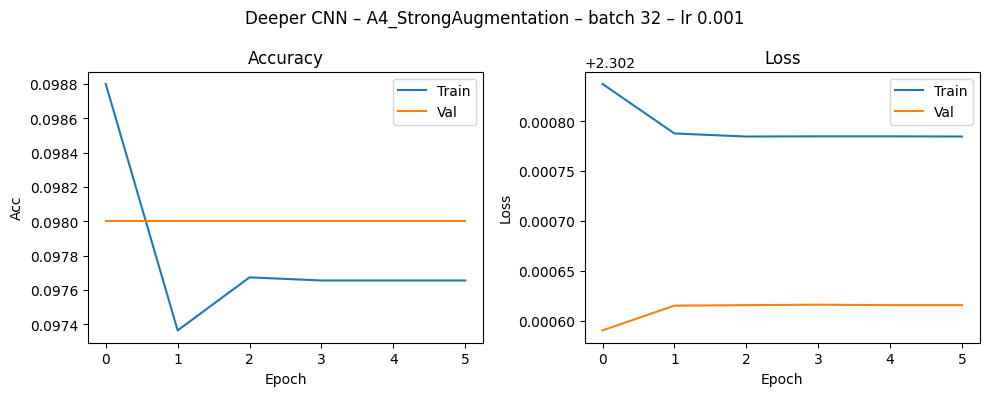

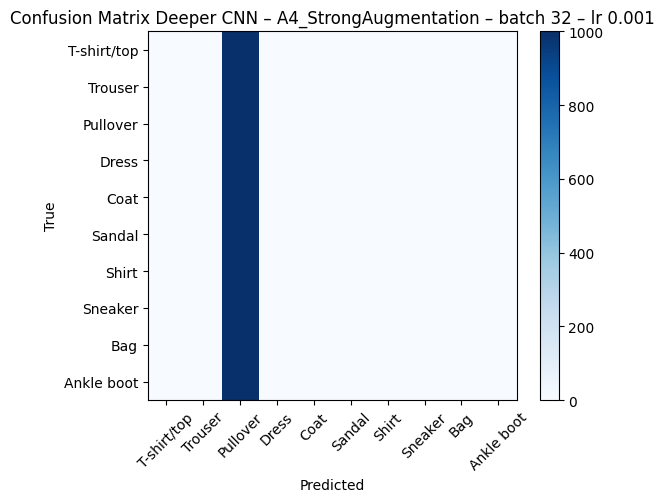


Training Deeper CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=64, epochs=15, lr=0.002, seed=42
Epoch 1/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.0988 - loss: 2.3030 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0963 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 5/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 6/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026
Epoch 7/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0965 - loss: 2.3029 - val_accuracy: 0.0980 - val_loss: 2.3026

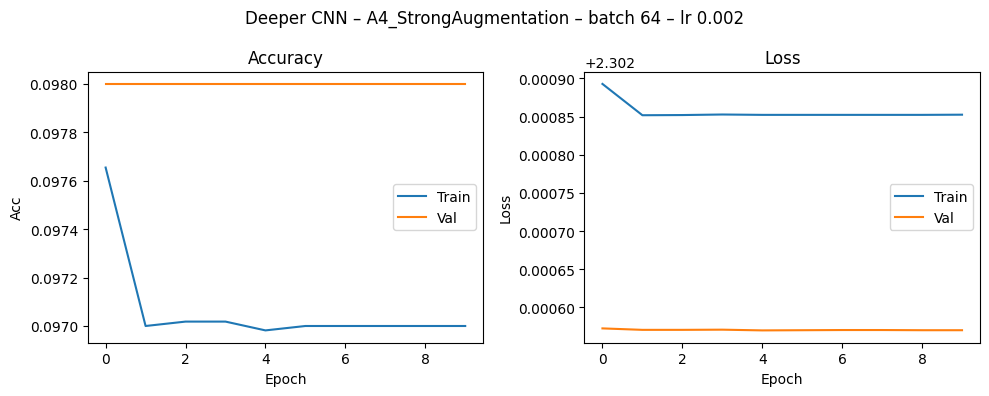

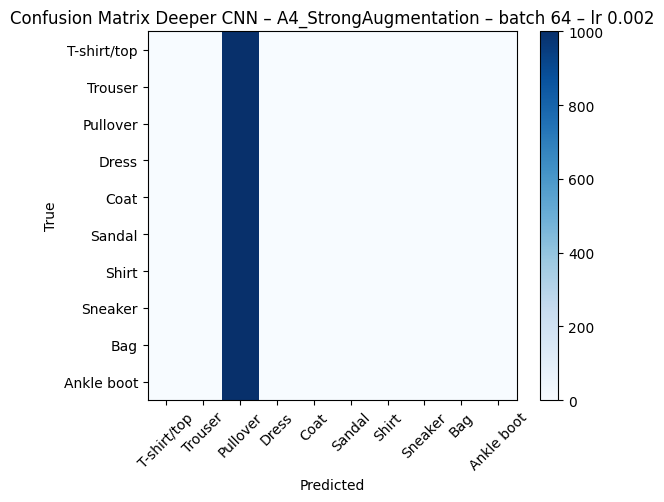

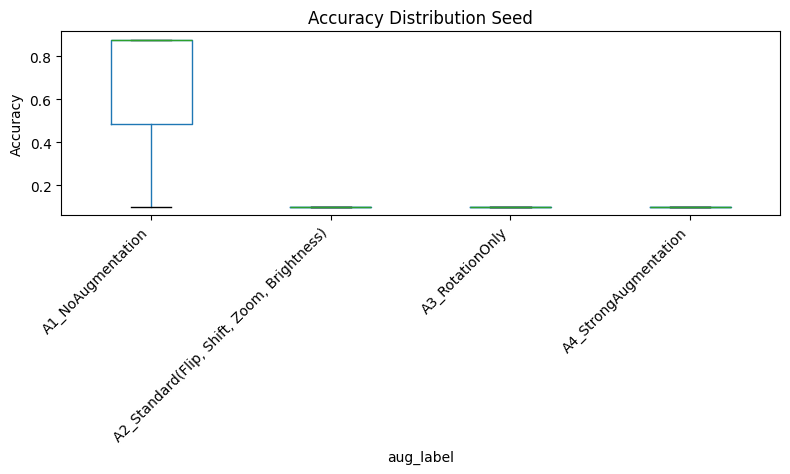

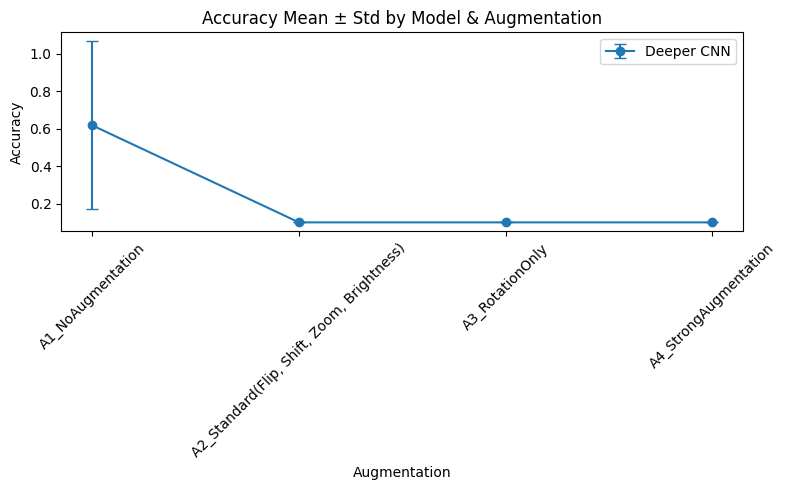


Metrics for Deeper CNN with A1_NoAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
0,42,0.878,0.878,0.037,15,9.22
1,42,0.875,0.876,0.032,15,5.35
2,42,0.100,0.018,-0.000,1,3.15



Metrics for Deeper CNN with A2_Standard(Flip, Shift, Zoom, Brightness)


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
3,42,0.1,0.018,0.001,1,21.18
4,42,0.1,0.018,0.001,1,10.79
5,42,0.1,0.018,-0.001,1,5.57



Metrics for Deeper CNN with A3_RotationOnly


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
6,42,0.1,0.018,0.000,1,20.49
7,42,0.1,0.018,0.000,1,10.67
8,42,0.1,0.018,-0.001,1,5.62



Metrics for Deeper CNN with A4_StrongAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
9,42,0.1,0.018,0.000,1,21.78
10,42,0.1,0.018,0.001,1,11.17
11,42,0.1,0.018,-0.000,1,5.73


In [ ]:
# 5.2 Deeper CNN: Training, Evaluation, and Output Generation (Early Stopping)
# Initialize result containers
results_es = []
histories = {}
confusions = {}
trained_models = {}
# Seed and parameter grid
SEEDS = [42]
PARAMS_M1 = [
    {"batch_size": 16, "epochs": 15, "lr": 5e-4},
    {"batch_size": 32, "epochs": 15, "lr": 1e-3},
    {"batch_size": 64, "epochs": 15, "lr": 2e-3}
]

# Augmentation strategies
AUGS = {
    "A1_NoAugmentation": None,
    "A2_Standard(Flip, Shift, Zoom, Brightness)": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1)
    ]),
    "A3_RotationOnly": keras.Sequential([
        layers.RandomRotation(0.2)
    ]),
    "A4_StrongAugmentation": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2)
    ])
}

# Class labels
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Model builder
def build_deeper_cnn(aug=None, lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    if aug is not None:
        x = aug(x, training=True)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="deeper_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Seed control
def set_seed(seed):
    import os, random
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

# Train once
def train_once(model, batch_size, max_epochs, seed, early_stop=True):
    set_seed(seed)
    callbacks = []
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True))
    start = time.time()
    hist = model.fit(x_train, y_train,
                     validation_data=(x_val, y_val),
                     batch_size=batch_size,
                     epochs=max_epochs,
                     verbose=1,
                     callbacks=callbacks)
    dur = time.time() - start
    best_ep = np.argmax(hist.history["val_accuracy"]) + 1
    return hist, dur, best_ep

# Evaluate
def eval_on_test(model):
    preds = model.predict(x_test, verbose=0)
    y_pred = np.argmax(preds, axis=1)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    cm = confusion_matrix(y_test, y_pred)
    return acc, f1, cm, y_pred

# Accuracy gap
def train_val_gap(hist):
    best_ep = np.argmax(hist.history["val_accuracy"])
    train_acc = hist.history["accuracy"][best_ep]
    val_acc = hist.history["val_accuracy"][best_ep]
    return round(train_acc - val_acc, 3)

# Training loop with early stopping
for aug_key in AUGS:
    for config in PARAMS_M1:
        for seed in SEEDS:
            print(f"\nTraining Deeper CNN with EARLY STOP – aug={aug_key}, batch={config['batch_size']}, epochs={config['epochs']}, lr={config['lr']}, seed={seed}")
            model = build_deeper_cnn(aug=AUGS[aug_key], lr=config["lr"])
            hist, dur, best_ep = train_once(model, config["batch_size"], config["epochs"], seed, early_stop=True)
            acc, f1, cm, y_pred = eval_on_test(model)
            gap = train_val_gap(hist)
            results_es.append(dict(model="Deeper CNN", aug=aug_key,
                                   batch=config["batch_size"], epochs=config["epochs"],
                                   lr=config["lr"], seed=seed, early_stop=True,
                                   acc=round(acc, 3), macro_f1=round(f1, 3),
                                   gap=round(gap, 3), best_epoch=best_ep,
                                   actual_epochs=len(hist.history["val_accuracy"]),
                                   sec_per_epoch=round(dur / len(hist.history["val_accuracy"]), 2)))
            if seed == 42:
                key = ("Deeper CNN", aug_key, config["batch_size"], config["epochs"], config["lr"])
                histories[key] = hist
                confusions[key] = cm
                trained_models[key] = model
                plot_history(hist, f"Deeper CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")
                plot_confusion(cm, f"Confusion Matrix Deeper CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")

# Create df_es
df_es = pd.DataFrame(results_es)
df_es = df_es[["model", "aug", "seed", "batch", "epochs", "lr", "early_stop",
               "acc", "macro_f1", "gap", "best_epoch", "actual_epochs", "sec_per_epoch"]]
df_es = df_es.sort_values(by=["aug", "batch", "epochs", "lr", "seed"])

# Generate summary plots and tables
plot_box_accuracy(df_es)
plot_errorbar_accuracy(df_es)

# Display metrics tables for all augmentations
for aug_key in ["A1_NoAugmentation", "A2_Standard(Flip, Shift, Zoom, Brightness)", "A3_RotationOnly", "A4_StrongAugmentation"]:
    table_metrics(df_es, model="Deeper CNN", aug=aug_key)

df_es_deeper = df_es.copy()

# --- Add models to global_trained_models ---
if "global_trained_models" not in globals():
    global_trained_models = {}

df_local = df_es_deeper
for key, model in trained_models.items():
    model_name, aug_key, *_ = key
    if not df_local[(df_local["model"] == model_name) & (df_local["aug"] == aug_key) & (df_local["seed"] == 42)].empty:
        global_trained_models[(model_name + " (EarlyStop)", aug_key)] = model



### 5.3 Training : BatchNorm CNN (Early Stopping)


Training BatchNorm CNN with EARLY STOP – aug=A1_NoAugmentation, batch=16, epochs=20, lr=0.0005, seed=42
Epoch 1/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - accuracy: 0.7984 - loss: 0.5751 - val_accuracy: 0.8266 - val_loss: 0.4706
Epoch 2/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8798 - loss: 0.3321 - val_accuracy: 0.8714 - val_loss: 0.3638
Epoch 3/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9027 - loss: 0.2734 - val_accuracy: 0.8876 - val_loss: 0.3297
Epoch 4/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9176 - loss: 0.2295 - val_accuracy: 0.9044 - val_loss: 0.2749
Epoch 5/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9286 - loss: 0.1956 - val_accuracy: 0.8748 - val_loss: 0.3992
Epoch 6/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9383 - loss: 0.1668 - val_accuracy: 0.8516 - val_loss: 0.4766
Epoch 7/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9511 - loss: 0.1374 - val_accuracy: 0.89

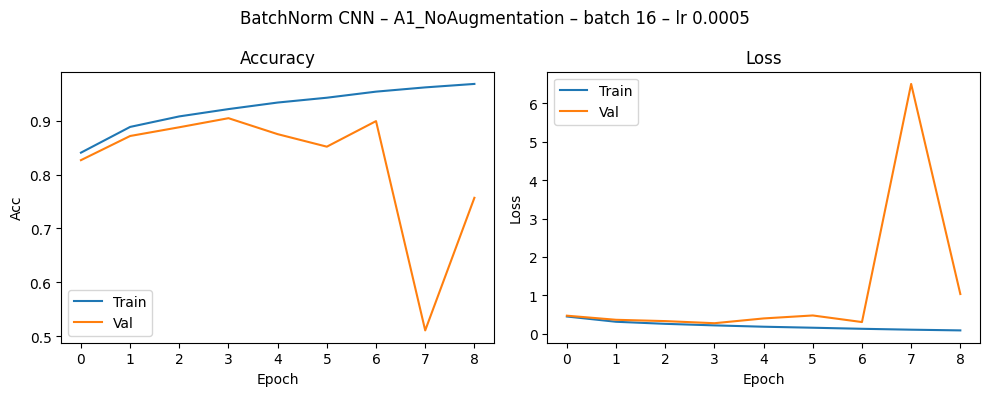

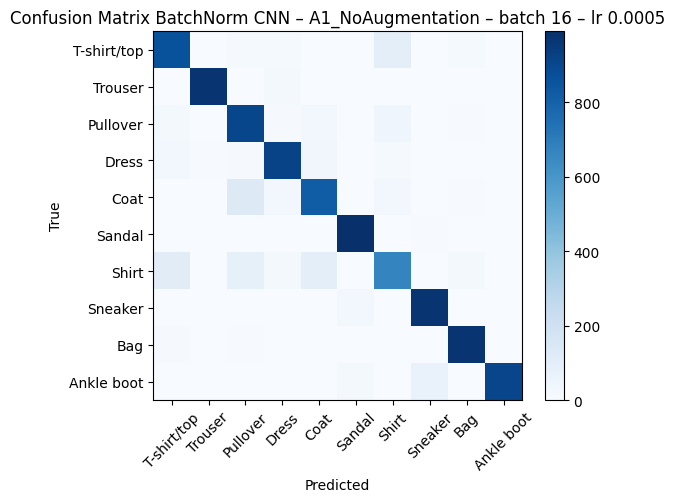


Training BatchNorm CNN with EARLY STOP – aug=A1_NoAugmentation, batch=32, epochs=20, lr=0.001, seed=42
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.8077 - loss: 0.5415 - val_accuracy: 0.8644 - val_loss: 0.4067
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8882 - loss: 0.3074 - val_accuracy: 0.8736 - val_loss: 0.3531
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9071 - loss: 0.2540 - val_accuracy: 0.8366 - val_loss: 0.4410
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9194 - loss: 0.2179 - val_accuracy: 0.8830 - val_loss: 0.3063
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9317 - loss: 0.1861 - val_accuracy: 0.9112 - val_loss: 0.2548
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9431 - loss: 0.1537 - val_accuracy: 0.9020 - val_loss: 0.2881
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9559 - loss: 0.1230 - val_accuracy: 0.9062 - va

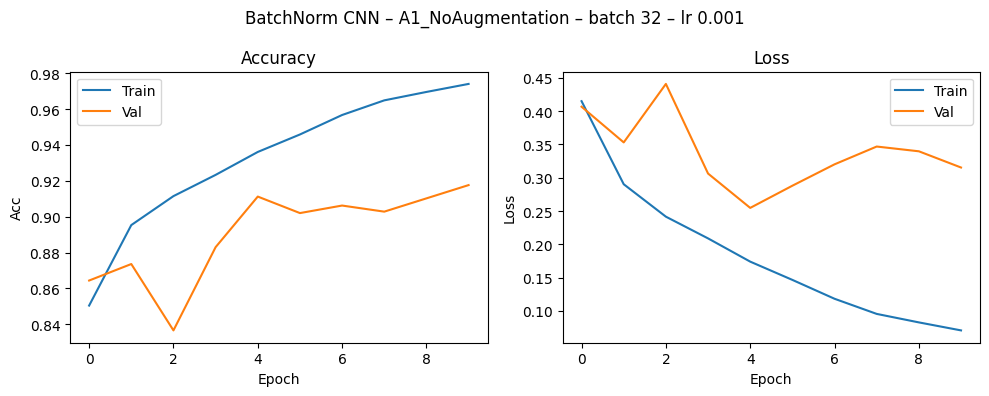

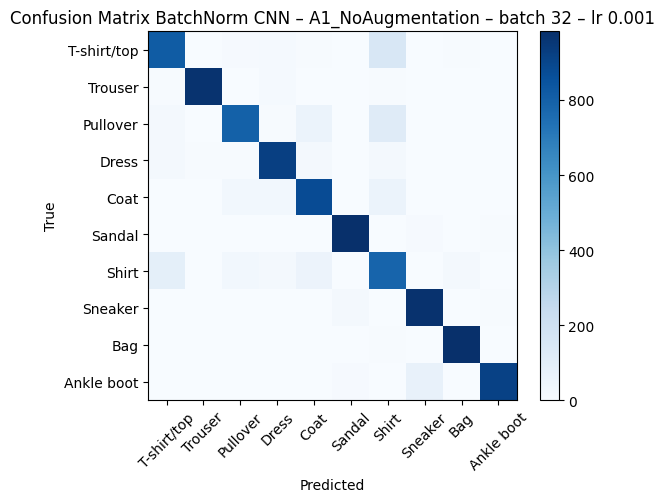


Training BatchNorm CNN with EARLY STOP – aug=A1_NoAugmentation, batch=64, epochs=20, lr=0.002, seed=42
Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8066 - loss: 0.5443 - val_accuracy: 0.8180 - val_loss: 0.5219
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8899 - loss: 0.3011 - val_accuracy: 0.8566 - val_loss: 0.3981
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9091 - loss: 0.2494 - val_accuracy: 0.8866 - val_loss: 0.3377
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9211 - loss: 0.2119 - val_accuracy: 0.8470 - val_loss: 0.4470
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9320 - loss: 0.1853 - val_accuracy: 0.8878 - val_loss: 0.3270
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9396 - loss: 0.1610 - val_accuracy: 0.8520 - val_loss: 0.5174
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9497 - loss: 0.1330 - val_accuracy: 0.8980 - val_loss: 0.3227

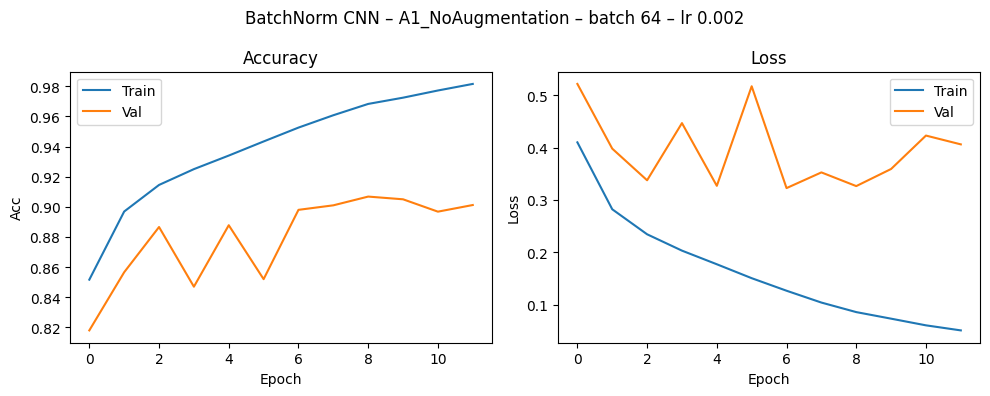

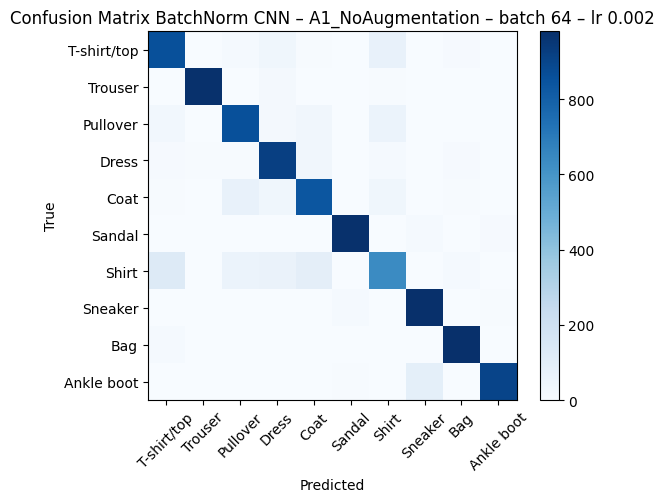


Training BatchNorm CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=16, epochs=20, lr=0.0005, seed=42
Epoch 1/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 39s 10ms/step - accuracy: 0.7183 - loss: 0.8035 - val_accuracy: 0.8132 - val_loss: 0.5254
Epoch 2/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8231 - loss: 0.4913 - val_accuracy: 0.8072 - val_loss: 0.5094
Epoch 3/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8494 - loss: 0.4167 - val_accuracy: 0.8410 - val_loss: 0.4226
Epoch 4/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8611 - loss: 0.3842 - val_accuracy: 0.8282 - val_loss: 0.4615
Epoch 5/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8734 - loss: 0.3522 - val_accuracy: 0.8516 - val_loss: 0.3884
Epoch 6/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8797 - loss: 0.3375 - val_accuracy: 0.8478 - val_loss: 0.3929
Epoch 7/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8849 - l

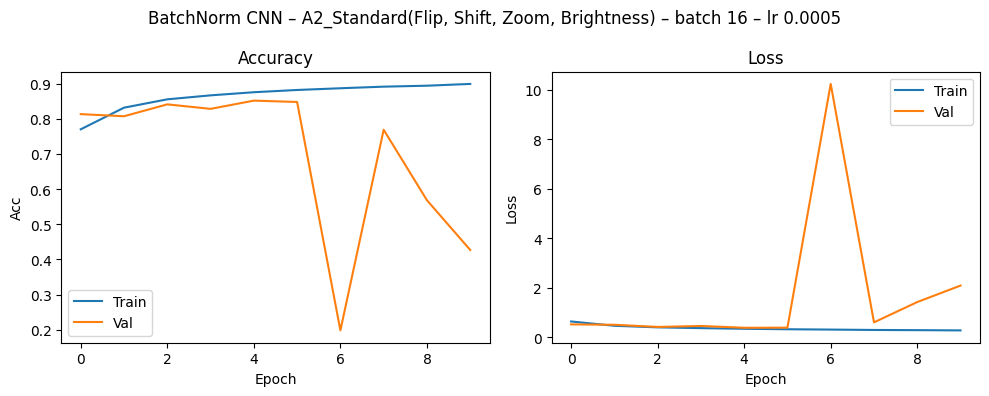

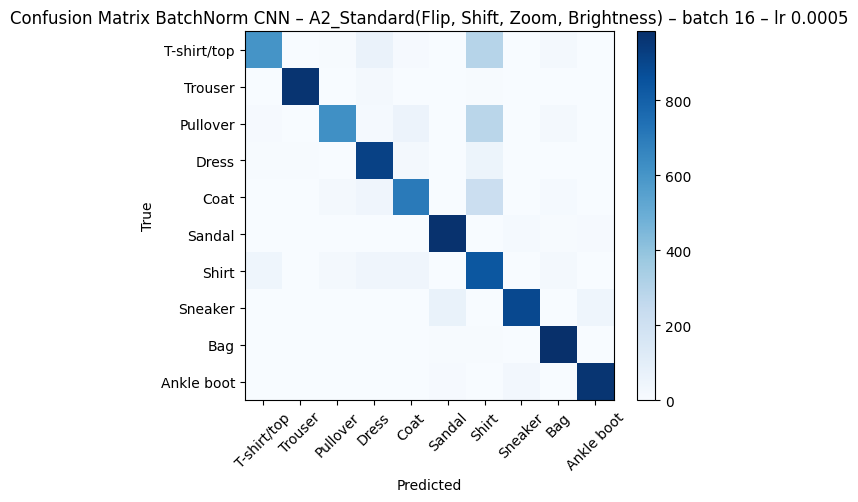


Training BatchNorm CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=32, epochs=20, lr=0.001, seed=42
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - accuracy: 0.7354 - loss: 0.7473 - val_accuracy: 0.7600 - val_loss: 0.6594
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8333 - loss: 0.4571 - val_accuracy: 0.8454 - val_loss: 0.4123
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8573 - loss: 0.3961 - val_accuracy: 0.8498 - val_loss: 0.4376
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8700 - loss: 0.3594 - val_accuracy: 0.8248 - val_loss: 0.4755
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8771 - loss: 0.3346 - val_accuracy: 0.8776 - val_loss: 0.3438
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8825 - loss: 0.3183 - val_accuracy: 0.8700 - val_loss: 0.3513
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8885 - lo

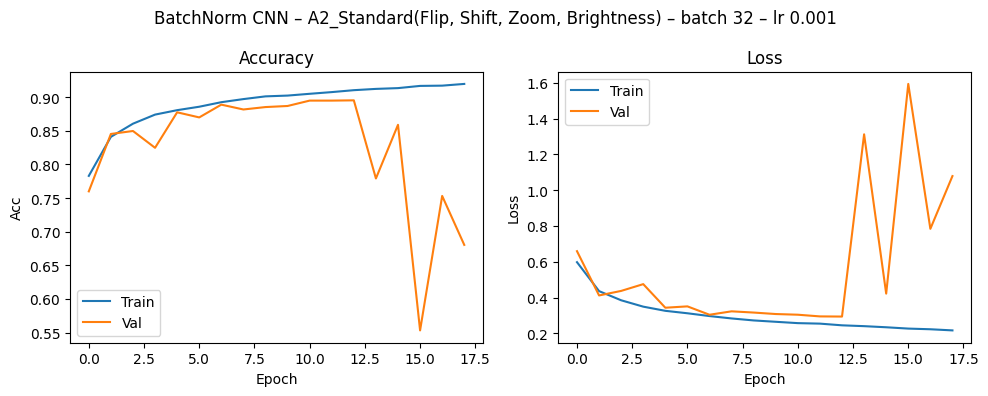

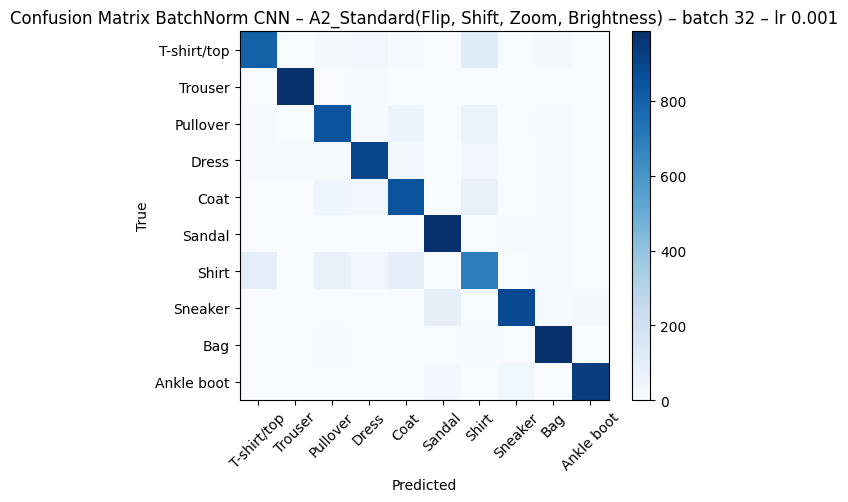


Training BatchNorm CNN with EARLY STOP – aug=A2_Standard(Flip, Shift, Zoom, Brightness), batch=64, epochs=20, lr=0.002, seed=42
Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.7409 - loss: 0.7330 - val_accuracy: 0.7190 - val_loss: 0.8905
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8389 - loss: 0.4375 - val_accuracy: 0.7160 - val_loss: 0.7776
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8627 - loss: 0.3746 - val_accuracy: 0.8416 - val_loss: 0.4694
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8724 - loss: 0.3490 - val_accuracy: 0.8022 - val_loss: 0.5317
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8828 - loss: 0.3217 - val_accuracy: 0.8706 - val_loss: 0.3497
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8896 - loss: 0.3037 - val_accuracy: 0.7740 - val_loss: 0.6233
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8929 - loss: 0.2907 - val_acc

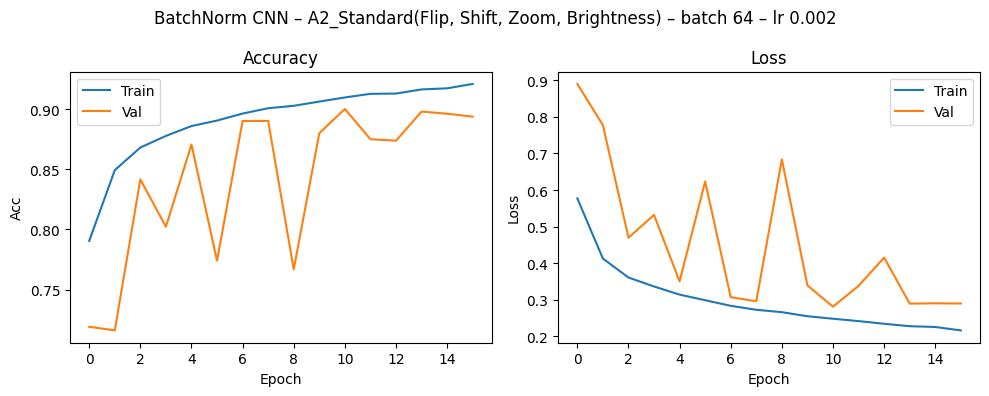

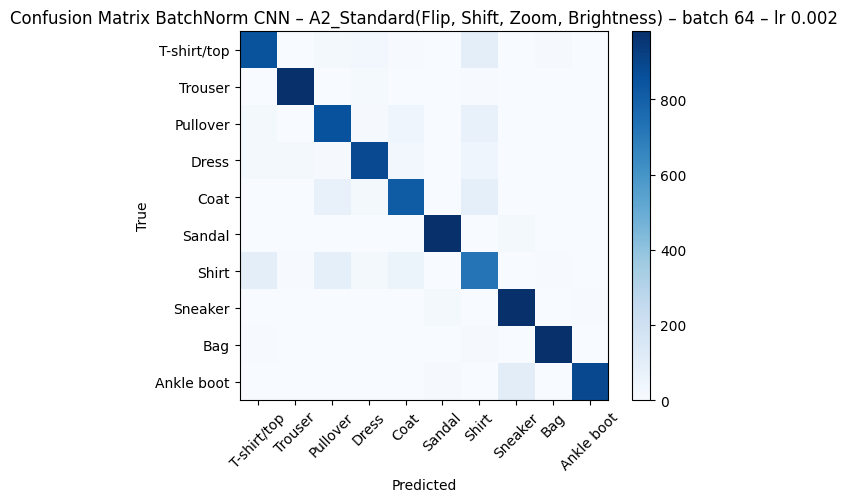


Training BatchNorm CNN with EARLY STOP – aug=A3_RotationOnly, batch=16, epochs=20, lr=0.0005, seed=42
Epoch 1/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 39s 10ms/step - accuracy: 0.6645 - loss: 0.9565 - val_accuracy: 0.7680 - val_loss: 0.6363
Epoch 2/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.7913 - loss: 0.5847 - val_accuracy: 0.1780 - val_loss: 8.2092
Epoch 3/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8227 - loss: 0.4975 - val_accuracy: 0.7774 - val_loss: 0.6601
Epoch 4/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8358 - loss: 0.4588 - val_accuracy: 0.7994 - val_loss: 0.5830
Epoch 5/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8487 - loss: 0.4221 - val_accuracy: 0.8424 - val_loss: 0.4474
Epoch 6/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8551 - loss: 0.3985 - val_accuracy: 0.7624 - val_loss: 0.7669
Epoch 7/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 35s 10ms/step - accuracy: 0.8627 - loss: 0.3817 - val_accuracy:

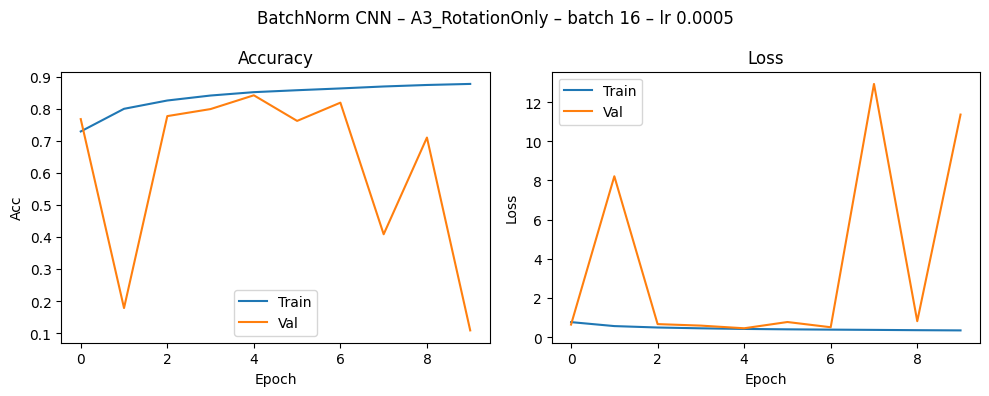

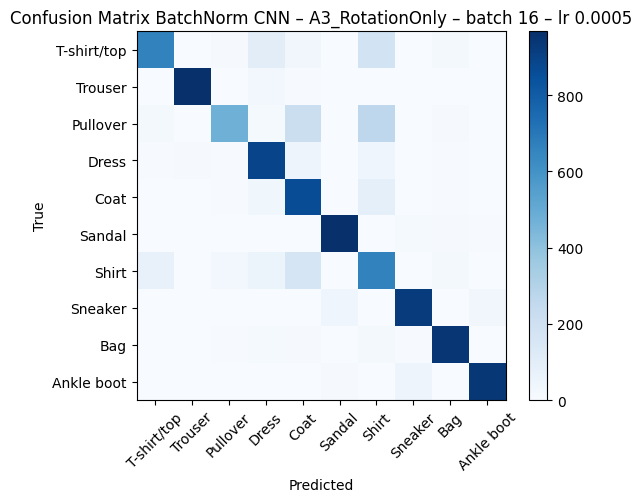


Training BatchNorm CNN with EARLY STOP – aug=A3_RotationOnly, batch=32, epochs=20, lr=0.001, seed=42
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 22s 10ms/step - accuracy: 0.6839 - loss: 0.9013 - val_accuracy: 0.7142 - val_loss: 0.8333
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8074 - loss: 0.5272 - val_accuracy: 0.7918 - val_loss: 0.5926
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8302 - loss: 0.4648 - val_accuracy: 0.7390 - val_loss: 0.7883
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8486 - loss: 0.4182 - val_accuracy: 0.7988 - val_loss: 0.5680
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8561 - loss: 0.3896 - val_accuracy: 0.8522 - val_loss: 0.4264
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8683 - loss: 0.3647 - val_accuracy: 0.8578 - val_loss: 0.3968
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8750 - loss: 0.3482 - val_accuracy: 

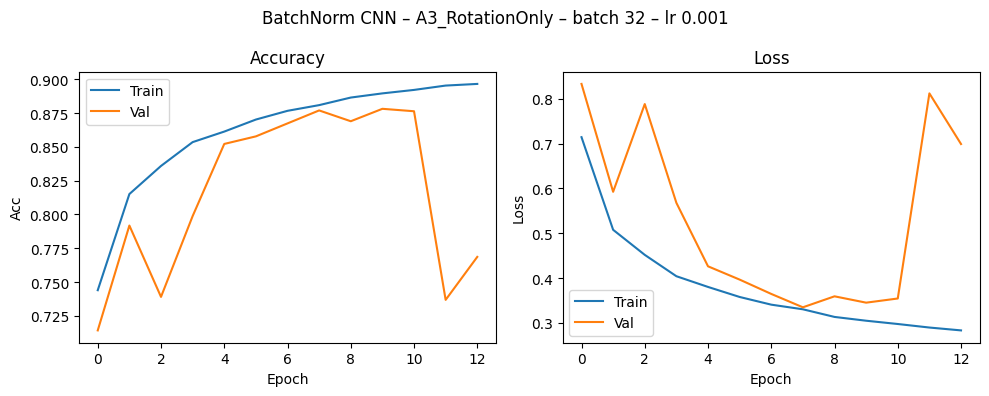

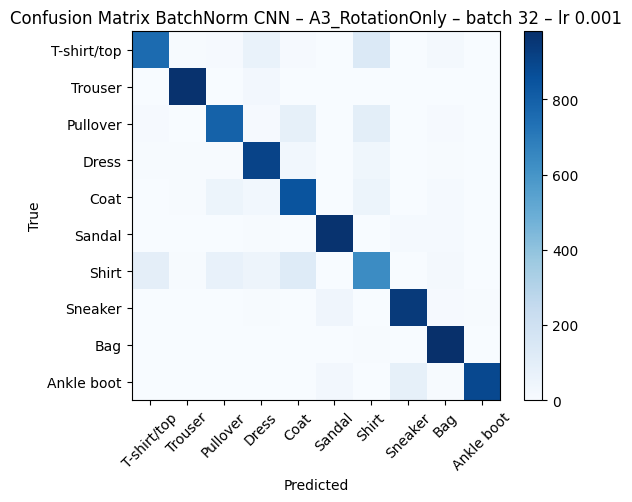


Training BatchNorm CNN with EARLY STOP – aug=A3_RotationOnly, batch=64, epochs=20, lr=0.002, seed=42
Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.6958 - loss: 0.8727 - val_accuracy: 0.7734 - val_loss: 0.6304
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8135 - loss: 0.5150 - val_accuracy: 0.7716 - val_loss: 0.6056
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8382 - loss: 0.4478 - val_accuracy: 0.7884 - val_loss: 0.5744
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8580 - loss: 0.3916 - val_accuracy: 0.8426 - val_loss: 0.4495
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8641 - loss: 0.3746 - val_accuracy: 0.8542 - val_loss: 0.3901
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8702 - loss: 0.3563 - val_accuracy: 0.8462 - val_loss: 0.3937
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8737 - loss: 0.3455 - val_accuracy: 0.8496 - val_loss: 0

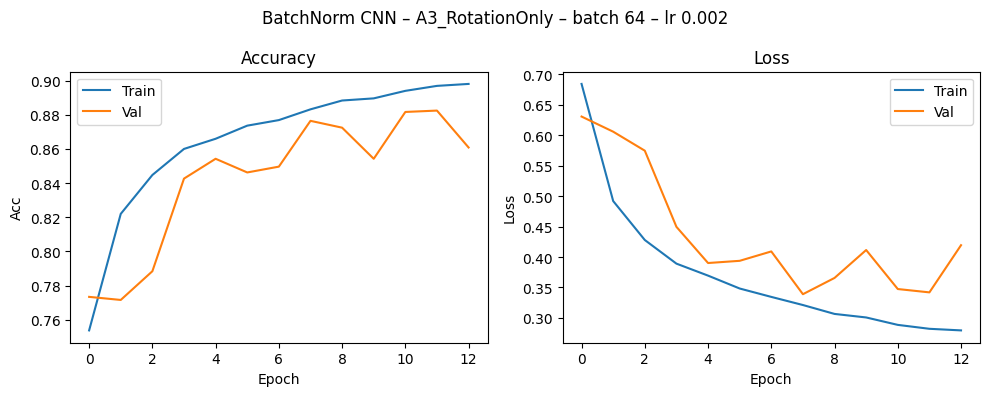

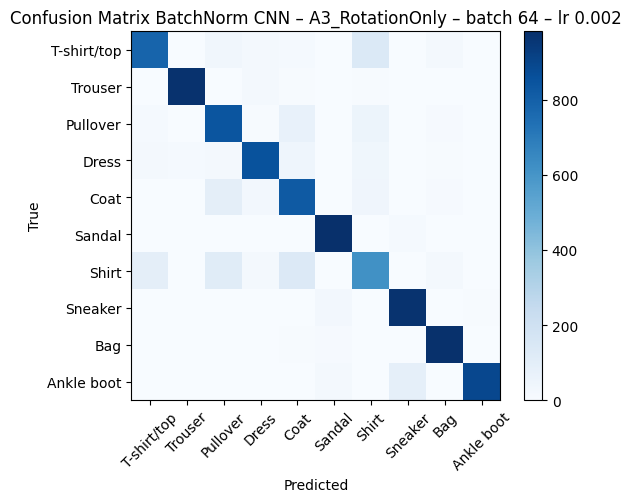


Training BatchNorm CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=16, epochs=20, lr=0.0005, seed=42
Epoch 1/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 40s 11ms/step - accuracy: 0.6138 - loss: 1.1061 - val_accuracy: 0.6920 - val_loss: 0.7925
Epoch 2/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 37s 11ms/step - accuracy: 0.7560 - loss: 0.6834 - val_accuracy: 0.7960 - val_loss: 0.5564
Epoch 3/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 36s 11ms/step - accuracy: 0.7835 - loss: 0.6009 - val_accuracy: 0.7196 - val_loss: 0.7771
Epoch 4/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 36s 11ms/step - accuracy: 0.8056 - loss: 0.5433 - val_accuracy: 0.7624 - val_loss: 0.6871
Epoch 5/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 37s 11ms/step - accuracy: 0.8180 - loss: 0.5051 - val_accuracy: 0.8454 - val_loss: 0.4339
Epoch 6/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 36s 11ms/step - accuracy: 0.8264 - loss: 0.4858 - val_accuracy: 0.5802 - val_loss: 1.3385
Epoch 7/20
3438/3438 ━━━━━━━━━━━━━━━━━━━━ 36s 11ms/step - accuracy: 0.8350 - loss: 0.4618 - val_acc

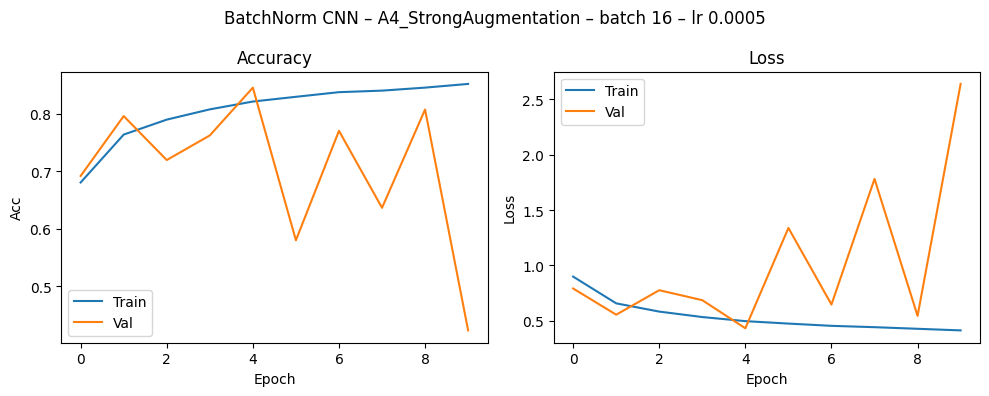

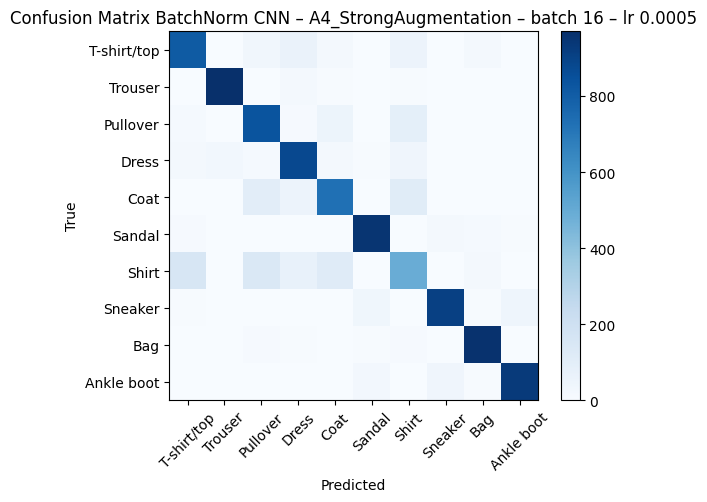


Training BatchNorm CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=32, epochs=20, lr=0.001, seed=42
Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 23s 11ms/step - accuracy: 0.6421 - loss: 1.0271 - val_accuracy: 0.6336 - val_loss: 1.0259
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.7613 - loss: 0.6531 - val_accuracy: 0.7196 - val_loss: 0.7687
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.7939 - loss: 0.5708 - val_accuracy: 0.6164 - val_loss: 1.1200
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.8117 - loss: 0.5191 - val_accuracy: 0.7932 - val_loss: 0.5632
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.8261 - loss: 0.4817 - val_accuracy: 0.7522 - val_loss: 0.6604
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.8310 - loss: 0.4607 - val_accuracy: 0.8334 - val_loss: 0.4439
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.8414 - loss: 0.4344 - val_accu

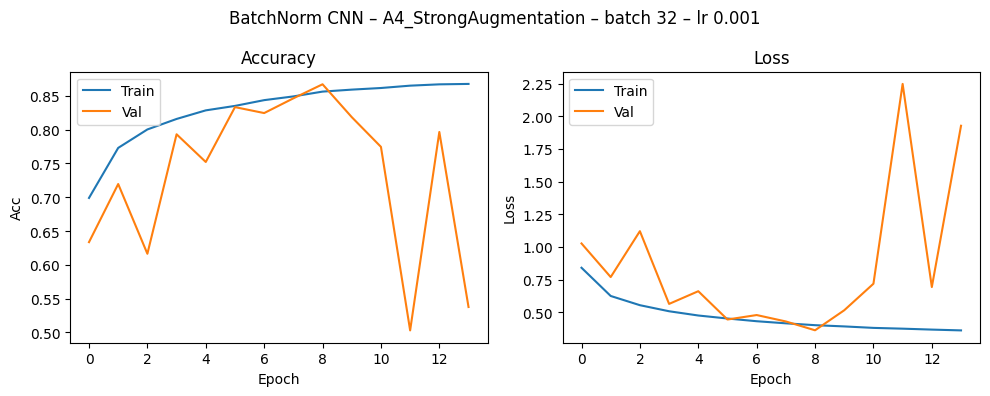

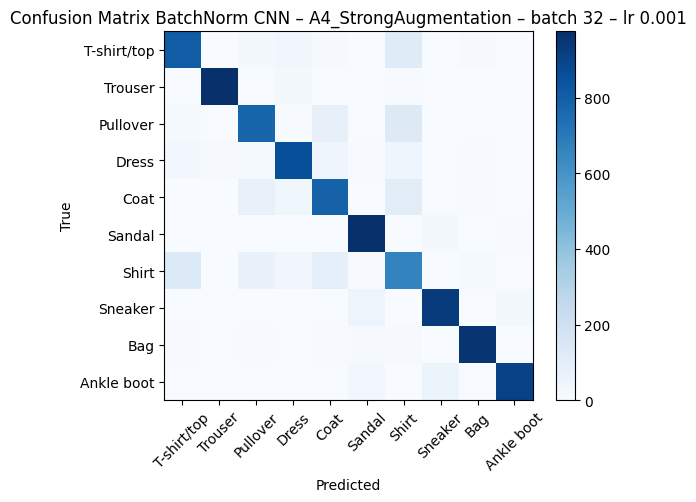


Training BatchNorm CNN with EARLY STOP – aug=A4_StrongAugmentation, batch=64, epochs=20, lr=0.002, seed=42
Epoch 1/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.6376 - loss: 1.0248 - val_accuracy: 0.5118 - val_loss: 2.0139
Epoch 2/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.7762 - loss: 0.6174 - val_accuracy: 0.6164 - val_loss: 1.3555
Epoch 3/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8050 - loss: 0.5364 - val_accuracy: 0.8176 - val_loss: 0.4914
Epoch 4/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8236 - loss: 0.4843 - val_accuracy: 0.7870 - val_loss: 0.5679
Epoch 5/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8368 - loss: 0.4516 - val_accuracy: 0.7682 - val_loss: 0.6510
Epoch 6/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8445 - loss: 0.4299 - val_accuracy: 0.8006 - val_loss: 0.5864
Epoch 7/20
860/860 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8498 - loss: 0.4138 - val_accuracy: 0.8438 - val_

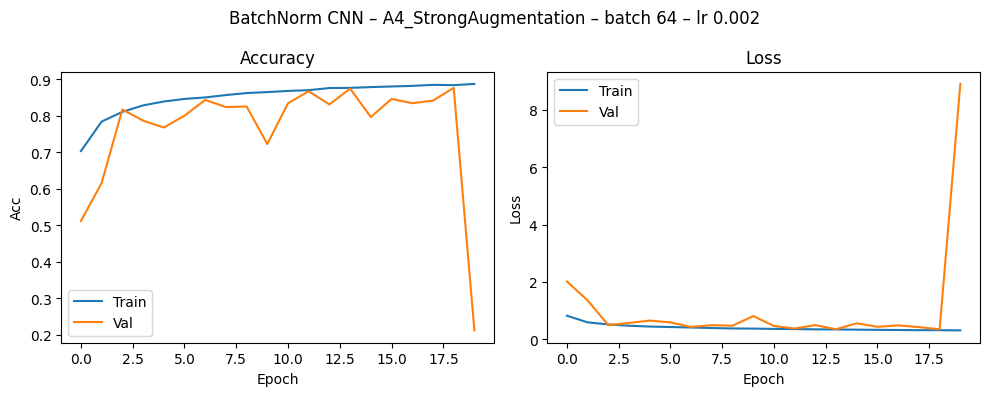

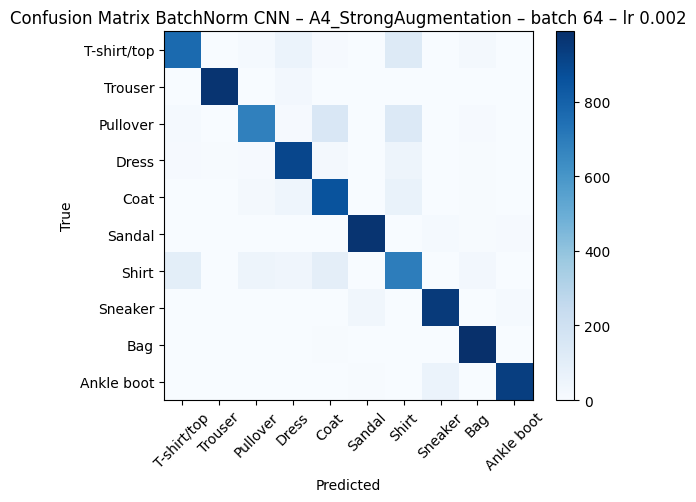

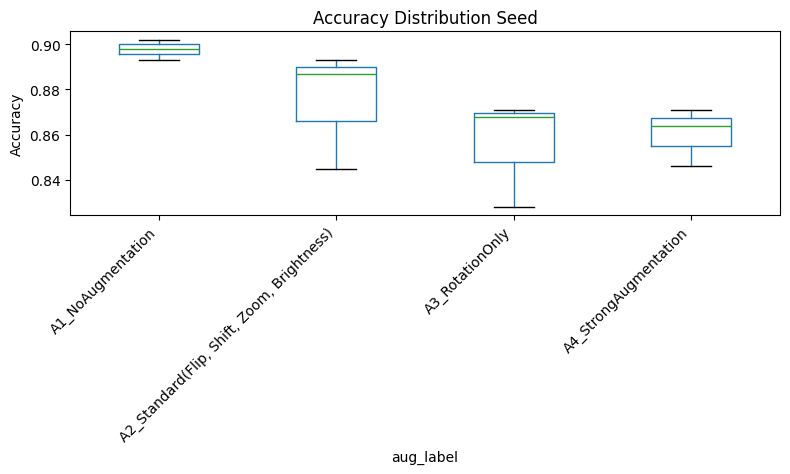

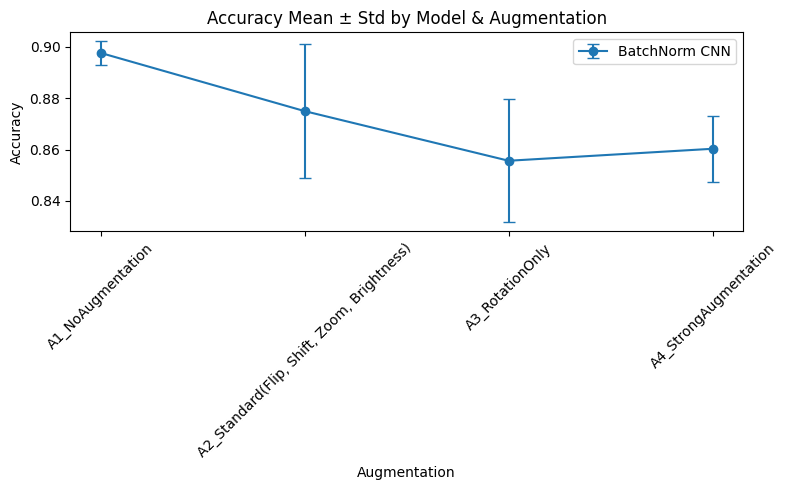


Metrics for BatchNorm CNN with A1_NoAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
0,42,0.898,0.897,0.017,4,11.28
1,42,0.902,0.903,0.056,10,6.27
2,42,0.893,0.891,0.061,9,3.61



Metrics for BatchNorm CNN with A2_Standard(Flip, Shift, Zoom, Brightness)


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
3,42,0.845,0.848,0.024,5,35.31
4,42,0.887,0.886,0.015,13,18.06
5,42,0.893,0.893,0.010,11,9.42



Metrics for BatchNorm CNN with A3_RotationOnly


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
6,42,0.828,0.827,0.010,5,35.48
7,42,0.868,0.867,0.011,10,17.97
8,42,0.871,0.870,0.014,12,9.31



Metrics for BatchNorm CNN with A4_StrongAugmentation


,seed,acc,macro_f1,gap,best_epoch,sec_per_epoch
9,42,0.846,0.843,-0.024,5,36.84
10,42,0.864,0.865,-0.011,9,18.81
11,42,0.871,0.871,0.008,19,9.69


In [ ]:
# 5.3 BatchNorm CNN: Training, Evaluation, and Output Generation (Early Stopping)
# Initialize result containers
results_es = []
histories = {}
confusions = {}
trained_models = {}
# Seed and parameter grid
SEEDS = [42]
PARAMS_M1 = [
    {"batch_size": 16, "epochs": 20, "lr": 5e-4},
    {"batch_size": 32, "epochs": 20, "lr": 1e-3},
    {"batch_size": 64, "epochs": 20, "lr": 2e-3}
]

# Augmentation strategies
AUGS = {
    "A1_NoAugmentation": None,
    "A2_Standard(Flip, Shift, Zoom, Brightness)": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1)
    ]),
    "A3_RotationOnly": keras.Sequential([
        layers.RandomRotation(0.2)
    ]),
    "A4_StrongAugmentation": keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2)
    ])
}

# Class labels
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Model builder for BatchNorm CNN
def build_batchnorm_cnn(aug=None, lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="input")
    x = layers.Rescaling(1./255)(inputs)
    if aug is not None:
        x = aug(x, training=True)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="batchnorm_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Seed control
def set_seed(seed):
    import os, random
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

# Train once
def train_once(model, batch_size, max_epochs, seed, early_stop=True):
    set_seed(seed)
    callbacks = []
    if early_stop:
        callbacks.append(keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True))
    start = time.time()
    hist = model.fit(x_train, y_train,
                     validation_data=(x_val, y_val),
                     batch_size=batch_size,
                     epochs=max_epochs,
                     verbose=1,
                     callbacks=callbacks)
    dur = time.time() - start
    best_ep = np.argmax(hist.history["val_accuracy"]) + 1
    return hist, dur, best_ep

# Evaluate
def eval_on_test(model):
    preds = model.predict(x_test, verbose=0)
    y_pred = np.argmax(preds, axis=1)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")
    cm = confusion_matrix(y_test, y_pred)
    return acc, f1, cm, y_pred

# Accuracy gap
def train_val_gap(hist):
    best_ep = np.argmax(hist.history["val_accuracy"])
    train_acc = hist.history["accuracy"][best_ep]
    val_acc = hist.history["val_accuracy"][best_ep]
    return round(train_acc - val_acc, 3)

# Training loop with early stopping
for aug_key in AUGS:
    for config in PARAMS_M1:
        for seed in SEEDS:
            print(f"\nTraining BatchNorm CNN with EARLY STOP – aug={aug_key}, batch={config['batch_size']}, epochs={config['epochs']}, lr={config['lr']}, seed={seed}")
            model = build_batchnorm_cnn(aug=AUGS[aug_key], lr=config["lr"])
            hist, dur, best_ep = train_once(model, config["batch_size"], config["epochs"], seed, early_stop=True)
            acc, f1, cm, y_pred = eval_on_test(model)
            gap = train_val_gap(hist)
            results_es.append(dict(model="BatchNorm CNN", aug=aug_key,
                                   batch=config["batch_size"], epochs=config["epochs"],
                                   lr=config["lr"], seed=seed, early_stop=True,
                                   acc=round(acc, 3), macro_f1=round(f1, 3),
                                   gap=round(gap, 3), best_epoch=best_ep,
                                   actual_epochs=len(hist.history["val_accuracy"]),
                                   sec_per_epoch=round(dur / len(hist.history["val_accuracy"]), 2)))
            if seed == 42:
                key = ("BatchNorm CNN", aug_key, config["batch_size"], config["epochs"], config["lr"])
                histories[key] = hist
                confusions[key] = cm
                trained_models[key] = model
                plot_history(hist, f"BatchNorm CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")
                plot_confusion(cm, f"Confusion Matrix BatchNorm CNN – {aug_key} – batch {config['batch_size']} – lr {config['lr']}")

# Create df_es
df_es = pd.DataFrame(results_es)
df_es = df_es[["model", "aug", "seed", "batch", "epochs", "lr", "early_stop",
               "acc", "macro_f1", "gap", "best_epoch", "actual_epochs", "sec_per_epoch"]]
df_es = df_es.sort_values(by=["aug", "batch", "epochs", "lr", "seed"])

# Generate summary plots and tables
plot_box_accuracy(df_es)
plot_errorbar_accuracy(df_es)

# Display metrics tables for all augmentations
for aug_key in ["A1_NoAugmentation", "A2_Standard(Flip, Shift, Zoom, Brightness)", "A3_RotationOnly", "A4_StrongAugmentation"]:
    table_metrics(df_es, model="BatchNorm CNN", aug=aug_key)
df_es_batchnorm = df_es.copy()

# --- Add models to global_trained_models ---
if "global_trained_models" not in globals():
    global_trained_models = {}

df_local = df_es_batchnorm
for key, model in trained_models.items():
    model_name, aug_key, *_ = key
    if not df_local[(df_local["model"] == model_name) & (df_local["aug"] == aug_key) & (df_local["seed"] == 42)].empty:
        global_trained_models[(model_name + " (EarlyStop)", aug_key)] = model



## 6. Metrics and Evaluation

### This section evaluates model performance across architectures, augmentation strategies, and training conditions (with vs without early stopping). It includes both quantitative metrics and qualitative insights to support architectural justification and interpretability.



In [ ]:
# --- 6 Metrics and Evaluation
df = pd.concat([df_baseline, df_deeper, df_batchnorm], ignore_index=True)
df_es = pd.concat([df_es_baseline, df_es_deeper, df_es_batchnorm], ignore_index=True)
df_all = pd.concat([df, df_es], ignore_index=True)


### 6.1 Quantitative Analysis


 Accuracy & Macro F1 (No Early Stopping)


,model,aug,acc_mean,acc_std,f1_mean,f1_std
0,Baseline CNN,A1_NoAugmentation,0.846,0.013,0.846,0.012
1,Baseline CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",0.547,0.387,0.520,0.435
2,Baseline CNN,A3_RotationOnly,0.732,0.028,0.732,0.028
3,Baseline CNN,A4_StrongAugmentation,0.496,0.343,0.467,0.389
4,BatchNorm CNN,A1_NoAugmentation,0.845,0.065,0.843,0.066
5,BatchNorm CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",0.673,0.211,0.666,0.215
6,BatchNorm CNN,A3_RotationOnly,0.547,0.315,0.502,0.354
7,BatchNorm CNN,A4_StrongAugmentation,0.516,0.370,0.479,0.412
8,Deeper CNN,A1_NoAugmentation,0.361,0.452,0.307,0.501
9,Deeper CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",0.100,0.000,0.018,0.000



 Accuracy & Macro F1 (With Early Stopping)


,model,aug,acc_mean,acc_std,f1_mean,f1_std
0,Baseline CNN,A1_NoAugmentation,0.852,0.012,0.851,0.012
1,Baseline CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",0.770,0.010,0.769,0.011
2,Baseline CNN,A3_RotationOnly,0.742,0.008,0.742,0.007
3,Baseline CNN,A4_StrongAugmentation,0.706,0.013,0.703,0.014
4,BatchNorm CNN,A1_NoAugmentation,0.898,0.005,0.897,0.006
5,BatchNorm CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",0.875,0.026,0.876,0.024
6,BatchNorm CNN,A3_RotationOnly,0.856,0.024,0.855,0.024
7,BatchNorm CNN,A4_StrongAugmentation,0.860,0.013,0.860,0.015
8,Deeper CNN,A1_NoAugmentation,0.618,0.448,0.591,0.496
9,Deeper CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",0.100,0.000,0.018,0.000


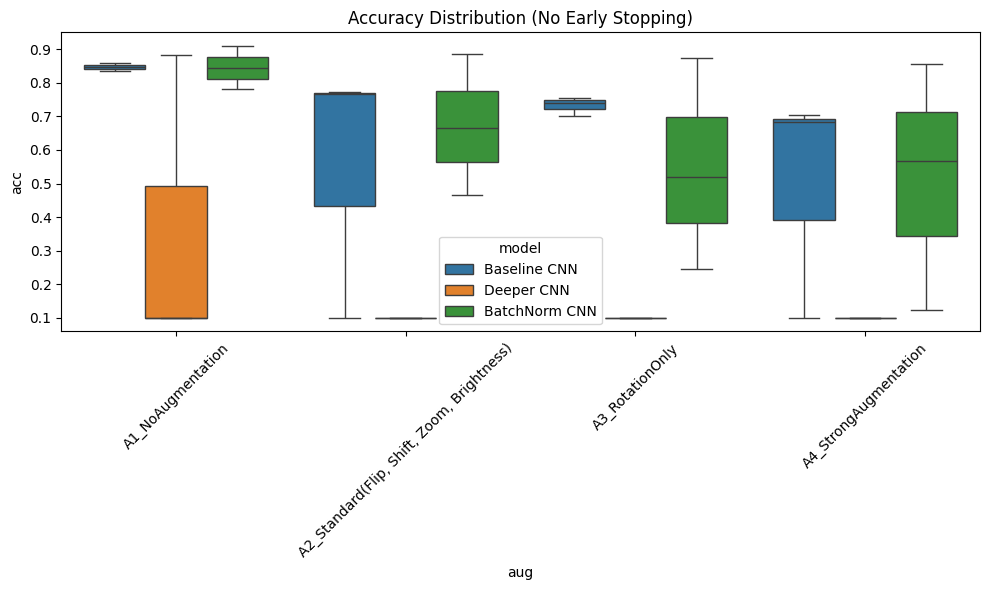

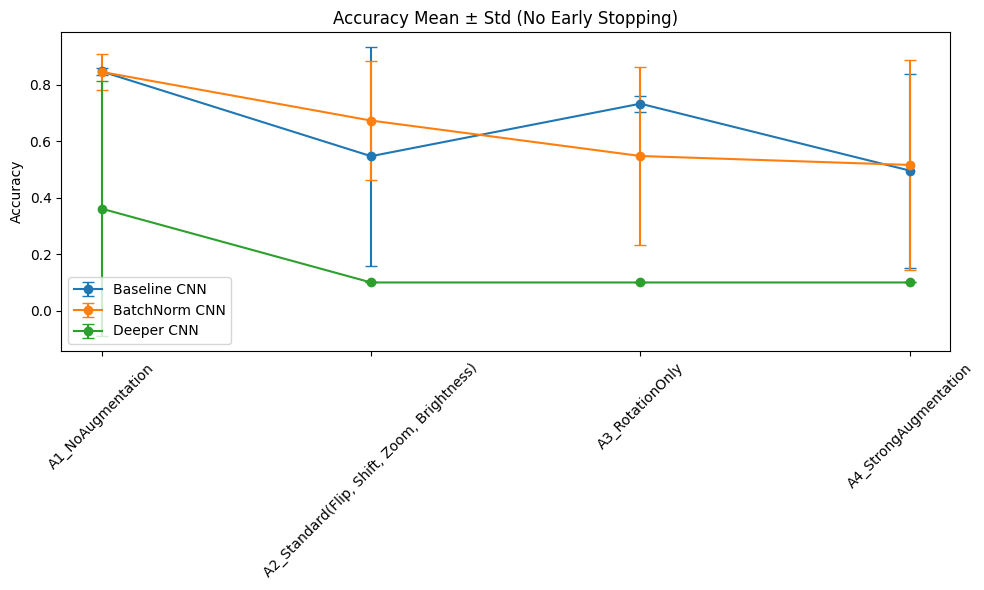

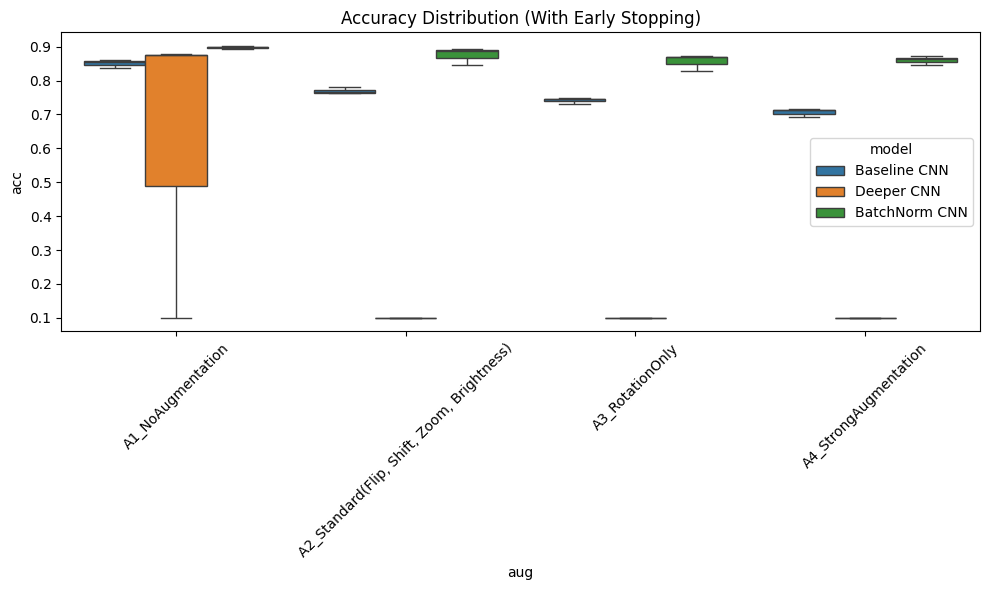

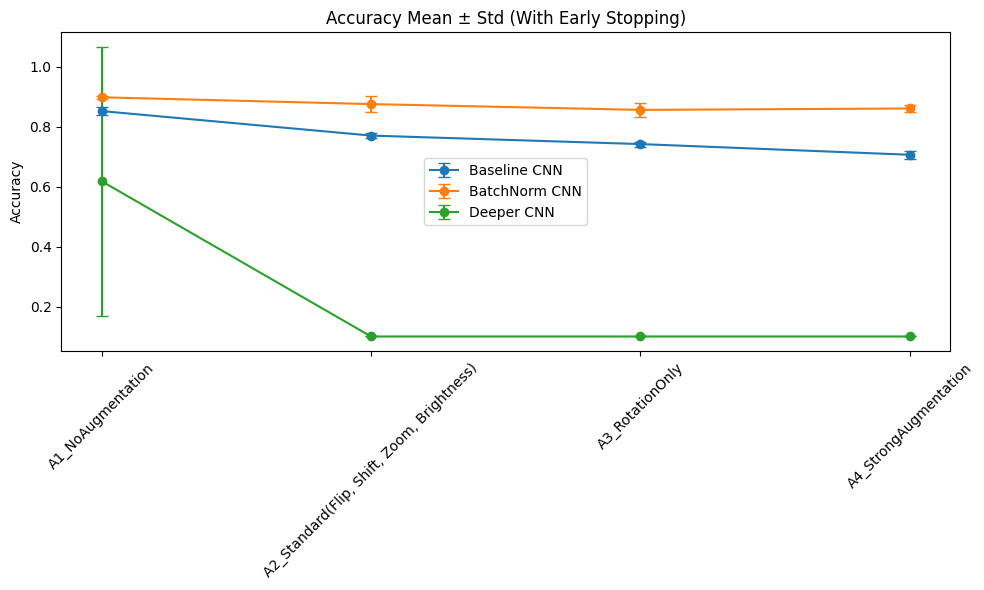

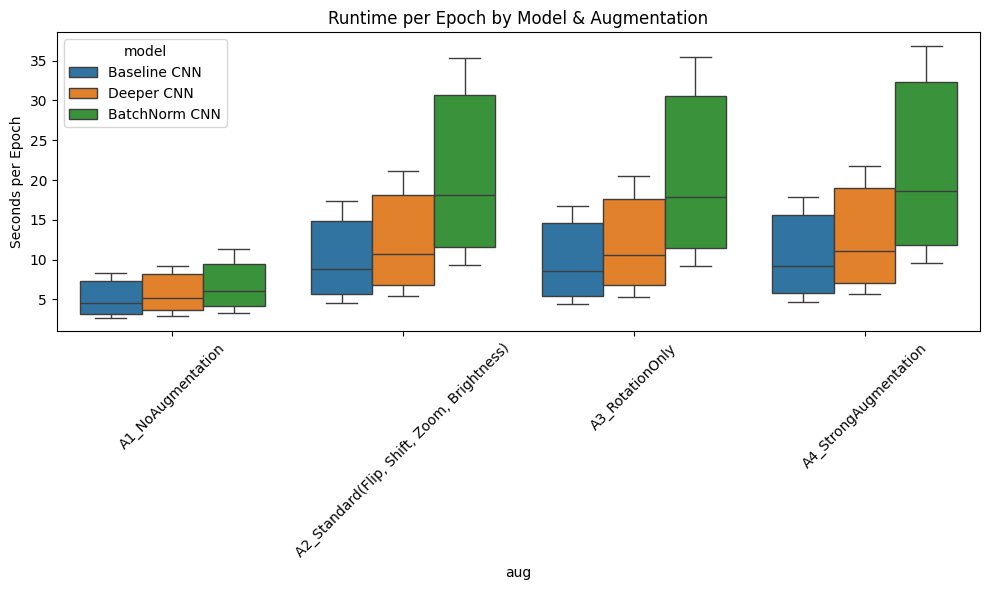


Runtime per Epoch (Mean ± Std)


,model,aug,runtime_mean,runtime_std
0,Baseline CNN,A1_NoAugmentation,5.16,2.54
1,Baseline CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",10.18,5.71
2,Baseline CNN,A3_RotationOnly,9.88,5.54
3,Baseline CNN,A4_StrongAugmentation,10.55,5.93
4,BatchNorm CNN,A1_NoAugmentation,6.79,3.39
5,BatchNorm CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",20.85,11.70
6,BatchNorm CNN,A3_RotationOnly,20.74,11.78
7,BatchNorm CNN,A4_StrongAugmentation,21.72,12.39
8,Deeper CNN,A1_NoAugmentation,5.81,2.81
9,Deeper CNN,"A2_Standard(Flip, Shift, Zoom, Brightness)",12.33,6.98


In [ ]:
# --- 6.1: Quantitative Analysis ---
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Canonicalize labels
def canon_model(s): return "Baseline CNN" if "baseline" in s.lower() else "Deeper CNN" if "deeper" in s.lower() else "BatchNorm CNN"
def canon_aug(s): return next((a for a in ["A1_NoAugmentation", "A2_Standard(Flip, Shift, Zoom, Brightness)", "A3_RotationOnly", "A4_StrongAugmentation"] if s.startswith(a[:2])), s)

df_all["model"] = df_all["model"].map(canon_model)
df_all["aug"] = df_all["aug"].map(canon_aug)


# Split by early stopping
df_fixed = df_all[df_all["early_stop"] == False]
df_es_only = df_all[df_all["early_stop"] == True]


# Table Accuracy & Macro F1 (No Early Stopping)
table_6_1 = df_fixed.groupby(["model", "aug"])[["acc", "macro_f1"]].agg(["mean", "std"]).round(3)
table_6_1.columns = ["acc_mean", "acc_std", "f1_mean", "f1_std"]
table_6_1 = table_6_1.reset_index()
print("\n Accuracy & Macro F1 (No Early Stopping)")
display(table_6_1)

# Table Accuracy & Macro F1 (With Early Stopping)
table_6_2 = df_es_only.groupby(["model", "aug"])[["acc", "macro_f1"]].agg(["mean", "std"]).round(3)
table_6_2.columns = ["acc_mean", "acc_std", "f1_mean", "f1_std"]
table_6_2 = table_6_2.reset_index()
print("\n Accuracy & Macro F1 (With Early Stopping)")
display(table_6_2)

# Figure Accuracy Distribution
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_fixed, x="aug", y="acc", hue="model")
plt.title("Accuracy Distribution (No Early Stopping)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Figure Accuracy Mean ± Std
grouped = df_fixed.groupby(["model", "aug"])["acc"].agg(["mean", "std"]).reset_index()
plt.figure(figsize=(10, 6))
for model in grouped["model"].unique():
    subset = grouped[grouped["model"] == model]
    plt.errorbar(subset["aug"], subset["mean"], yerr=subset["std"], label=model, capsize=4, marker="o")
plt.title("Accuracy Mean ± Std (No Early Stopping)")
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Accuracy Distribution (Early Stopping)
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_es_only, x="aug", y="acc", hue="model")
plt.title("Accuracy Distribution (With Early Stopping)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Accuracy Mean ± Std (Early Stopping)
grouped_es = df_es_only.groupby(["model", "aug"])["acc"].agg(["mean", "std"]).reset_index()
plt.figure(figsize=(10, 6))
for model in grouped_es["model"].unique():
    subset = grouped_es[grouped_es["model"] == model]
    plt.errorbar(subset["aug"], subset["mean"], yerr=subset["std"], label=model, capsize=4, marker="o")
plt.title("Accuracy Mean ± Std (With Early Stopping)")
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


# Figure Runtime per Epoch
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_all, x="aug", y="sec_per_epoch", hue="model")
plt.title("Runtime per Epoch by Model & Augmentation")
plt.xticks(rotation=45)
plt.ylabel("Seconds per Epoch")
plt.tight_layout()
plt.show()

# Runtime Summary
table_6_3 = df_all.groupby(["model", "aug"])["sec_per_epoch"].agg(["mean", "std"]).round(2).reset_index()
table_6_3.columns = ["model", "aug", "runtime_mean", "runtime_std"]
print("\nRuntime per Epoch (Mean ± Std)")
display(table_6_3)


## 6.2 Qualitative Analysis

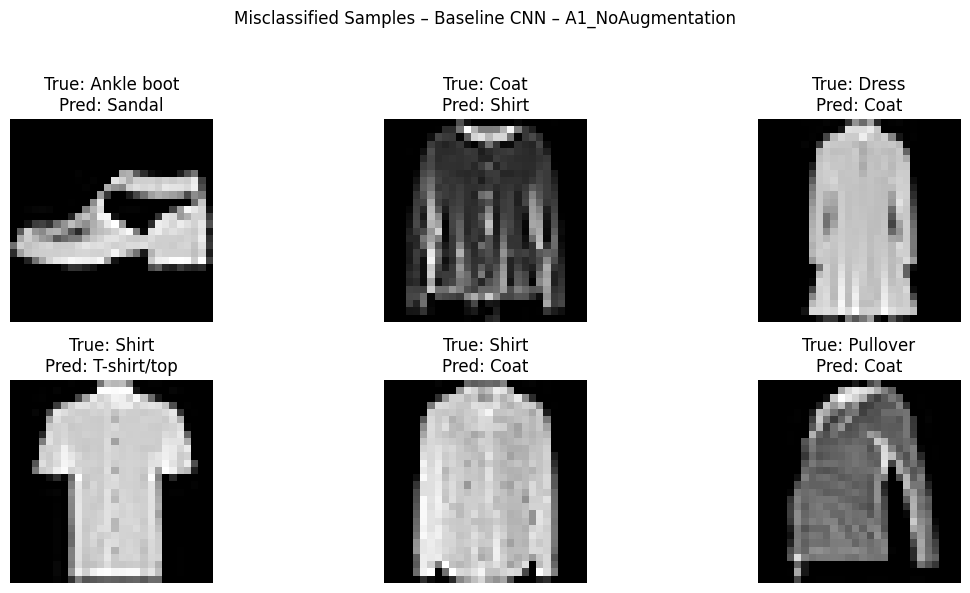

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step


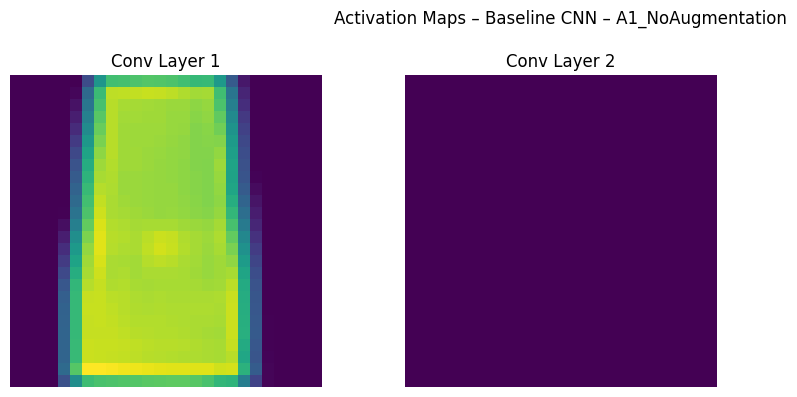

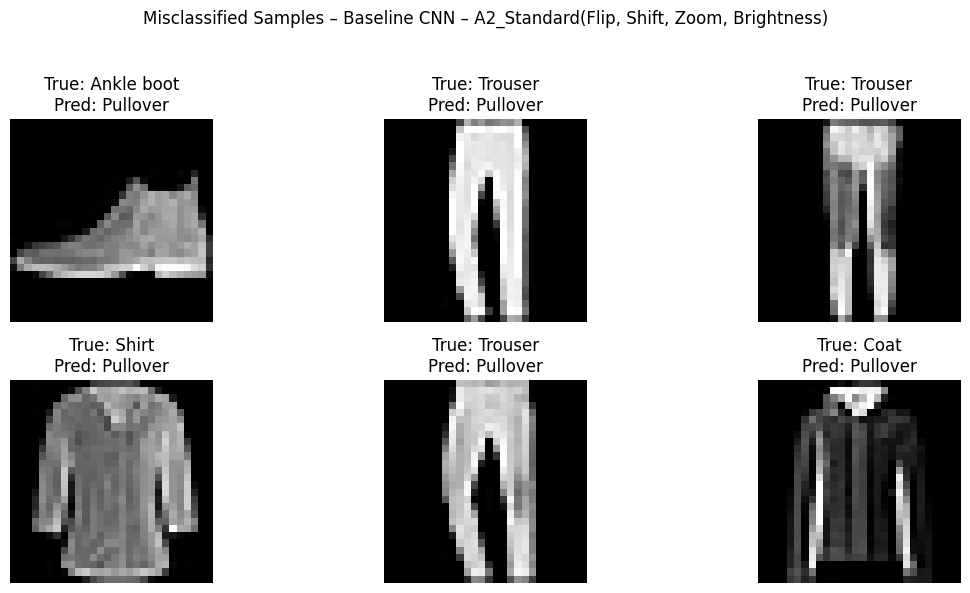

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


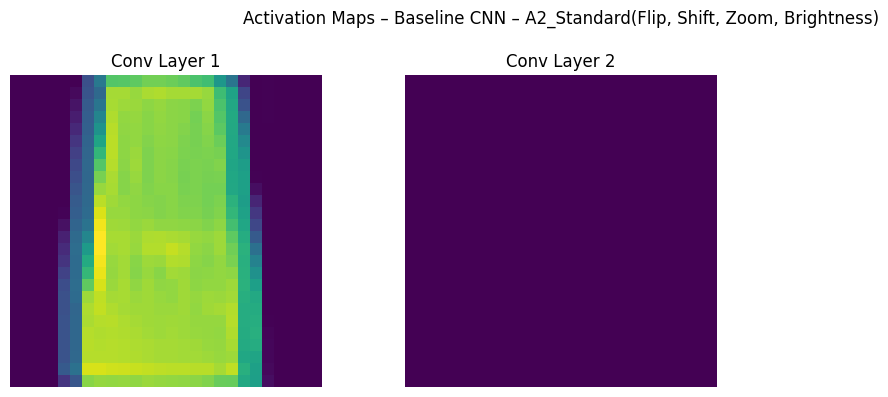

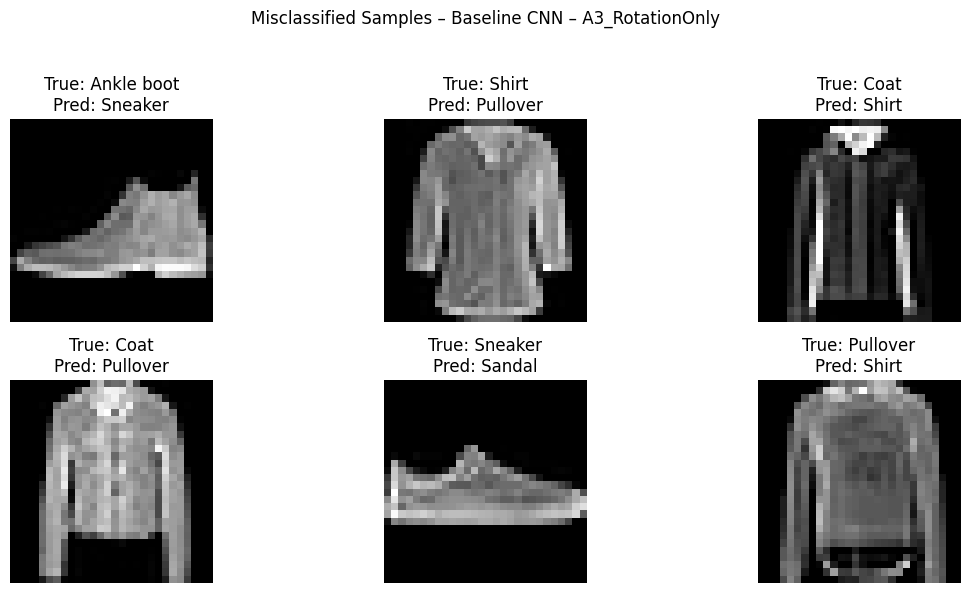

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


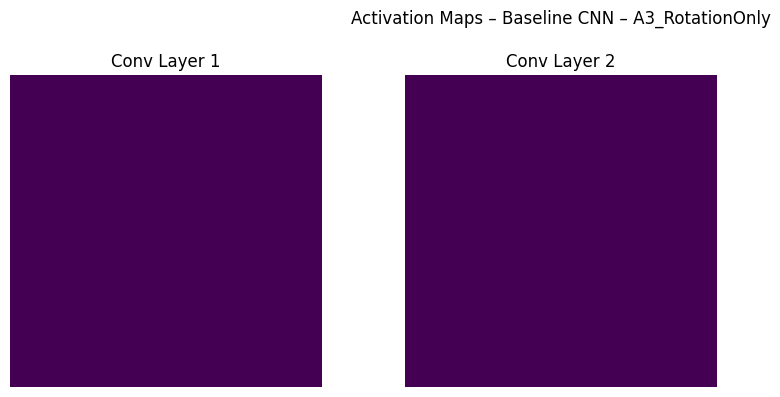

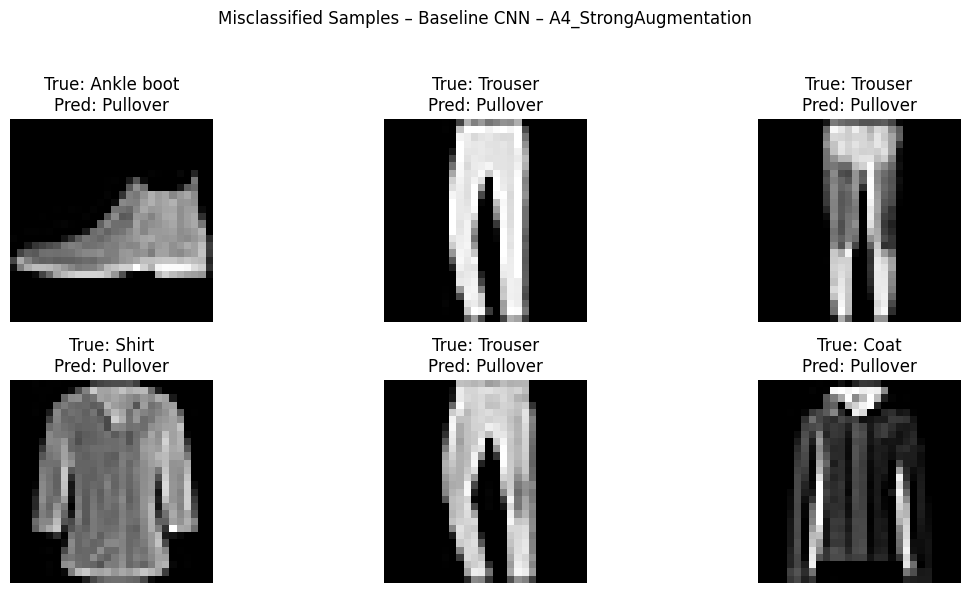

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step


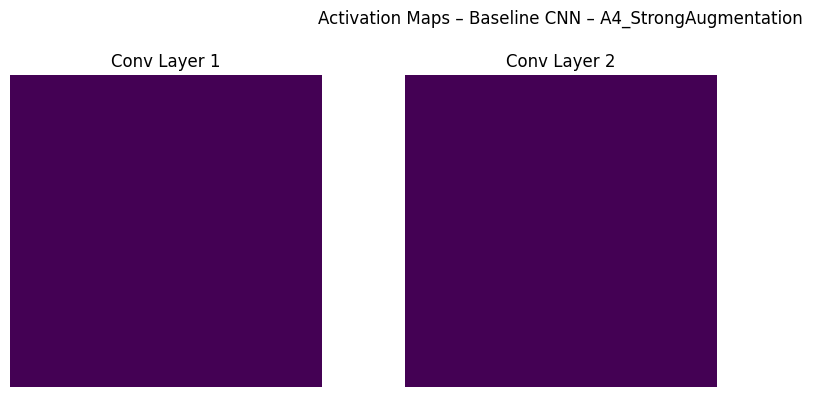

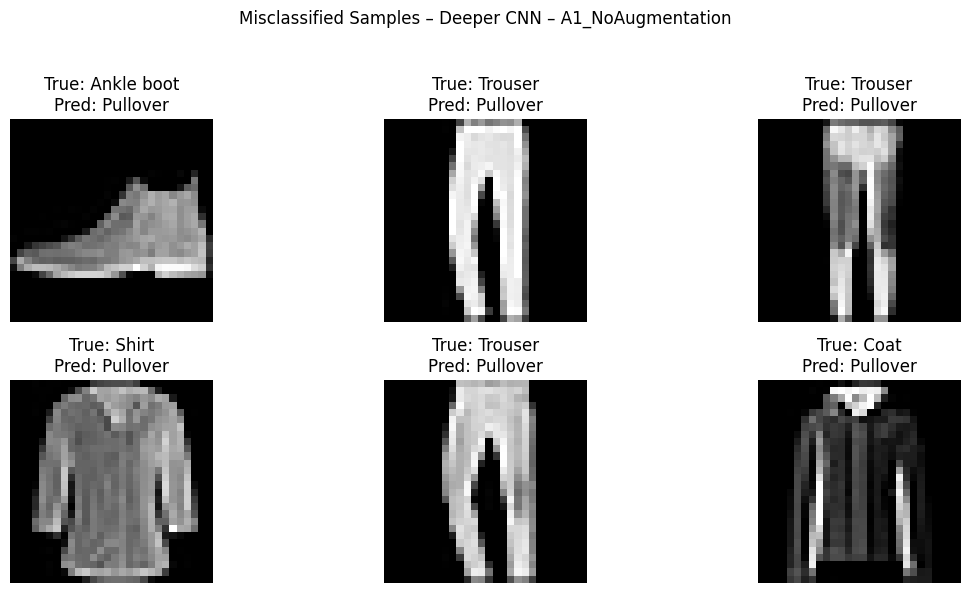

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 375ms/step


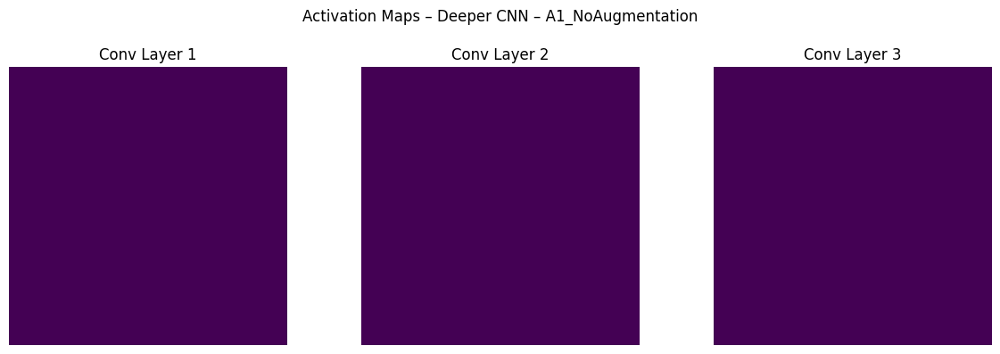

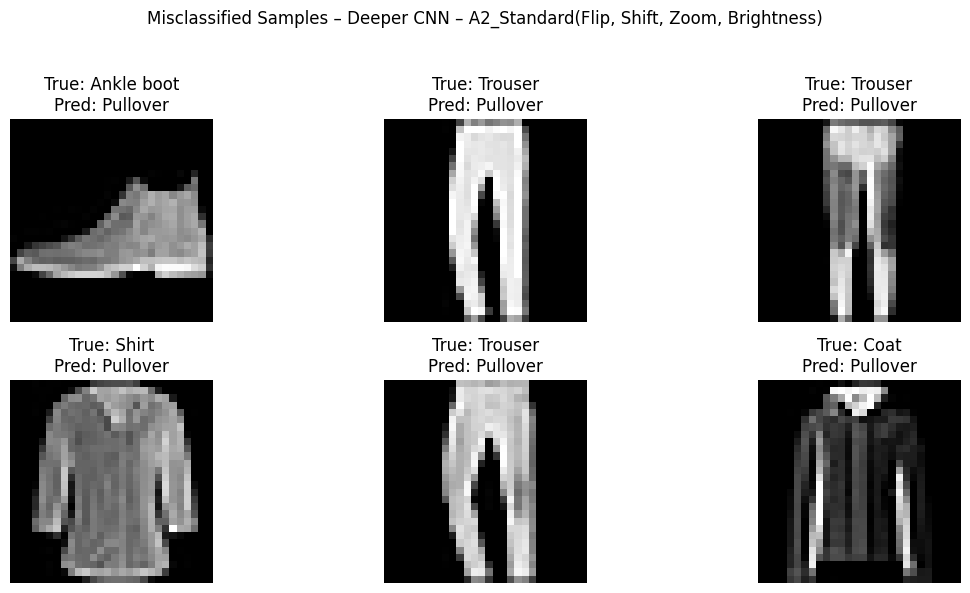

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step


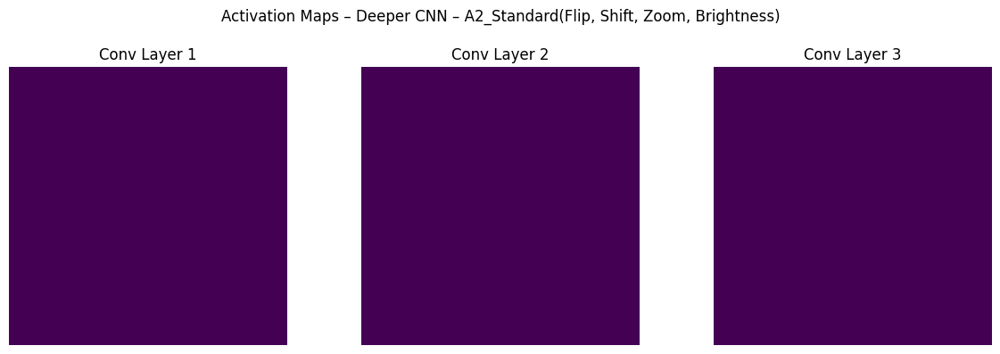

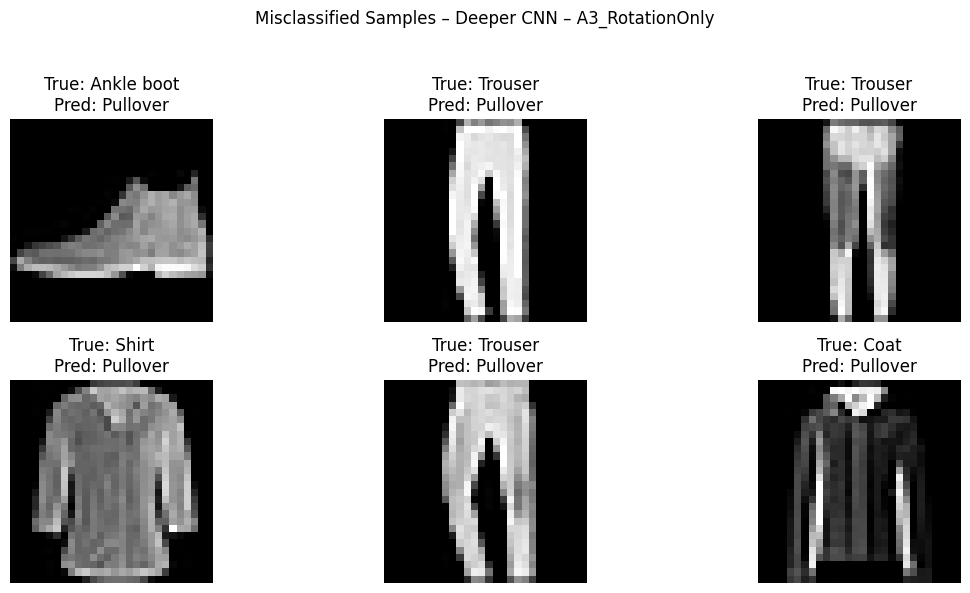

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


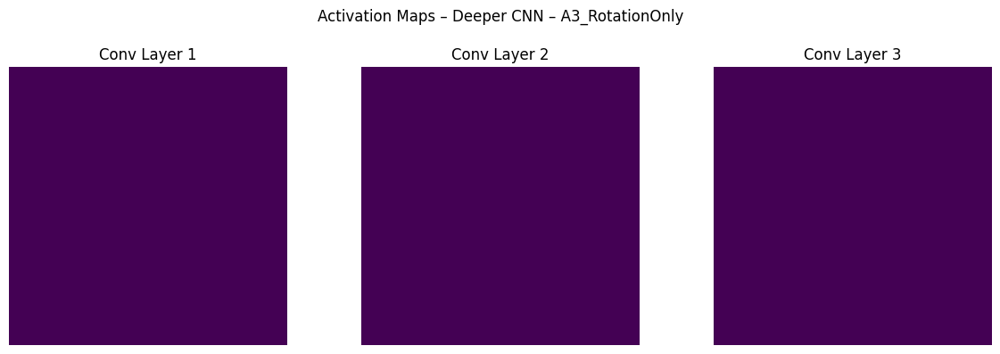

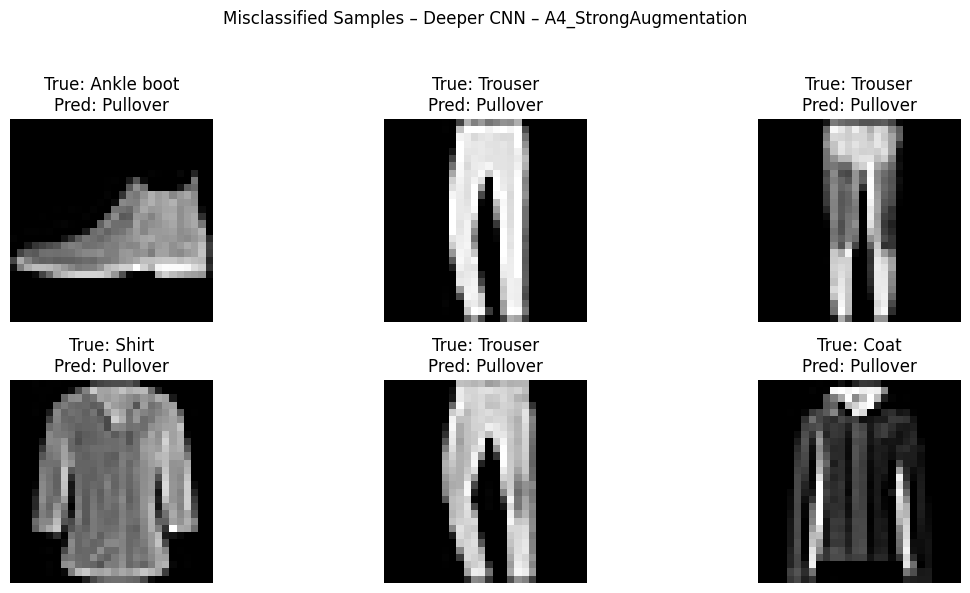

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step


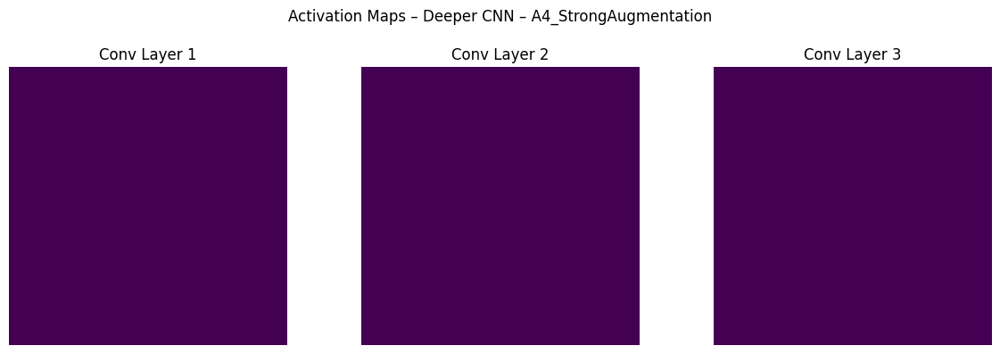

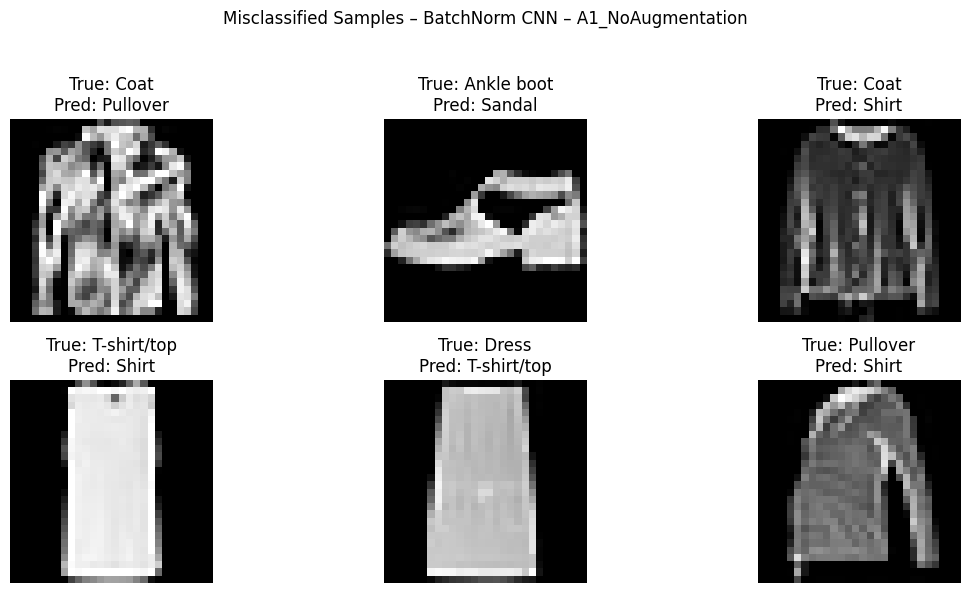

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 540ms/step


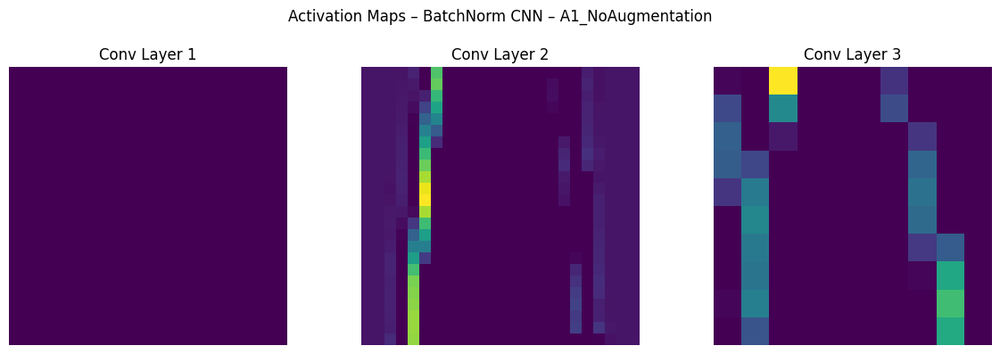

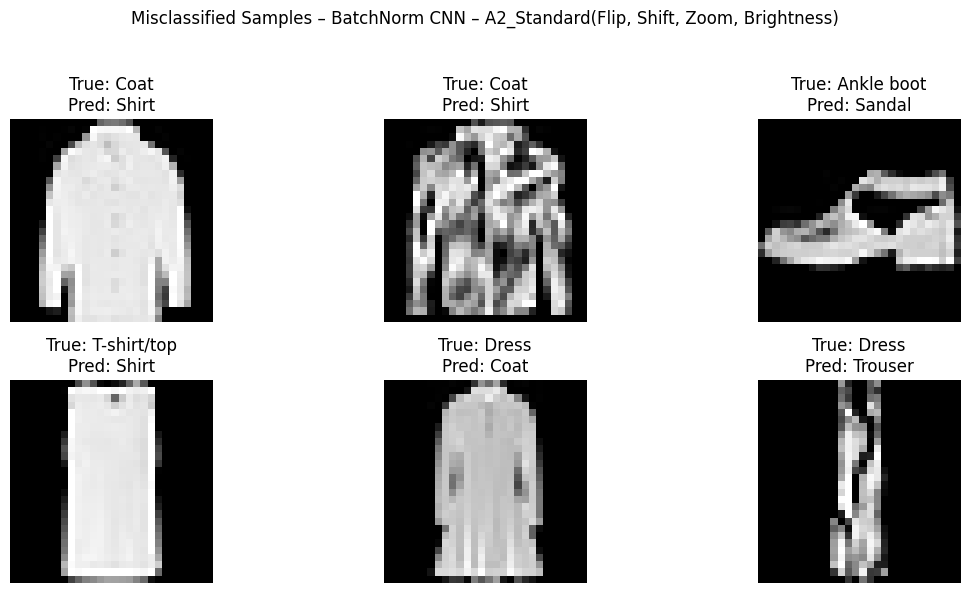

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step


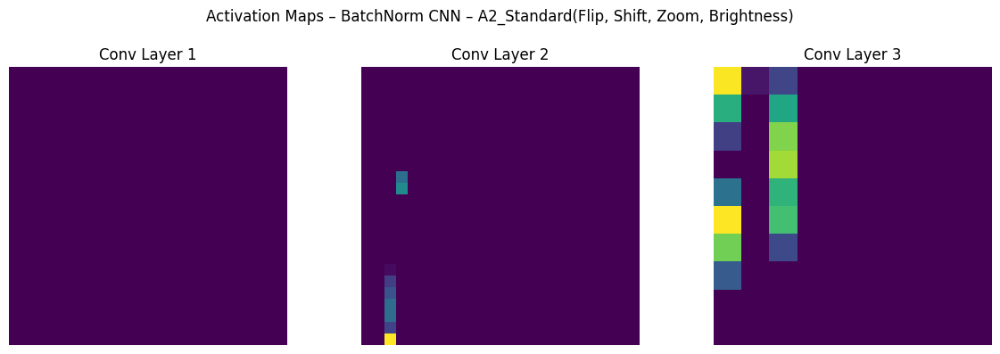

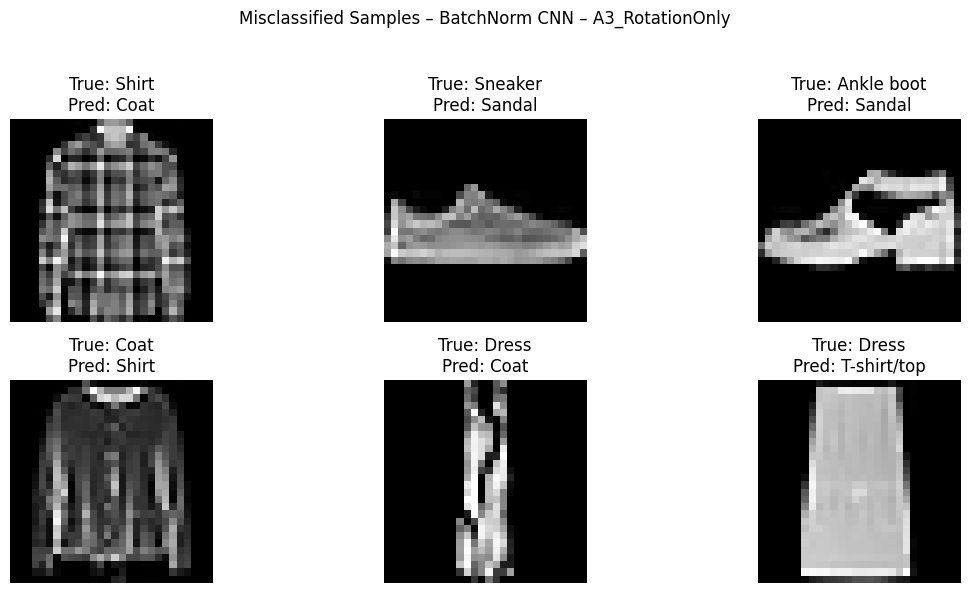

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step


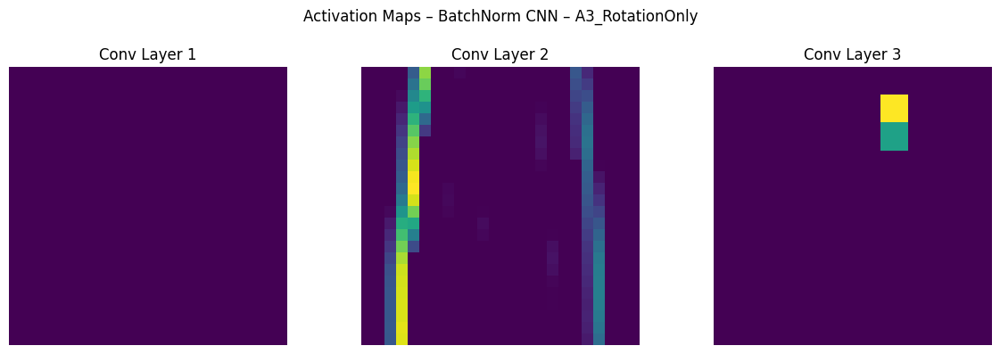

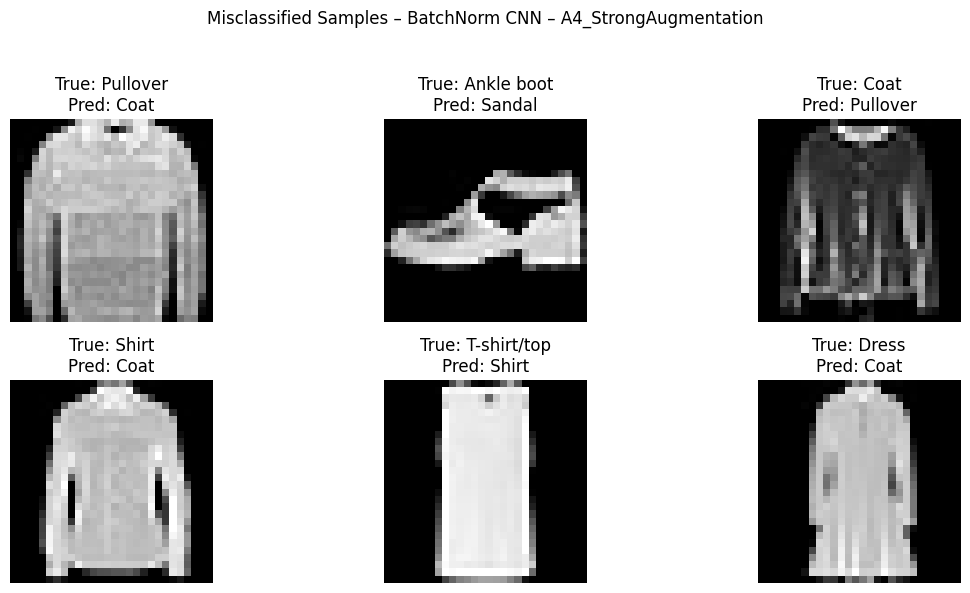

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step


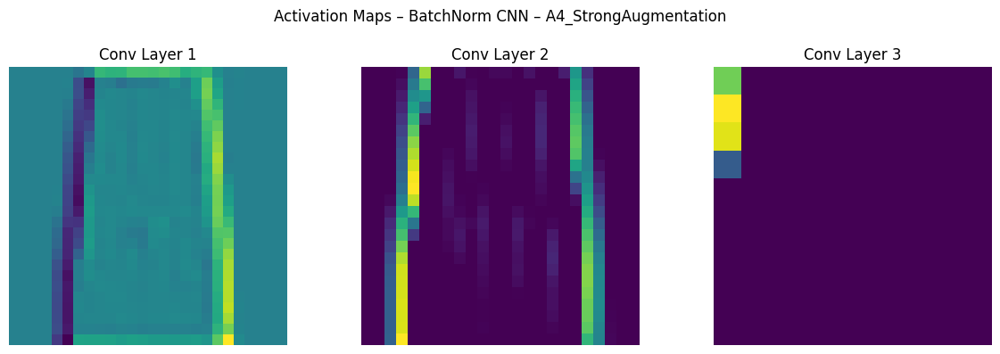

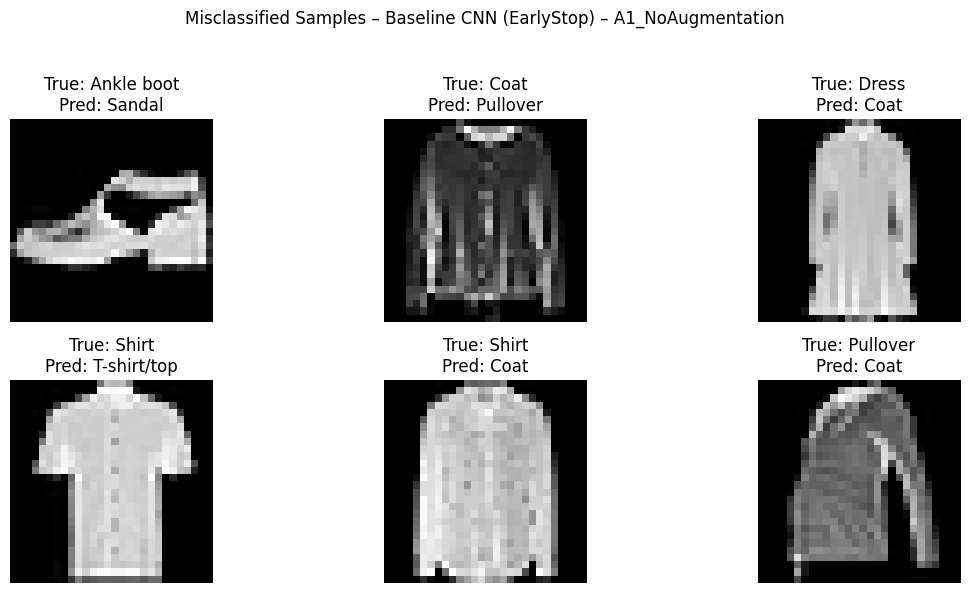

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step


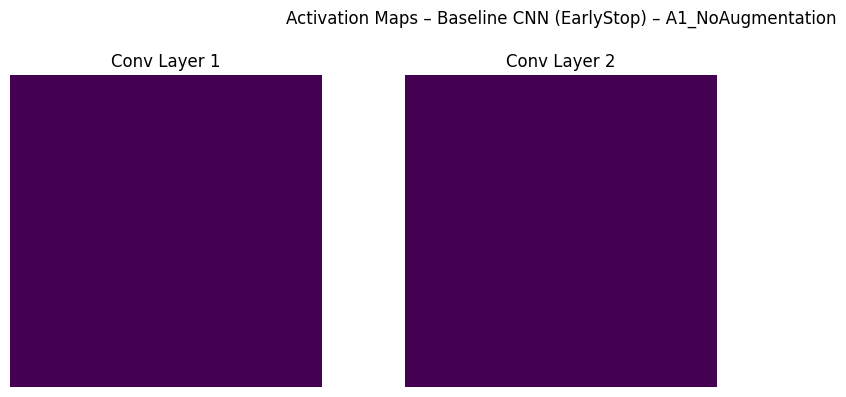

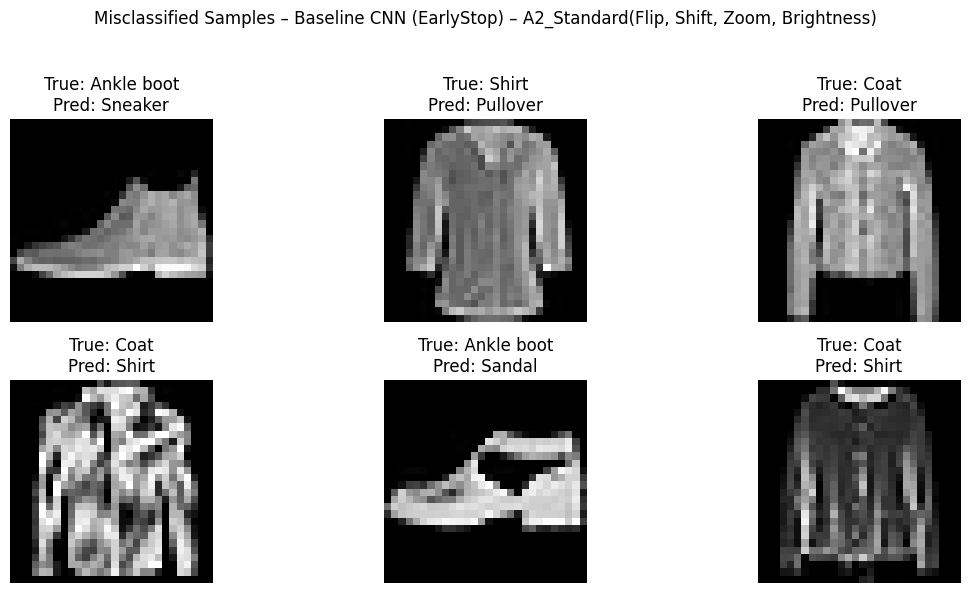

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step


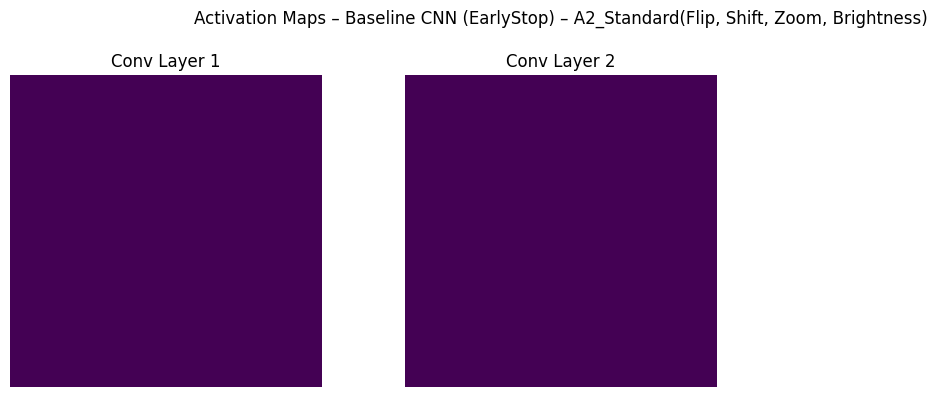

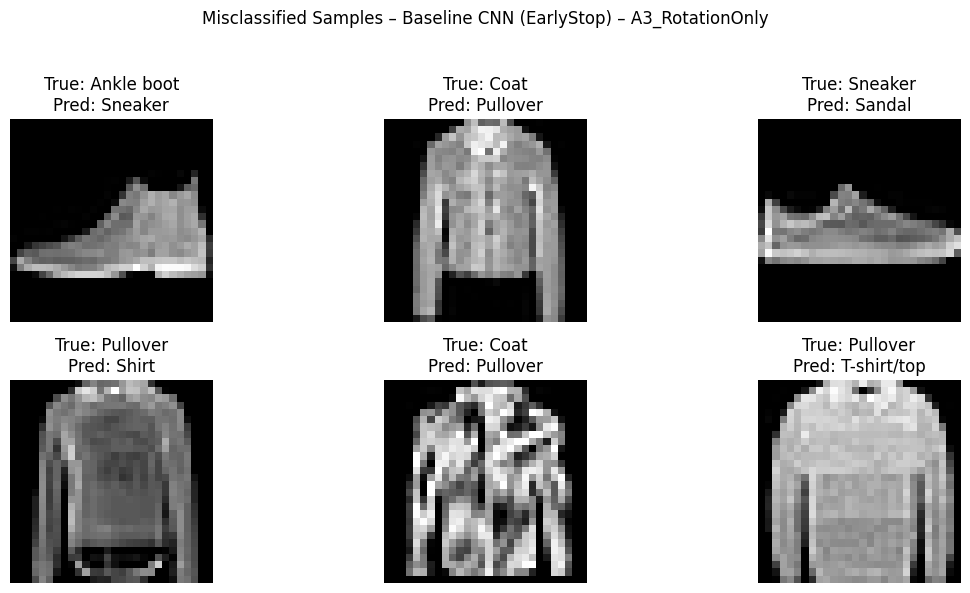

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


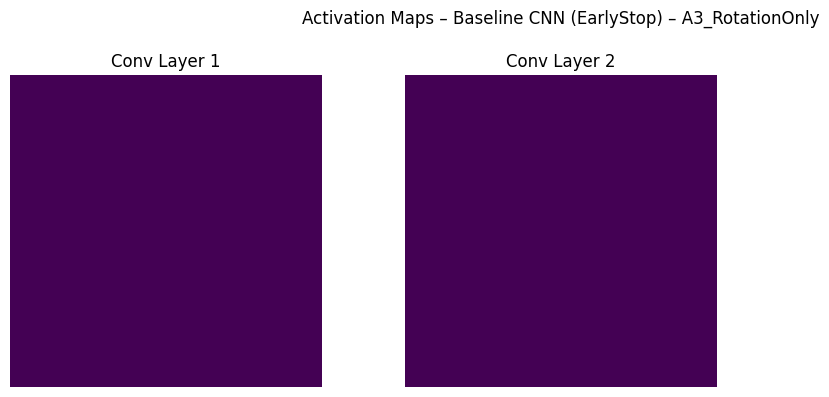

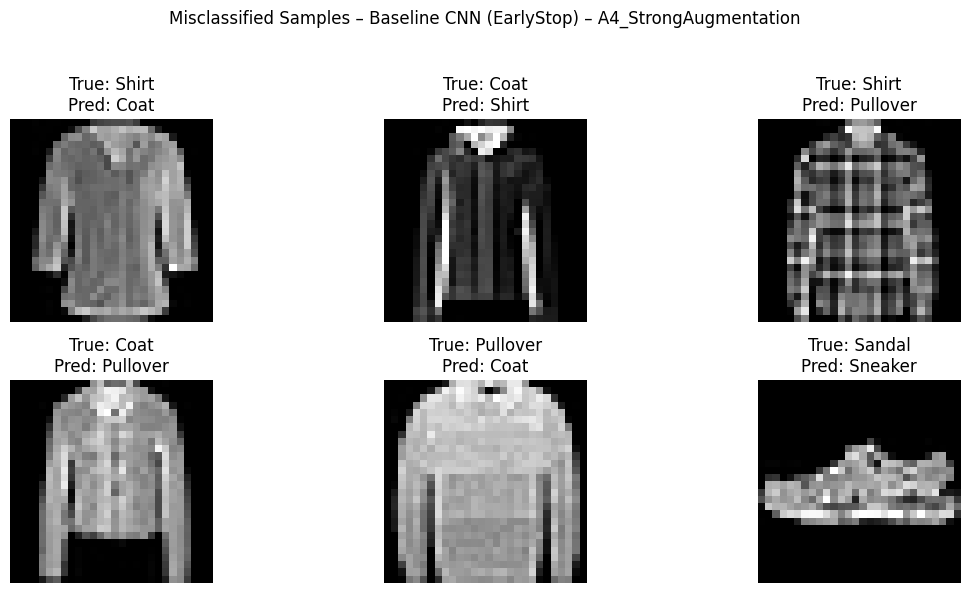

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


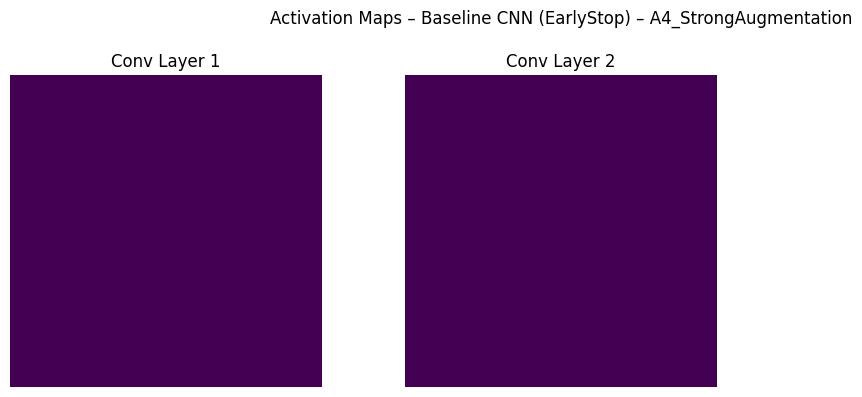

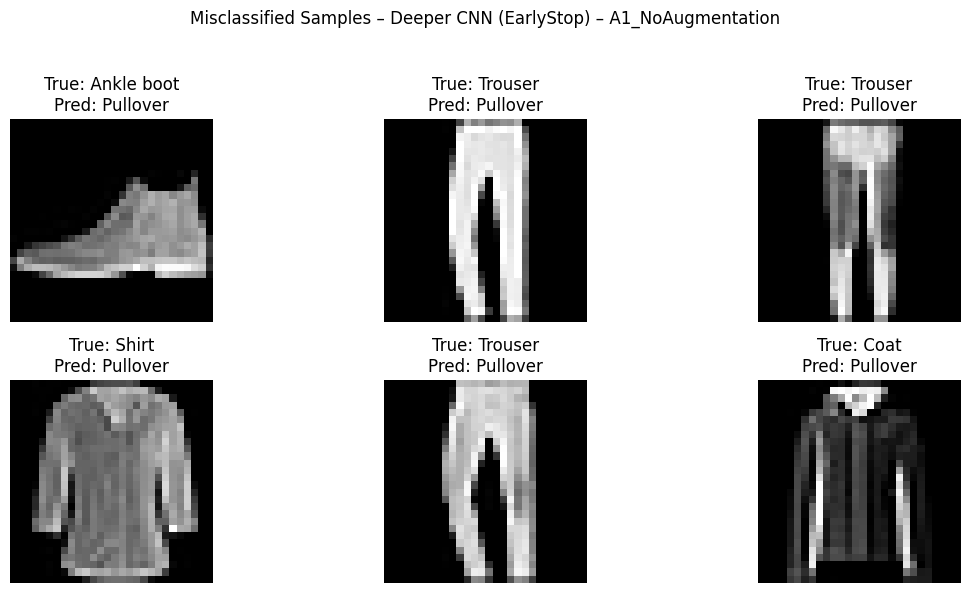

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step


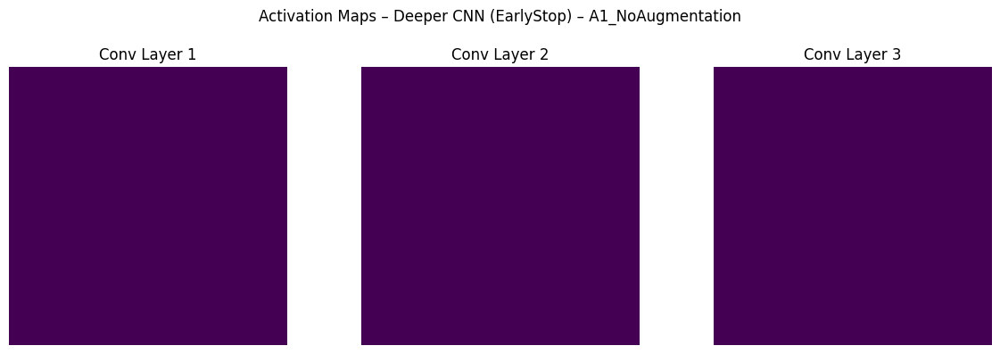

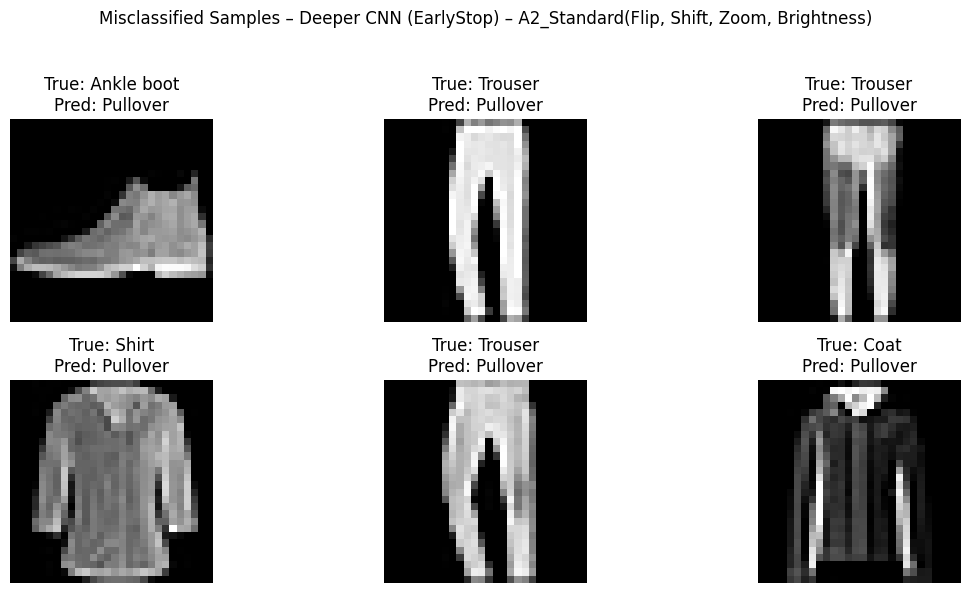

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


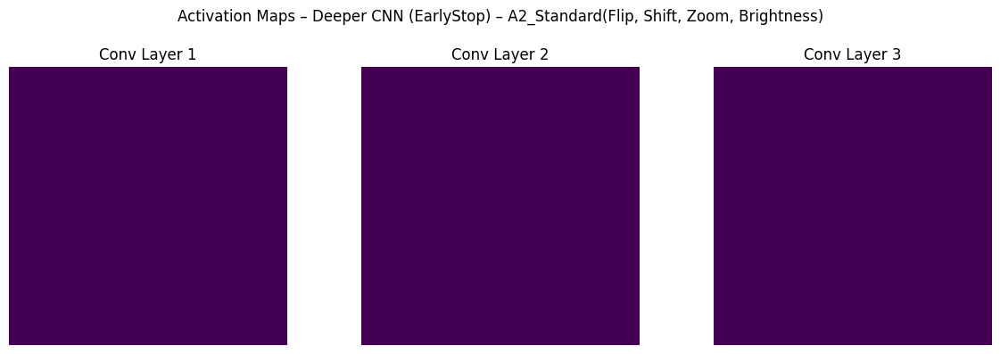

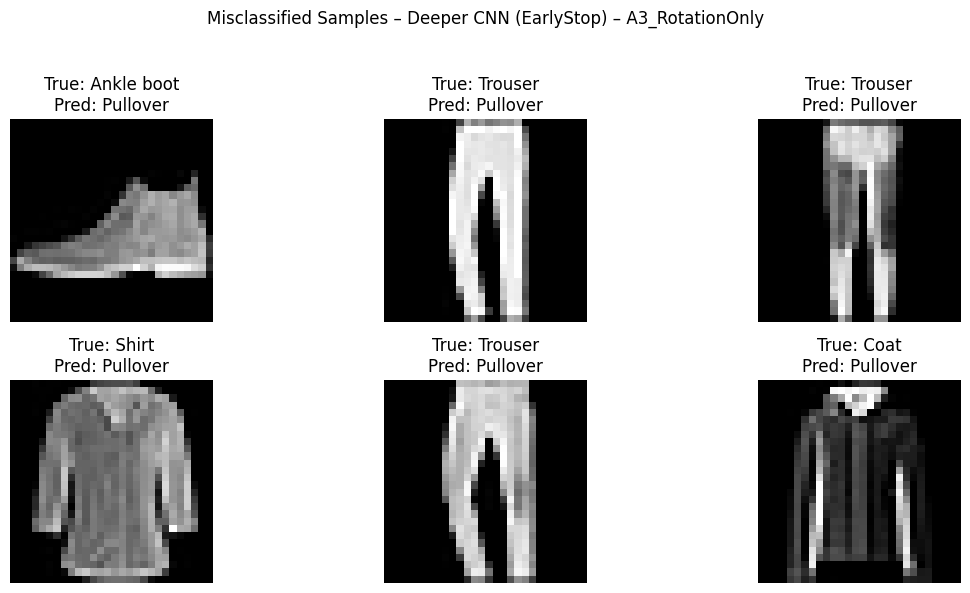

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


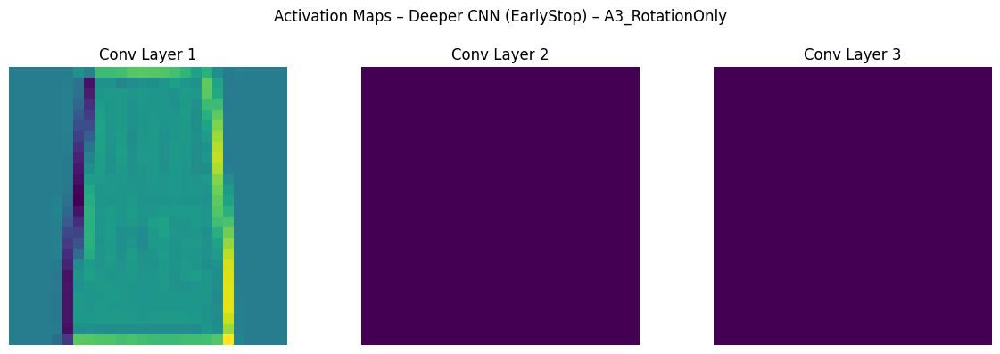

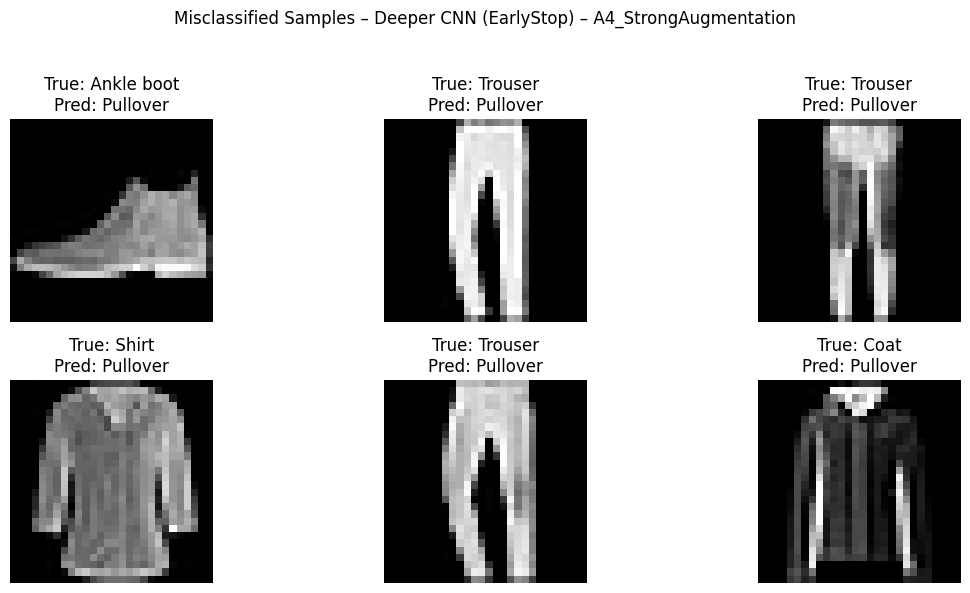

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


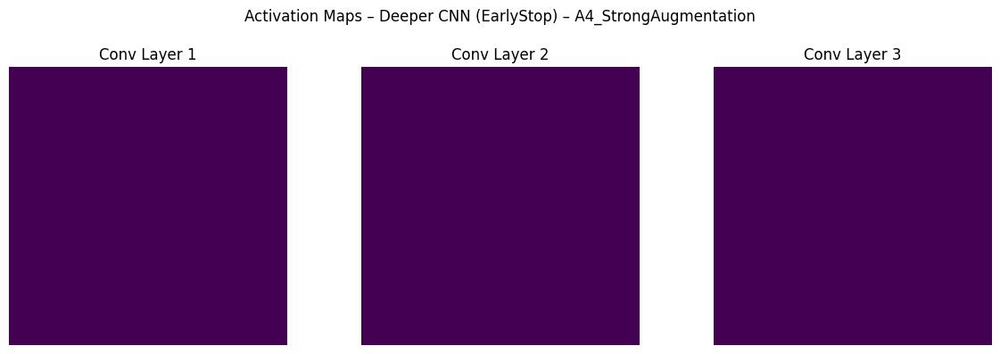

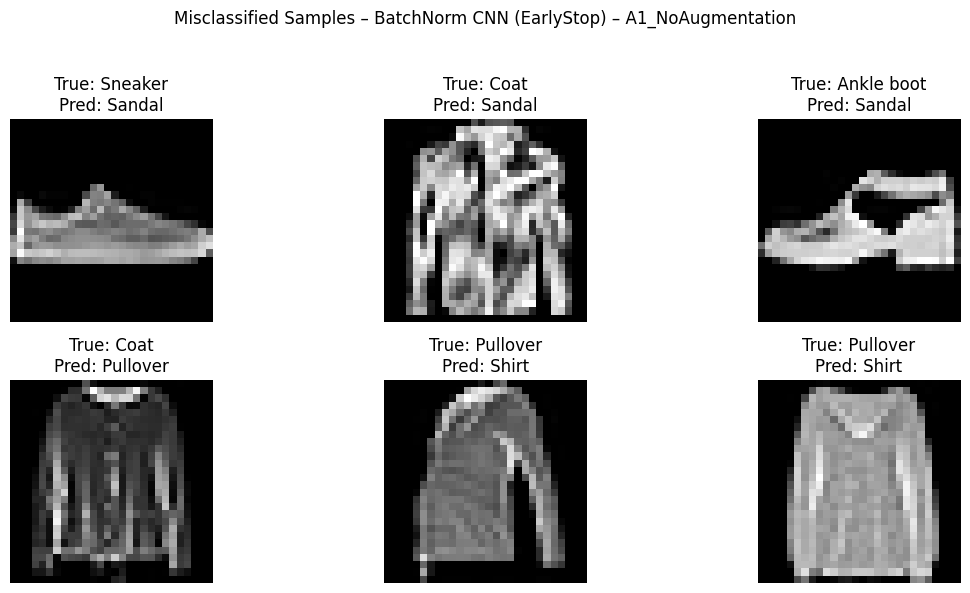

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 524ms/step


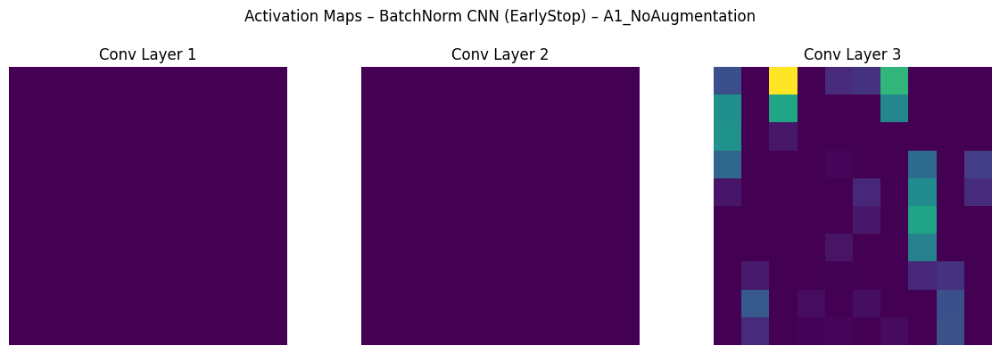

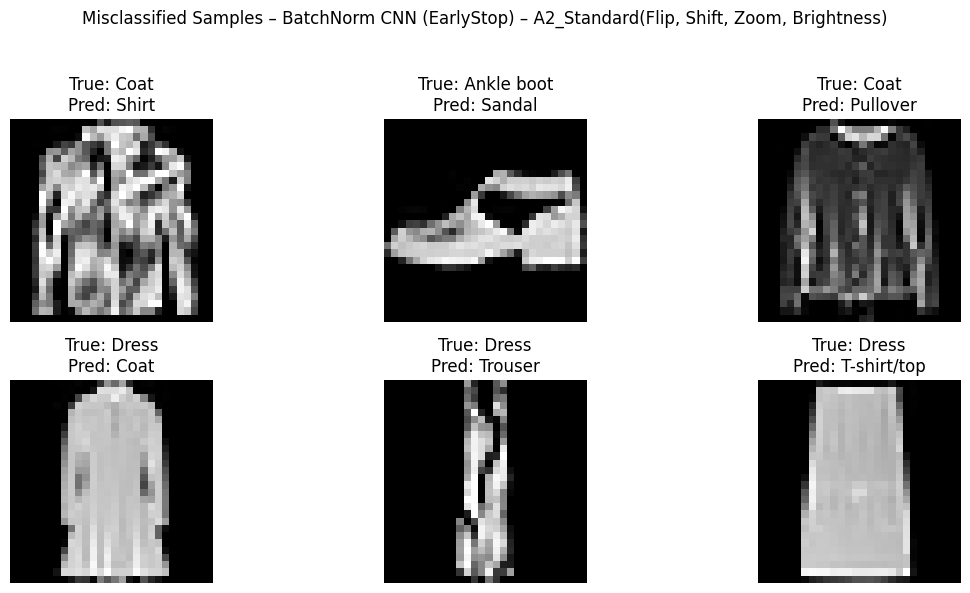

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step


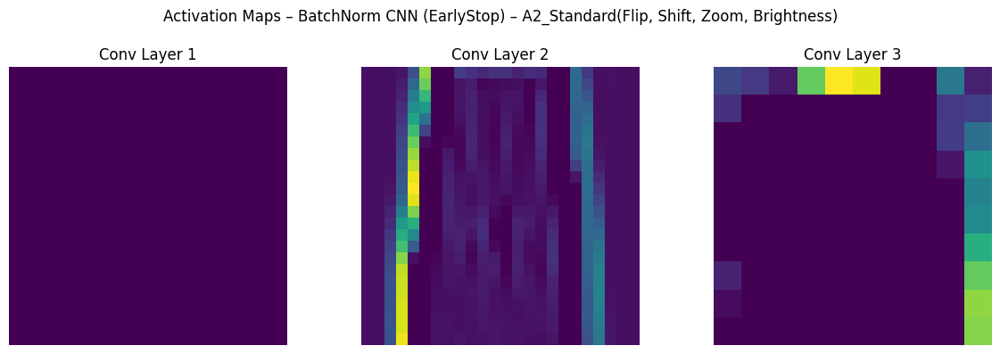

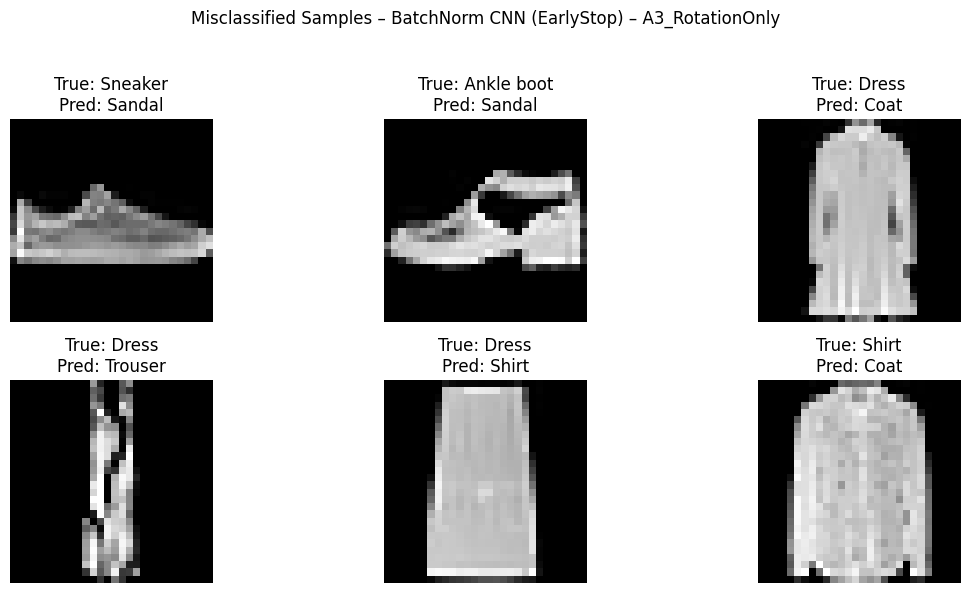

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step


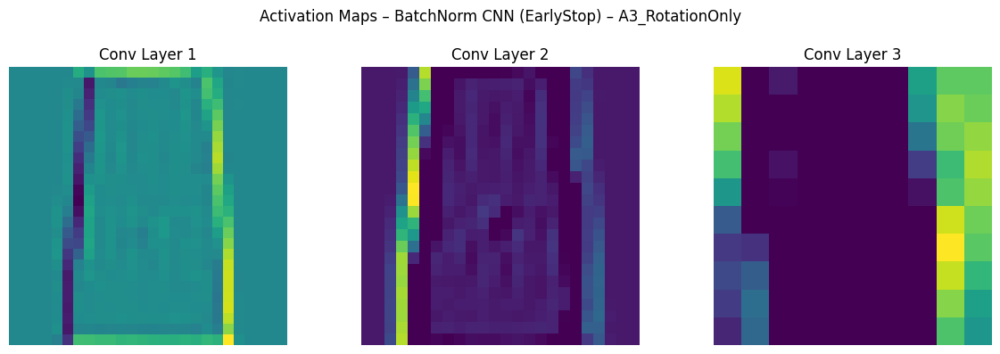

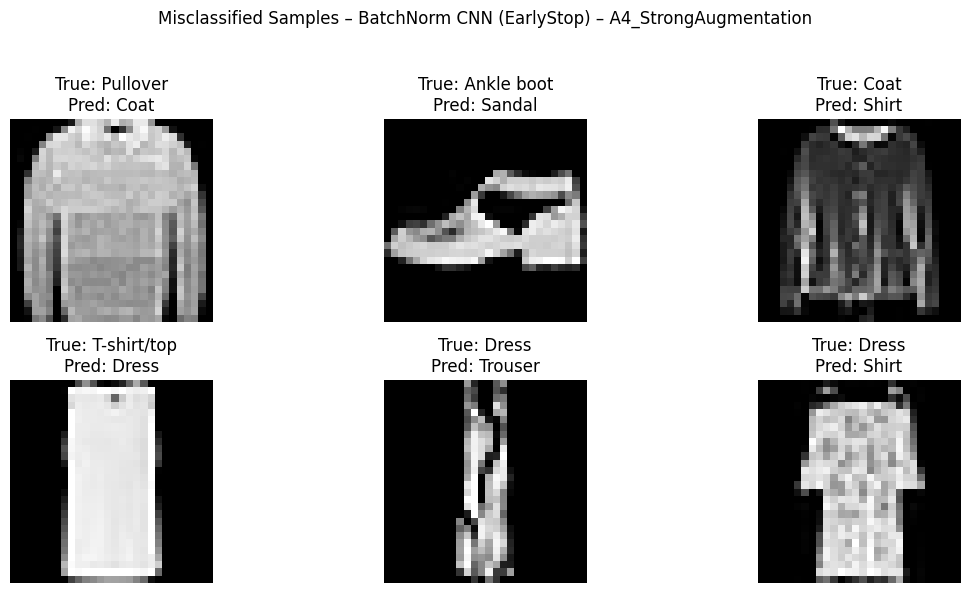

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step


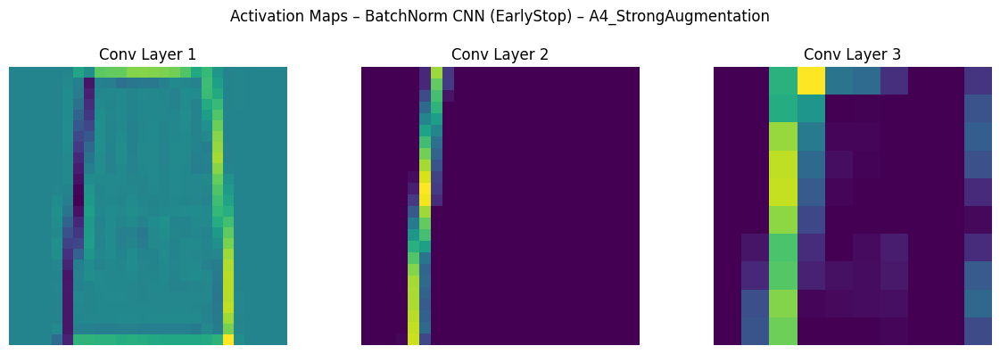

In [ ]:
# --- 6.2: Qualitative Analysis ---
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Model

# Misclassified Samples
def show_misclassified_samples(model, model_name, aug_name, x_data, y_true, class_names, max_samples=6):
    y_pred = model.predict(x_data, verbose=0).argmax(axis=1)
    mis_idx = np.where(y_true != y_pred)[0]
    if len(mis_idx) == 0:
        print(f"No misclassified samples for {model_name} – {aug_name}")
        return
    plt.figure(figsize=(12, 6))
    for i, idx in enumerate(mis_idx[:max_samples]):
        plt.subplot(2, max_samples // 2, i + 1)
        plt.imshow(x_data[idx].squeeze(), cmap="gray")
        plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=12)
        plt.axis("off")
    plt.suptitle(f"Misclassified Samples – {model_name} – {aug_name}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

# Activation Maps
def show_activation_maps(model, model_name, aug_name, image):
    if image.ndim == 3:
        image = np.expand_dims(image, axis=0)  # shape: (1, 28, 28, 1)
    layer_outputs = [layer.output for layer in model.layers if "conv" in layer.name]
    if not layer_outputs:
        print(f"No convolutional layers found in {model_name} – {aug_name}")
        return
    activation_model = Model(inputs=model.input, outputs=layer_outputs)
    activations = activation_model.predict(image)
    plt.figure(figsize=(12, 4))
    for i, act in enumerate(activations[:3]):
        plt.subplot(1, 3, i + 1)
        plt.imshow(act[0, :, :, 0], cmap="viridis")
        plt.title(f"Conv Layer {i+1}", fontsize=12)
        plt.axis("off")
    plt.suptitle(f"Activation Maps – {model_name} – {aug_name}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

df_all = df_all[df_all["seed"] == 42].drop_duplicates(subset=["model", "aug", "early_stop"])

# Loop through df_all and visualize
for _, row in df_all.iterrows():
    try:
        model_name = row["model"]
        aug_name = row["aug"]
        if row["early_stop"]:
            model_name += " (EarlyStop)"
        key = (model_name, aug_name)
        model = global_trained_models.get(key)
        if model is None:
            print(f"Model not found for key: {key}")
            continue

        # Ensure x_test has correct shape
        if x_test.ndim == 3:
            x_test = np.expand_dims(x_test, -1)

        # Show misclassified samples
        show_misclassified_samples(model, model_name, aug_name, x_test, y_test, class_names)

        # Show activation maps for a sample image
        show_activation_maps(model, model_name, aug_name, x_test[42])
    except Exception as e:
        print(f"Error for {key}: {e}")


### 6.3 Comparative Summary

Comparative Summary: Accuracy, Macro F1, and Gap


acc         \
                                                           mean    std   
model         aug                                                        
Baseline CNN  A1_NoAugmentation                           0.849  0.011   
              A2_Standard(Flip, Shift, Zoom, Brightness)  0.658  0.274   
              A3_RotationOnly                             0.737  0.019   
              A4_StrongAugmentation                       0.601  0.246   
BatchNorm CNN A1_NoAugmentation                           0.871  0.050   
              A2_Standard(Flip, Shift, Zoom, Brightness)  0.774  0.174   
              A3_RotationOnly                             0.701  0.262   
              A4_StrongAugmentation                       0.688  0.301   
Deeper CNN    A1_NoAugmentation                           0.489  0.427   
              A2_Standard(Flip, Shift, Zoom, Brightness)  0.100  0.000   
              A3_RotationOnly                             0.100  0.000   
              A4_StrongAugmentation                       0.100  0.000   

                                                         macro_f1         \
                                                             mean    std   
model         aug                                                          
Baseline CNN  A1_NoAugmentation                             0.848  0.011   
              A2_Standard(Flip, Shift, Zoom, Brightness)    0.645  0.307   
              A3_RotationOnly                               0.737  0.019   
              A4_StrongAugmentation                         0.585  0.278   
BatchNorm CNN A1_NoAugmentation                             0.870  0.051   
              A2_Standard(Flip, Shift, Zoom, Brightness)    0.771  0.178   
              A3_RotationOnly                               0.678  0.296   
              A4_StrongAugmentation                         0.669  0.334   
Deeper CNN    A1_NoAugmentation                             0.449  0.472   
              A2_Standard(Flip, Shift, Zoom, Brightness)    0.018  0.000   
              A3_RotationOnly                               0.018  0.000   
              A4_StrongAugmentation                         0.018  0.000   

                                                            gap         
                                                           mean    std  
model         aug                                                       
Baseline CNN  A1_NoAugmentation                           0.005  0.002  
              A2_Standard(Flip, Shift, Zoom, Brightness) -0.006  0.004  
              A3_RotationOnly                            -0.017  0.006  
              A4_StrongAugmentation                      -0.032  0.021  
BatchNorm CNN A1_NoAugmentation                           0.049  0.021  
              A2_Standard(Flip, Shift, Zoom, Brightness)  0.013  0.006  
              A3_RotationOnly                             0.014  0.005  
              A4_StrongAugmentation                       0.025  0.080  
Deeper CNN    A1_NoAugmentation                           0.016  0.018  
              A2_Standard(Flip, Shift, Zoom, Brightness)  0.000  0.001  
              A3_RotationOnly                            -0.000  0.000  
              A4_StrongAugmentation                       0.000  0.001


Best Configurations by Model (based on acc)


,model,aug,acc
0,Baseline CNN,A1_NoAugmentation,0.849000
4,BatchNorm CNN,A1_NoAugmentation,0.871167
8,Deeper CNN,A1_NoAugmentation,0.489333



Best Configurations by Model (based on macro_f1)


,model,aug,macro_f1
0,Baseline CNN,A1_NoAugmentation,0.848333
4,BatchNorm CNN,A1_NoAugmentation,0.869833
8,Deeper CNN,A1_NoAugmentation,0.448833


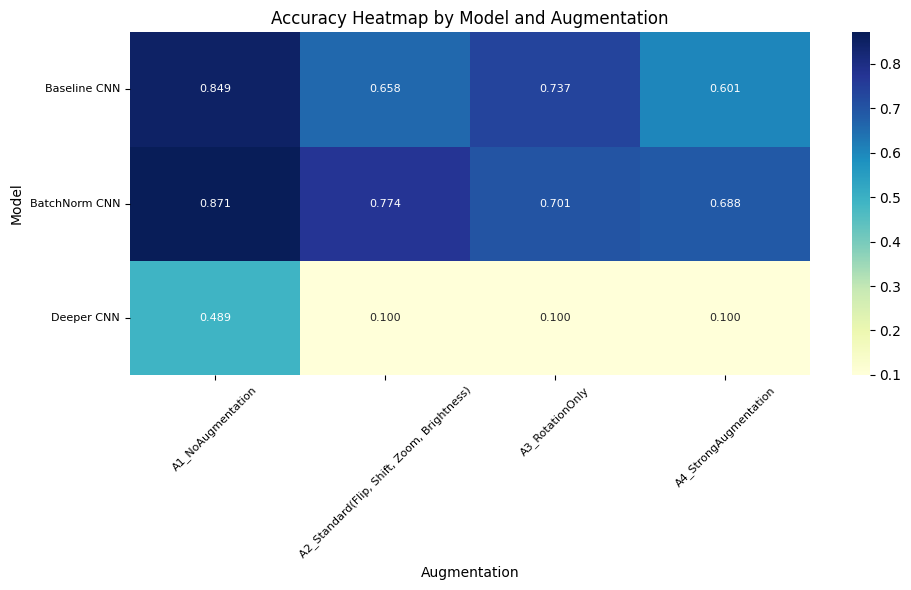

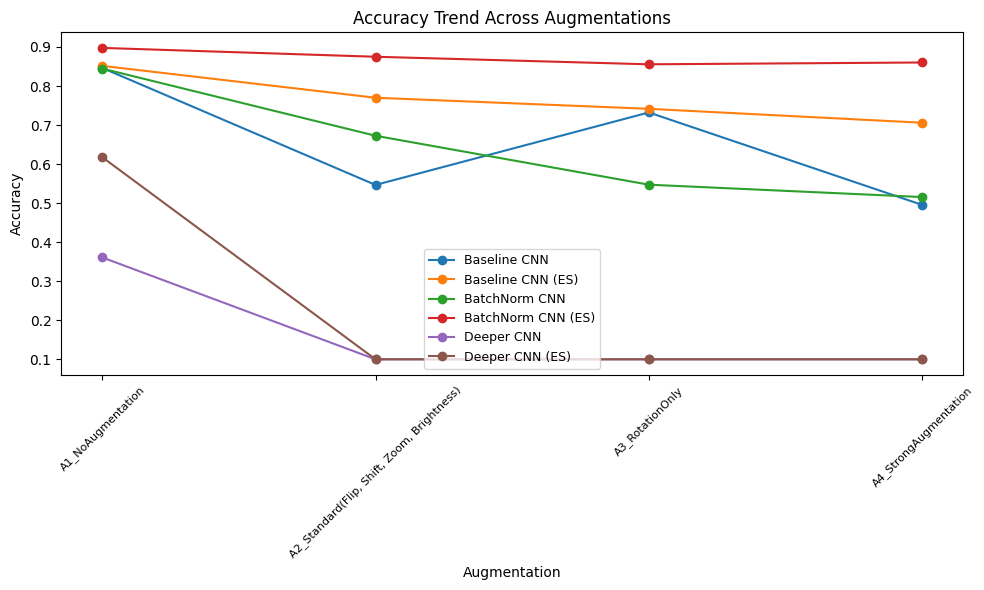

In [ ]:
# --- Part 6.3: Comparative Summary ---

# 1. Merge early-stopped and non-early-stopped results
df_all = pd.concat([df, df_es], ignore_index=True) if "df_es" in globals() else df.copy()

# Optional: distinguish early-stopped models for plotting
df_all["label"] = df_all["model"] + df_all["early_stop"].map({True: " (ES)", False: ""})

# 2. Summary table: mean ± std for each model–augmentation pair
def table_comparative_summary(df):
    grouped = df.groupby(["model", "aug"])[["acc", "macro_f1", "gap"]].agg(["mean", "std"]).round(3)
    print("Comparative Summary: Accuracy, Macro F1, and Gap")
    display(grouped)

table_comparative_summary(df_all)

# 3. Highlight best-performing configurations
def highlight_best_configs(df, metric="acc"):
    grouped = df.groupby(["model", "aug"])[metric].mean().reset_index()
    best_by_model = grouped.loc[grouped.groupby("model")[metric].idxmax()]
    print(f"\nBest Configurations by Model (based on {metric})")
    display(best_by_model)

highlight_best_configs(df_all, metric="acc")
highlight_best_configs(df_all, metric="macro_f1")

# 4. Heatmap of accuracy across models and augmentations
def plot_accuracy_heatmap(df):
    pivot = df.pivot_table(index="model", columns="aug", values="acc", aggfunc="mean")
    model_order = ["Baseline CNN", "BatchNorm CNN", "Deeper CNN"]
    pivot = pivot.loc[model_order]  # enforce consistent row order

    plt.figure(figsize=(10, 6))
    ax = sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", annot_kws={"size": 8})
    plt.title("Accuracy Heatmap by Model and Augmentation", fontsize=12)
    plt.xlabel("Augmentation", fontsize=10)
    plt.ylabel("Model", fontsize=10)
    plt.xticks(rotation=45, fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    plt.tight_layout()
    plt.show()

plot_accuracy_heatmap(df_all)

# 5. Line plot: accuracy trend across augmentations for each model variant
def plot_accuracy_trend(df):
    grouped = df.groupby(["label", "aug"])["acc"].mean().reset_index()
    plt.figure(figsize=(10, 6))
    for label in grouped["label"].unique():
        subset = grouped[grouped["label"] == label]
        plt.plot(subset["aug"], subset["acc"], marker="o", label=label)
    plt.title("Accuracy Trend Across Augmentations")
    plt.ylabel("Accuracy")
    plt.xlabel("Augmentation")
    plt.xticks(rotation=45, fontsize=8)
    plt.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

plot_accuracy_trend(df_all)
